# 🧬 자본잠식 기업의 구조적 회생 DNA 분석 — V8
## Industry Contrast DNA + CBR V2 Engine + Omni-Attribution Root-Cause + Executive Summary PDF

| 핵심 개선 (V8) | 내용 |
|---|---|
| **단위 표준화** | 천원 → 백만원 자동 변환 |
| **3단계 자본잠식** | 완전잠식 / 부분잠식 / 위험단계 분류 |
| **강화 라벨링** | 성공형: 잠식 탈출 + 3년 연속 영업이익 흑자 |
| **Industry Contrast DNA** | 클러스터별 SHAP 프로파일링 |
| **CBR V2 엔진** | Level×0.6 + Delta×0.4 가중 코사인 유사도 매칭 |
| **Waterfall 분해** | ΔNI → 영업/재무/기타 원인 자동 역추적 |
| **Omni-Attribution** | 범용 근본 원인 진단 (2σ 이상치 + 드릴다운) |
| **매출 이상 감지** | 신제품/원가절감/마케팅 원인 자동 분류 |
| **DART 세그먼트** | 제품별 매출 파싱 + 공시 이벤트 매핑 |
| **Executive Summary PDF** | PdfPages 기반 글로벌 대시보드 |
| **자동 해석** | 차트별 자동 해석 텍스트 |
| **맞춤형 추천** | 상태별 실행 가능한 권고사항 |

## 0. 환경 설정

In [1]:

# ══════════════════════════════════════════════════════════════════
# 0-A: 사용자 설정 (CONFIG) — V7
# ══════════════════════════════════════════════════════════════════
import os

# ── .env 파일 로더 (python-dotenv 불필요) ──────────────────────
def _load_dotenv(path='.env'):
    """프로젝트 루트의 .env 파일을 환경변수로 로드한다 (기존 환경변수는 덮어쓰지 않음)."""
    if not os.path.exists(path):
        return
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#') or '=' not in line:
                continue
            k, _, v = line.partition('=')
            k = k.strip()
            v = v.strip().strip('"').strip("'")
            if k and k not in os.environ:
                os.environ[k] = v

_load_dotenv()

CONFIG = {
    # ── 데이터 ──
    'DATA_PATH'       : 'SSOT_Dataset.csv',
    'QUARTER_FILTER'  : '결산',
    'UNIT_DIVISOR'    : 1000,    # 천원 -> 백만원

    # ── Phase 1: 라벨링 ──
    'TYPE_B_YEARS'    : [2022, 2023],
    'TYPE_B_EXIT_GAP' : 1,
    'POST_EXIT_MIN'   : 3,
    'SUCCESS_OI_YEARS': 3,      # 성공형: 연속 영업이익 흑자 요구 연수

    # ── Phase 2: 전처리 ──
    'WINSOR_PCTILE'   : 0.01,
    'MISS_FILL'       : 'median',

    # ── Phase 3: 클러스터링 ──
    'K_MIN'           : 2,
    'K_MAX'           : 6,
    'MIN_CLUSTER_SIZE': 10,
    'MIN_SECTOR_SIZE' : 20,
    'KMEANS_N_INIT'   : 20,
    'RANDOM_STATE'    : 42,

    # ── Phase 4: 모형 ──
    'TRAIN_YEARS'     : (2014, 2021),
    'TEST_YEARS'      : (2022, 2024),
    'GBM_N_EST'       : 300,
    'GBM_DEPTH'       : 4,
    'GBM_LR'          : 0.05,
    'CB_BETA'         : 0.9999,
    'COST_MULT'       : 4.0,
    'STABILITY_N_BOOT': 200,
    'STABILITY_THRESH': 0.6,

    # ── Phase 5: 검증 ──
    'CALIB_METHOD'    : 'sigmoid',
    'THRESHOLD'       : 0.5,
    'N_BOOT_ARI'      : 50,

    # ── Phase 6: CBR + 보고서 ──
    'CBR_TOP_K'       : 3,
    'PDF_OUTPUT'      : 'V7_Executive_Summary.pdf',
    'DART_API_KEY'    : os.environ.get('OPENDART_API_KEY', ''),
    'REPORT_TOP_N'    : 5,
}

if not CONFIG['DART_API_KEY']:
    print('[경고] OPENDART_API_KEY 미설정 — DART 연동 기능이 비활성화됩니다.')
    print('  설정 방법: 프로젝트 루트 .env 파일에 다음 줄을 추가하세요:')
    print('  OPENDART_API_KEY=your_api_key_here')
else:
    print(f'DART API 키 로드 완료 (환경변수)')

print('CONFIG V7 loaded')
for k in ['DATA_PATH','UNIT_DIVISOR','SUCCESS_OI_YEARS','CBR_TOP_K','PDF_OUTPUT']:
    print(f'   {k}: {CONFIG[k]}')


DART API 키 로드 완료 (환경변수)
CONFIG V7 loaded
   DATA_PATH: SSOT_Dataset.csv
   UNIT_DIVISOR: 1000
   SUCCESS_OI_YEARS: 3
   CBR_TOP_K: 3
   PDF_OUTPUT: V7_Executive_Summary.pdf


In [2]:
# ══════════════════════════════════════════════════════════════════
# 0-B: 라이브러리 로드
# ══════════════════════════════════════════════════════════════════
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from matplotlib import rcParams
rcParams['font.family'] = 'Malgun Gothic'
rcParams['axes.unicode_minus'] = False

from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestCentroid
from sklearn.metrics import (
    silhouette_score, adjusted_rand_score,
    classification_report, roc_auc_score, average_precision_score,
    brier_score_loss, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.utils.class_weight import compute_sample_weight

from matplotlib.backends.backend_pdf import PdfPages
from scipy.spatial.distance import cosine as cosine_dist

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print('[경고] SHAP 미설치')

from scipy.stats import bootstrap
import requests
import xml.etree.ElementTree as ET
import re, io, zipfile, time

try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output, HTML
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('[경고] ipywidgets 미설치')

print(f'Libraries loaded | Pandas: {pd.__version__} | NumPy: {np.__version__}')

Libraries loaded | Pandas: 3.0.2 | NumPy: 2.4.4


## 1. 데이터 로드 및 단위 표준화

In [3]:
# ══════════════════════════════════════════════════════════════════
# 1-A: 데이터 로드 및 단위 표준화 (천원 → 백만원)
# ══════════════════════════════════════════════════════════════════
df_raw = pd.read_csv(CONFIG['DATA_PATH'], low_memory=False)
print(f'원본: {df_raw.shape[0]:,}행 x {df_raw.shape[1]}열')

# 천원 단위 컬럼 식별 및 변환
won_cols = [c for c in df_raw.columns if '(천원)' in c]
print(f'단위 변환 대상: {len(won_cols)}개 컬럼 (천원 -> 백만원)')

for c in won_cols:
    df_raw[c] = pd.to_numeric(df_raw[c], errors='coerce') / CONFIG['UNIT_DIVISOR']

rename_map = {c: c.replace('(천원)', '(백만원)') for c in won_cols}
df_raw.rename(columns=rename_map, inplace=True)

# COL 매핑 (백만원 기준)
COL = {
    'id'       : '코드',
    'name'     : '코드명',
    'year'     : '회계연도',
    'equity'   : '자본총계(백만원)',
    'asset'    : '자산총계(백만원)',
    'debt'     : '부채총계(백만원)',
    'revenue'  : '매출액(백만원)...33',
    'op_income': '영업이익(백만원)',
    'net_income': '당기순이익(백만원)',
    'ocf'      : '영업활동으로인한현금흐름(백만원)',
    'cogs'     : '매출원가(백만원)',
    'gross'    : '매출총이익(백만원)',
    'ppe'      : '유형자산(백만원)',
    'rec'      : '매출채권(백만원)',
    'inv'      : '재고자산(백만원)',
    'int_exp'  : '이자비용(백만원)...51',
    'ret_earn' : '이익잉여금(백만원)',
    'status'   : '상장상태',
    'ebitda'   : 'EBITDA(백만원)',
    'depr'     : '감가상각비(현금흐름표)(백만원)',
}

# 컬럼 존재 확인
missing = [k for k, v in COL.items() if v not in df_raw.columns and k not in ('status',)]
if missing:
    print(f'[경고] 누락 컬럼: {missing}')
else:
    print('모든 COL 매핑 정상')

print(f'기업 수: {df_raw[COL["id"]].nunique():,}')
print(f'연도: {df_raw[COL["year"]].min()} ~ {df_raw[COL["year"]].max()}')

원본: 62,434행 x 100열
단위 변환 대상: 64개 컬럼 (천원 -> 백만원)
모든 COL 매핑 정상
기업 수: 4,281
연도: 2010 ~ 2024


In [4]:
# ══════════════════════════════════════════════════════════════════
# 1-B: 결산월 기준 연간 데이터
# ══════════════════════════════════════════════════════════════════
df = df_raw[df_raw['분기'] == CONFIG['QUARTER_FILTER']].copy()
df = df.sort_values([COL['id'], COL['year']]).reset_index(drop=True)

numeric_cols = [v for k, v in COL.items() if k not in ('id','name','year','status')]
for c in numeric_cols:
    if c in df.columns:
        df[c] = pd.to_numeric(df[c], errors='coerce')

print(f'결산 데이터: {df.shape[0]:,}행 | {df[COL["id"]].nunique():,}개 기업')

결산 데이터: 62,434행 | 4,281개 기업


## Phase 1: 3단계 자본잠식 식별 및 강화 라벨링 (V7)
### 완전잠식 / 부분잠식 / 위험단계 + 3년 연속 흑자 성공 기준

| 유형 | 정의 | 비고 |
|---|---|---|
| **완전자본잠식** | 자본총계 < 0 | 전통적 기준 |
| **부분자본잠식** | 자본총계 > 0 AND 이익잉여금 < 0 | 자본금 대리 변수 |
| **위험단계** | 3년 연속 영업이익 적자 | 잠식 전조 |

자본잠식 경험 기업: 1,064개
  완전잠식: 90
  부분잠식: 974


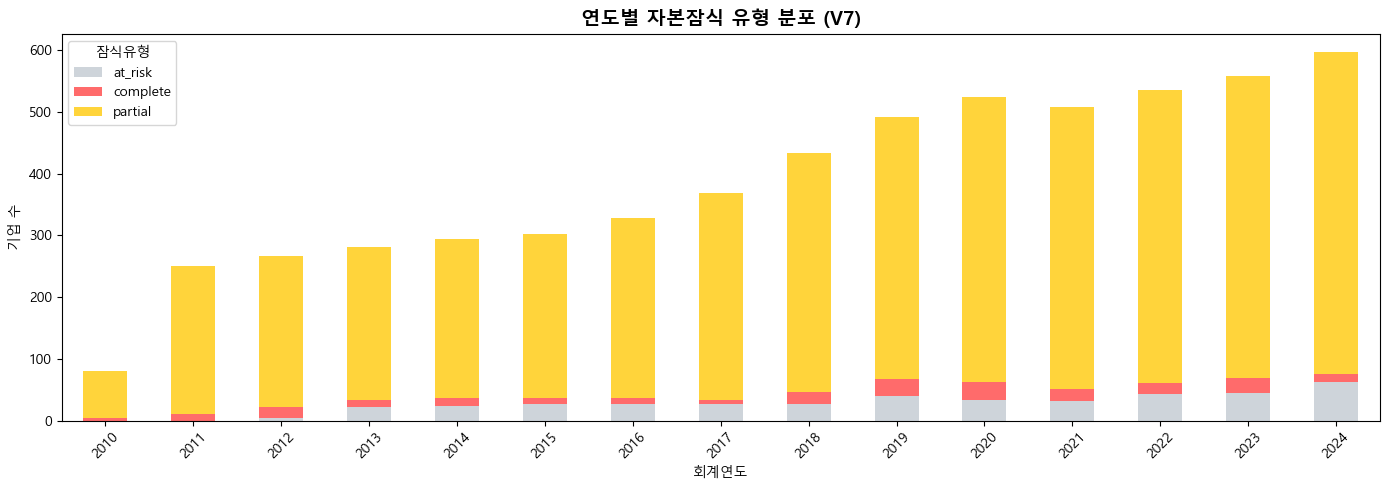


[자동 해석] 전체 4,281개 기업 중 1,064개(24.9%)가 자본잠식을 경험.
  완전잠식(90)이 최다이며, 부분잠식(974)도 포착됨.
  V7에서는 이익잉여금 < 0을 부분잠식 프록시로 활용 (자본금 컬럼 부재 대응).


In [5]:
# ══════════════════════════════════════════════════════════════════
# Phase 1-A: 3단계 자본잠식 식별 (V7)
# ══════════════════════════════════════════════════════════════════
equity = df[COL['equity']]
ret_earn = df[COL['ret_earn']]
oi = df[COL['op_income']]

# 완전자본잠식: 자본총계 < 0
df['imp_complete'] = (equity < 0).astype(int)

# 부분자본잠식: 자본총계 > 0 AND 이익잉여금 < 0
df['imp_partial'] = ((equity >= 0) & (ret_earn < 0)).astype(int)

# 위험단계: 3년 연속 영업이익 적자
df['_oi_neg'] = (oi < 0).astype(int)
df['_oi_neg_3yr'] = (
    df.groupby(COL['id'])['_oi_neg']
    .transform(lambda x: x.rolling(3, min_periods=3).sum())
)
df['imp_at_risk'] = ((df['_oi_neg_3yr'] >= 3) & (equity >= 0) & (ret_earn >= 0)).astype(int)

# 종합 잠식 상태
df['impairment_type'] = 'none'
df.loc[df['imp_at_risk'] == 1, 'impairment_type'] = 'at_risk'
df.loc[df['imp_partial'] == 1, 'impairment_type'] = 'partial'
df.loc[df['imp_complete'] == 1, 'impairment_type'] = 'complete'

# 분석 대상: 완전 또는 부분 자본잠식 경험 기업
df['is_impaired'] = df['impairment_type'].isin(['complete', 'partial'])

crisis_df = (
    df[df['is_impaired']]
    .groupby(COL['id'])[COL['year']]
    .min()
    .reset_index()
    .rename(columns={COL['year']: 'T0_year'})
)

# T0 시점 잠식 유형 기록
t0_type = df[df['is_impaired']].sort_values([COL['id'], COL['year']])
t0_type = t0_type.groupby(COL['id']).first()['impairment_type'].reset_index()
t0_type.columns = [COL['id'], 'T0_imp_type']
crisis_df = crisis_df.merge(t0_type, on=COL['id'], how='left')

print(f'자본잠식 경험 기업: {len(crisis_df):,}개')
print(f'  완전잠식: {(crisis_df["T0_imp_type"]=="complete").sum():,}')
print(f'  부분잠식: {(crisis_df["T0_imp_type"]=="partial").sum():,}')

# 연도별 잠식 유형 분포
imp_yr = df[df['impairment_type'] != 'none'].groupby([COL['year'], 'impairment_type'])[COL['id']].nunique().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(14, 5))
imp_yr.plot(kind='bar', stacked=True, ax=ax,
            color={'complete':'#FF6B6B', 'partial':'#FFD43B', 'at_risk':'#CED4DA'})
ax.set_title('연도별 자본잠식 유형 분포 (V7)', fontsize=14, fontweight='bold')
ax.set_xlabel('회계연도'); ax.set_ylabel('기업 수')
ax.legend(title='잠식유형')
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

# 해석 텍스트
n_total = len(crisis_df)
n_complete = (crisis_df['T0_imp_type']=='complete').sum()
n_partial = (crisis_df['T0_imp_type']=='partial').sum()
print(f'\n[자동 해석] 전체 {df[COL["id"]].nunique():,}개 기업 중 {n_total:,}개({n_total/df[COL["id"]].nunique()*100:.1f}%)가 자본잠식을 경험.')
print(f'  완전잠식({n_complete})이 최다이며, 부분잠식({n_partial})도 포착됨.')
print(f'  V7에서는 이익잉여금 < 0을 부분잠식 프록시로 활용 (자본금 컬럼 부재 대응).')

종속변수(y) 분포 [V7 — 강화 4-class]:
y
회복형/진행중(y=3)      595
영구퇴출(y=2)         237
성공형회생(y=1)        172
지속부진/가짜회생(y=0)     60
Name: count, dtype: int64


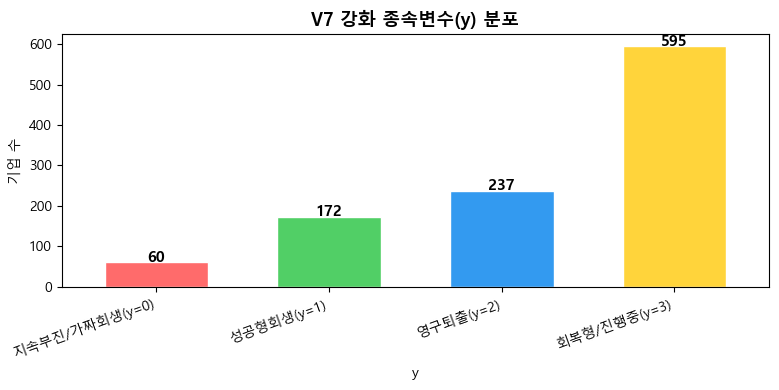


[자동 해석] Stage Model: 생존(827) vs 퇴출(237)
  성공형(y=1) 172개: 자본잠식 완전탈출 + 3년 연속 영업이익 흑자 충족
  회복형(y=3) 595개: 탈출은 했으나 안정 검증 미완료
  V7 강화: 단순 자본총계 양수가 아닌, 이익잉여금 양수 + 연속 흑자 요구


In [6]:
# ══════════════════════════════════════════════════════════════════
# Phase 1-B: 강화 종속변수 y (V7 — 4-class)
#   y=0: 지속부진/가짜회생  y=1: 성공형 회생 (잠식탈출+3년연속흑자)
#   y=2: 영구퇴출           y=3: 회복형(진행중)
# ══════════════════════════════════════════════════════════════════
df_crisis = df.merge(crisis_df, on=COL['id'], how='inner')
df_crisis['t_since_crisis'] = df_crisis[COL['year']] - df_crisis['T0_year']

labels = {}
df['OPM']       = df[COL['op_income']] / df[COL['revenue']].replace(0, np.nan)
df['OCF_ratio'] = df[COL['ocf']]       / df[COL['asset']].replace(0, np.nan)
delisted = set(df[df[COL['status']] == '상장폐지'][COL['id']].unique())

SUCCESS_OI_YEARS = CONFIG['SUCCESS_OI_YEARS']

for firm_id, grp in df_crisis.groupby(COL['id']):
    grp = grp.sort_values(COL['year'])
    t0  = grp['T0_year'].iloc[0]

    if firm_id in delisted:
        labels[firm_id] = 2
        continue

    # 잠식 탈출: 자본총계 > 0 AND 이익잉여금 > 0
    positive_years = grp.loc[
        (grp[COL['year']] > t0) &
        (grp[COL['equity']] > 0) &
        (grp[COL['ret_earn']] > 0),
        COL['year']
    ]

    if positive_years.empty:
        # 부분 탈출 시도: 자본총계만 양수
        partial_exit = grp.loc[
            (grp[COL['year']] > t0) & (grp[COL['equity']] > 0), COL['year']
        ]
        if partial_exit.empty:
            labels[firm_id] = 0
            continue
        # 부분 탈출은 있지만 완전 탈출 안됨 -> 회복형
        labels[firm_id] = 3
        continue

    t_exit = positive_years.min()
    post_exit = grp[grp[COL['year']] > t_exit]
    years_post = len(post_exit)
    relapsed_equity = (post_exit[COL['equity']] < 0).any()

    # 3년 연속 영업이익 흑자 체크
    post_oi = grp.loc[grp[COL['year']] >= t_exit, COL['op_income']]
    consecutive_oi_positive = 0
    max_consecutive = 0
    for val in post_oi.values:
        if pd.notna(val) and val > 0:
            consecutive_oi_positive += 1
            max_consecutive = max(max_consecutive, consecutive_oi_positive)
        else:
            consecutive_oi_positive = 0

    oi_condition = max_consecutive >= SUCCESS_OI_YEARS

    # 성공형 회생 (y=1): 3년 이상 안정 + 영업이익 조건
    if years_post >= CONFIG['POST_EXIT_MIN'] and not relapsed_equity and oi_condition:
        labels[firm_id] = 1
        continue

    # Type B: 최근 위기 기업
    if t0 in CONFIG['TYPE_B_YEARS'] and (t_exit - t0) <= CONFIG['TYPE_B_EXIT_GAP']:
        latest_yr = df[COL['year']].max()
        row_latest = df[(df[COL['id']] == firm_id) & (df[COL['year']] == latest_yr)]
        if not row_latest.empty:
            opm_val = row_latest['OPM'].iloc[0]
            ocf_val = row_latest['OCF_ratio'].iloc[0]
            opm_med = df[df[COL['year']] == latest_yr]['OPM'].median()
            ocf_med = df[df[COL['year']] == latest_yr]['OCF_ratio'].median()
            if pd.notna(opm_val) and pd.notna(ocf_val):
                if opm_val >= opm_med and ocf_val >= ocf_med:
                    labels[firm_id] = 1
                    continue

    # 회복형 (y=3)
    if not positive_years.empty and (years_post < CONFIG['POST_EXIT_MIN'] or relapsed_equity or not oi_condition):
        labels[firm_id] = 3
        continue

    labels[firm_id] = 0

label_s = pd.Series(labels, name='y').rename_axis(COL['id']).reset_index()
crisis_df = crisis_df.merge(label_s, on=COL['id'])

label_map = {
    0: '지속부진/가짜회생(y=0)',
    1: '성공형회생(y=1)',
    2: '영구퇴출(y=2)',
    3: '회복형/진행중(y=3)'
}
vc = label_s['y'].value_counts().rename(label_map)
print('종속변수(y) 분포 [V7 — 강화 4-class]:')
print(vc)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#FF6B6B', '#51CF66', '#339AF0', '#FFD43B']
vc_sorted = vc.reindex([label_map[i] for i in range(4) if label_map[i] in vc.index])
vc_sorted.plot(kind='bar', ax=ax, color=colors[:len(vc_sorted)], edgecolor='white', width=0.6)
ax.set_title('V7 강화 종속변수(y) 분포', fontsize=13, fontweight='bold')
ax.set_ylabel('기업 수')
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x()+p.get_width()/2, p.get_height()+2),
                ha='center', fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

n_survive = label_s[label_s['y'].isin([0,1,3])].shape[0]
n_exit = label_s[label_s['y'] == 2].shape[0]
n_success = label_s[label_s['y'] == 1].shape[0]
n_recover = label_s[label_s['y'] == 3].shape[0]
print(f'\n[자동 해석] Stage Model: 생존({n_survive}) vs 퇴출({n_exit})')
print(f'  성공형(y=1) {n_success}개: 자본잠식 완전탈출 + 3년 연속 영업이익 흑자 충족')
print(f'  회복형(y=3) {n_recover}개: 탈출은 했으나 안정 검증 미완료')
print(f'  V7 강화: 단순 자본총계 양수가 아닌, 이익잉여금 양수 + 연속 흑자 요구')

## Phase 2: 분석용 변수 생성 및 정밀 전처리

In [7]:
# ══════════════════════════════════════════════════════════════════
# Phase 2-A: 핵심 재무 비율 12종 + 잠식유형 지표
# ══════════════════════════════════════════════════════════════════
df_feat = df.copy()
A   = df_feat[COL['asset']].replace(0, np.nan)
R   = df_feat[COL['revenue']].replace(0, np.nan)
E   = df_feat[COL['equity']]
OI  = df_feat[COL['op_income']]
NI  = df_feat[COL['net_income']]
OCF = df_feat[COL['ocf']]
D   = df_feat[COL['debt']]
G   = df_feat[COL['gross']]
PPE = df_feat[COL['ppe']]
REC = df_feat[COL['rec']].replace(0, np.nan)
INV = df_feat[COL['inv']].replace(0, np.nan)
INT = df_feat[COL['int_exp']].replace(0, np.nan)

df_feat['ROA']           = NI  / A
df_feat['GPM']           = G   / R
df_feat['OPM']           = OI  / R
df_feat['OCF_ratio']     = OCF / A
df_feat['debt_ratio']    = D   / A
df_feat['cap_intensity'] = PPE / A
df_feat['rec_turn']      = R   / REC
df_feat['inv_turn']      = R   / INV
df_feat['asset_turn']    = R   / A
df_feat['int_coverage']  = OI  / INT
df_feat['equity_ratio']  = E   / A

df_feat = df_feat.sort_values([COL['id'], COL['year']])
df_feat['ocf_std5'] = (
    df_feat.groupby(COL['id'])['OCF_ratio']
    .transform(lambda x: x.rolling(5, min_periods=3).std())
)

# Pre-distress Flag: T-1 상태
df_feat['_oi_neg_flag'] = (df_feat[COL['op_income']] < 0).astype(int)
df_feat['_equity_neg'] = (df_feat[COL['equity']] < 0).astype(int)
df_feat['_int_cov_low'] = (df_feat['int_coverage'] < 1).astype(int)

print('재무 비율 12종 + Pre-distress 지표 생성 완료')
print(df_feat[['ROA','GPM','OPM','OCF_ratio','debt_ratio','cap_intensity']].describe().round(3))

재무 비율 12종 + Pre-distress 지표 생성 완료
             ROA        GPM        OPM  OCF_ratio  debt_ratio  cap_intensity
count  24667.000  24639.000  24639.000  22501.000   24667.000      24581.000
mean      -1.285      0.256     -0.955     -0.200       6.630          0.321
std      200.808      2.368     62.996     35.706     968.625          4.876
min   -31538.405   -367.437  -8727.439  -5355.997       0.001          0.000
25%       -0.021      0.117     -0.002     -0.003       0.279          0.138
50%        0.022      0.198      0.040      0.044       0.454          0.282
75%        0.059      0.356      0.088      0.091       0.611          0.418
max       31.484      5.882      8.809      0.807  152130.128        764.172


In [8]:
# ══════════════════════════════════════════════════════════════════
# Phase 2-B: 동적 변수 — Level / Delta / Interaction + 잠식유형
# ══════════════════════════════════════════════════════════════════
FEAT_COLS = [
    'ROA', 'GPM', 'OPM', 'OCF_ratio',
    'debt_ratio', 'cap_intensity',
    'rec_turn', 'inv_turn', 'asset_turn',
    'int_coverage', 'equity_ratio', 'ocf_std5'
]

t_exit_map = {}
for firm_id, grp in df_crisis.groupby(COL['id']):
    t0 = grp['T0_year'].iloc[0]
    pos = grp.loc[(grp[COL['year']] > t0) & (grp[COL['equity']] > 0), COL['year']]
    t_exit_map[firm_id] = pos.min() if not pos.empty else np.nan

t_exit_s = pd.Series(t_exit_map, name='T_exit').rename_axis(COL['id']).reset_index()

df_model_base = (
    label_s
    .merge(crisis_df[[COL['id'], 'T0_year', 'T0_imp_type']].drop_duplicates(subset=[COL['id']]), on=COL['id'])
    .merge(t_exit_s, on=COL['id'])
)

rows = []
for _, row in df_model_base.iterrows():
    fid   = row[COL['id']]
    t0    = row['T0_year']
    t_ex  = row['T_exit']
    y_val = row['y']
    imp_type = row['T0_imp_type']
    firm_data = df_feat[df_feat[COL['id']] == fid].set_index(COL['year'])
    t_level = (t_ex - 1) if pd.notna(t_ex) else t0
    t_delta = t0 - 1
    rec = {'코드': fid, 'y': y_val, 'T0': t0, 'T_exit': t_ex}

    # 잠식유형 더미
    rec['imp_complete'] = 1 if imp_type == 'complete' else 0
    rec['imp_partial']  = 1 if imp_type == 'partial' else 0

    for fc in FEAT_COLS:
        if fc not in firm_data.columns:
            continue
        lv = firm_data[fc].get(t_level, np.nan)
        bk = firm_data[fc].get(t_delta, np.nan)
        rec[f'{fc}_L'] = lv
        rec[f'{fc}_D'] = lv - bk if pd.notna(lv) and pd.notna(bk) else np.nan
    roa_l = rec.get('ROA_L', np.nan)
    roa_d = rec.get('ROA_D', np.nan)
    rec['ROA_interact'] = roa_l * roa_d if pd.notna(roa_l) and pd.notna(roa_d) else np.nan

    # Pre-distress flag (T-1)
    t_minus_1 = t0 - 1
    if t_minus_1 in firm_data.index:
        rec['pre_distress_oi'] = firm_data['_oi_neg_flag'].get(t_minus_1, 0)
        rec['pre_distress_eq'] = firm_data['_equity_neg'].get(t_minus_1, 0)
        rec['pre_distress_ic'] = firm_data['_int_cov_low'].get(t_minus_1, 0)
    else:
        rec['pre_distress_oi'] = 0
        rec['pre_distress_eq'] = 0
        rec['pre_distress_ic'] = 0
    rec['pre_distress_flag'] = max(rec['pre_distress_oi'], rec['pre_distress_eq'], rec['pre_distress_ic'])
    rows.append(rec)

df_model = pd.DataFrame(rows).dropna(subset=['y'])
print(f'동적 변수: {df_model.shape[0]:,}개 기업 x {df_model.shape[1]}개 변수')
print(df_model['y'].value_counts().rename(label_map))
print(f'잠식유형: 완전={df_model["imp_complete"].sum():.0f}, 부분={df_model["imp_partial"].sum():.0f}')

동적 변수: 1,064개 기업 x 35개 변수
y
회복형/진행중(y=3)      595
영구퇴출(y=2)         237
성공형회생(y=1)        172
지속부진/가짜회생(y=0)     60
Name: count, dtype: int64
잠식유형: 완전=90, 부분=974


In [9]:

# ══════════════════════════════════════════════════════════════════
# Phase 2-C: 극단치 제어 + Robust Scaling
# ── 공통 전처리 헬퍼 (Phase 4-A에서도 재사용) ─────────────────
# ══════════════════════════════════════════════════════════════════

def _winsor_robust_scale_inplace(data_df, col_list, skip_col_set=frozenset(), winsor_pct=0.01):
    """
    Winsorize + Robust Scale 를 col_list에 일괄 적용 (in-place).

    각 열에 대해 Winsorization(clip) → Winsorized 분포 기준 Robust Scaling 순으로 수행한다.
    skip_col_set 에 포함된 열은 건너뛴다.

    Returns
    -------
    wp : dict  winsor 파라미터 {col: {'lo': float, 'hi': float}}
    sp : dict  scale  파라미터 {col: {'med': float, 'iqr': float}}
    """
    wp, sp = {}, {}
    for c in col_list:
        if c in skip_col_set:
            continue
        lo = data_df[c].quantile(winsor_pct)
        hi = data_df[c].quantile(1 - winsor_pct)
        data_df[c] = data_df[c].clip(lo, hi)
        wp[c] = {'lo': float(lo), 'hi': float(hi)}
        med     = data_df[c].median()
        iqr_val = data_df[c].quantile(0.75) - data_df[c].quantile(0.25)
        eff_iqr = float(iqr_val) if iqr_val > 0 else 1.0
        sp[c] = {'med': float(med), 'iqr': eff_iqr}
        data_df[c] = (data_df[c] - med) / eff_iqr
    return wp, sp

# ─────────────────────────────────────────────────────────────────
X_cols = [c for c in df_model.columns if c.endswith('_L') or c.endswith('_D') or c == 'ROA_interact']
X_cols += ['pre_distress_flag', 'imp_complete', 'imp_partial']
df_proc = df_model.copy()

pct       = CONFIG['WINSOR_PCTILE']
skip_cols = {'pre_distress_flag', 'imp_complete', 'imp_partial'}

# Winsorization + Robust Scaling (파라미터 저장 — Phase 6-H CBR 엔진용)
winsor_params, scale_params = _winsor_robust_scale_inplace(
    df_proc, X_cols, skip_col_set=skip_cols, winsor_pct=pct
)

if CONFIG['MISS_FILL'] == 'median':
    df_proc[X_cols] = df_proc[X_cols].fillna(df_proc[X_cols].median())
else:
    df_proc[X_cols] = df_proc[X_cols].fillna(0)

X = df_proc[X_cols].values
y = df_proc['y'].astype(int).values

print(f'Winsorizing({pct*100:.0f}%) + Robust Scaling 완료')
print(f'   X shape: {X.shape} | y 분포: {dict(zip(*np.unique(y, return_counts=True)))}')
print(f'   잠식유형 피쳐 포함: imp_complete, imp_partial')
print(f'   스케일 파라미터 저장: {len(scale_params)}개 (Phase 6-H CBR 엔진용)')


Winsorizing(1%) + Robust Scaling 완료
   X shape: (1064, 28) | y 분포: {np.int64(0): np.int64(60), np.int64(1): np.int64(172), np.int64(2): np.int64(237), np.int64(3): np.int64(595)}
   잠식유형 피쳐 포함: imp_complete, imp_partial
   스케일 파라미터 저장: 25개 (Phase 6-H CBR 엔진용)


## Phase 3: 계층적(Hierarchical) 산업 DNA 클러스터링

| 단계 | 내용 |
|---|---|
| Step 1 | KSIC 대분류 키워드 매핑 |
| Step 2 | 미분류 → Nearest Centroid 귀속 |
| Step 3 | 산업군별 독립적 Robust Scaling & K-means++ |
| Step 4 | 소규모 클러스터 최근접 병합 |
| Step 5 | 하이브리드 라벨 부여 |

In [10]:

# ══════════════════════════════════════════════════════════════════
# Phase 3-A: KSIC 대분류 프록시 생성
# ══════════════════════════════════════════════════════════════════
KSIC_KEYWORD_MAP = {
    'C_제조업': [
        '전자','반도체','디스플레이','화학','석유','정유','제약','바이오','자동차','부품',
        '철강','금속','소재','배터리','기계','조선','항공','우주','방산','섬유','의류',
        '식품','음료','종이','고무','플라스틱','유리','세라믹','태양','풍력','연료전지',
        '광학','의료기기','포장','인쇄','가구','완구','스포츠','화장품','생활용품',
        'SDI','SDC','SDS','하이닉스','이노베이션','에너빌','모비스','로템','전기',
        '중공업','엔지니어링','솔루션','테크','시스템','일렉트릭','머티리얼','케미칼',
        '스틸','퓨처엠','에코프로','포스코','고려아연','LS','LG화학',
        '팜','메디','셀','텍','온','랩','진','엔','씨앤','앤피',
    ],
    'F_건설업': [
        '건설','시공','건축','토목','주택','개발','플랜트','인프라','ENG',
        '산업개발','건영','삼부','HDC','DL이앤씨',
    ],
    'G_도소매': [
        '유통','마트','쇼핑','무역','도매','소매','상사','트레이딩','홈쇼핑',
        '리테일','이마트','롯데쇼핑','코스트코','홈플러스',
    ],
    'H_운수창고': [
        '물류','운송','해운','택배','창고','선박','HMM',
        '글로비스','대한통운','팬오션',
    ],
    'J_정보통신': [
        '소프트','게임','IT','인터넷','플랫폼','미디어','콘텐츠','방송','통신','정보기술',
        '데이터','클라우드','보안','AI','앱','엔터','네이버','카카오','NAVER','넷마블',
        '엔씨','크래프톤','KT','SKT','LGU','SK텔레콤','하이브','SM','JYP','YG',
        '스튜디오','픽쳐스',
    ],
    'K_금융보험': [
        '증권','보험','은행','캐피탈','금융','자산운용','리츠','투자','지주',
        '생명','화재','KB','신한','하나','우리','NH','미래에셋','메리츠','교보','현대해상',
    ],
    'L_부동산': ['부동산','임대','분양','신탁','AMC'],
    'ETC_기타': [],   # 키워드 없음 — 루프에서 제외, 기본값으로 처리
}

# ETC_기타는 키워드가 없으므로 루프에 포함하지 않고 기본값(return)으로 처리
_KSIC_ORDERED = ['K_금융보험','H_운수창고','F_건설업','L_부동산',
                  'G_도소매','J_정보통신','C_제조업']

def assign_ksic(name):
    for cat in _KSIC_ORDERED:
        kws = KSIC_KEYWORD_MAP[cat]
        if any(kw in str(name) for kw in kws):
            return cat
    return 'ETC_기타'

firm_names = df_feat.drop_duplicates(COL['id'])[[COL['id'], COL['name']]].copy()
firm_names['ksic'] = firm_names[COL['name']].apply(assign_ksic)

mapping_dist = firm_names['ksic'].value_counts()
print('KSIC 대분류 1차 매핑:')
print(mapping_dist.to_string())

cluster_base = (
    df_feat.groupby(COL['id'])
    .agg(
        cap_intensity = ('cap_intensity', 'median'),
        GPM           = ('GPM',           'median'),
        ocf_std5      = ('ocf_std5',      'mean'),
        rec_turn      = ('rec_turn',      'median'),
        inv_turn      = ('inv_turn',      'median'),
        n_years       = (COL['year'],     'count'),
    )
    .dropna(thresh=3)
    .reset_index()
)
cluster_base['turnover_composite'] = (
    cluster_base['rec_turn'].fillna(cluster_base['rec_turn'].median()) +
    cluster_base['inv_turn'].fillna(cluster_base['inv_turn'].median())
)
CLUSTER_FEATS = ['cap_intensity', 'GPM', 'ocf_std5', 'turnover_composite']

cluster_base = cluster_base.merge(firm_names[[COL['id'], 'ksic']], on=COL['id'], how='left')
cluster_base['ksic'] = cluster_base['ksic'].fillna('ETC_기타')

mapped_mask   = cluster_base['ksic'] != 'ETC_기타'
unmapped_mask = ~mapped_mask
if unmapped_mask.sum() > 0 and mapped_mask.sum() > 10:
    scaler_nc = RobustScaler()
    X_mapped   = cluster_base.loc[mapped_mask,   CLUSTER_FEATS].fillna(0)
    X_unmapped = cluster_base.loc[unmapped_mask, CLUSTER_FEATS].fillna(0)
    scaler_nc.fit(X_mapped)
    nc = NearestCentroid()
    nc.fit(scaler_nc.transform(X_mapped), cluster_base.loc[mapped_mask, 'ksic'])
    predicted = nc.predict(scaler_nc.transform(X_unmapped))
    cluster_base.loc[unmapped_mask, 'ksic'] = predicted
    print(f'\nETC_기타 {unmapped_mask.sum()}개 자동 귀속')

print(f'\n최종 KSIC: {cluster_base["ksic"].value_counts().to_string()}')


KSIC 대분류 1차 매핑:
ksic
ETC_기타    2527
C_제조업     1064
K_금융보험     404
J_정보통신     158
F_건설업       83
G_도소매       36
H_운수창고       9

ETC_기타 1540개 자동 귀속

최종 KSIC: ksic
K_금융보험    1382
C_제조업      747
J_정보통신     198
F_건설업       70
G_도소매       55
H_운수창고      27


In [11]:

# ══════════════════════════════════════════════════════════════════
# Phase 3-B: 계층적 산업 DNA 클러스터링
# ── 공통 Robust Scaling 헬퍼 (Phase 3-C에서도 재사용) ──────────
# ══════════════════════════════════════════════════════════════════

def _robust_scale_2d(X):
    """각 열을 Robust Scaling (중앙값·IQR 기준) 한 복사본 2D 배열을 반환한다."""
    X = X.copy()
    for j in range(X.shape[1]):
        col   = X[:, j]
        med   = np.median(col)
        q75, q25 = np.percentile(col, 75), np.percentile(col, 25)
        iqr_v = q75 - q25
        X[:, j] = (col - med) / (iqr_v if iqr_v > 0 else 1)
    return X

# ─────────────────────────────────────────────────────────────────
K_MIN_       = CONFIG['K_MIN']
K_MAX_       = CONFIG['K_MAX']
MIN_SAMPLES  = CONFIG['MIN_CLUSTER_SIZE']
MIN_SECTOR   = CONFIG['MIN_SECTOR_SIZE']
N_INIT       = CONFIG['KMEANS_N_INIT']
RS           = CONFIG['RANDOM_STATE']

def merge_small(X, labels, centers, min_n):
    labels = labels.copy()
    for _ in range(10):
        counts = pd.Series(labels).value_counts()
        small = counts[counts < min_n].index.tolist()
        if not small: break
        if len(counts) <= 2: break
        for sc in small:
            if len(pd.Series(labels).value_counts()) <= 2: break
            valid = [c for c in range(len(centers)) if c != sc and counts.get(c,0) >= min_n]
            if not valid: continue
            for i in np.where(labels == sc)[0]:
                dists = np.linalg.norm(centers - X[i], axis=1)
                dists[sc] = np.inf
                labels[i] = min(valid, key=lambda c: dists[c])
        counts = pd.Series(labels).value_counts()
    return labels

def find_best_k(X_sc, k_min, k_max, min_n):
    k_upper = min(k_max, max(k_min, len(X_sc) // min_n))
    if len(X_sc) < k_min * min_n:
        return 1, {}, None
    scores, models = {}, {}
    for k in range(k_min, k_upper + 1):
        if k >= len(X_sc): break
        km = KMeans(n_clusters=k, init='k-means++', n_init=N_INIT, random_state=RS)
        lbl = km.fit_predict(X_sc)
        if len(np.unique(lbl)) < 2: continue
        scores[k] = silhouette_score(X_sc, lbl, sample_size=min(2000, len(X_sc)), random_state=RS)
        models[k] = km
    if not scores: return 1, {}, None
    bk = max(scores, key=scores.get)
    return bk, scores, models[bk]

industry_kmeans = {}
industry_results = {}
cluster_base['cluster_id'] = 'Unknown'
industries = sorted(cluster_base['ksic'].unique())

print(f'{len(industries)}개 산업 클러스터링')
print(f'{"산업":<20} {"기업수":>6} {"최적K":>5} {"Silhouette":>12} {"최종":<6}')
print('-' * 55)

for ind in industries:
    mask = (cluster_base['ksic'] == ind).values
    idx  = cluster_base.index[mask]
    df_ind = cluster_base.loc[mask, CLUSTER_FEATS].copy()
    n_firms = len(df_ind)

    if n_firms < MIN_SECTOR:
        cluster_base.loc[idx, 'cluster_id'] = f'{ind}-C0'
        industry_results[ind] = {'best_k':1, 'sil':np.nan, 'n_final_clusters':1, 'n_firms':n_firms}
        print(f'{ind:<20} {n_firms:>6} {"1":>5} {"N/A":>12} {"1":<6}')
        continue

    df_filled = df_ind.fillna(df_ind.median())
    for c_f in CLUSTER_FEATS:
        lo = df_filled[c_f].quantile(0.01)
        hi = df_filled[c_f].quantile(0.99)
        df_filled[c_f] = df_filled[c_f].clip(lo, hi)

    X_sec = _robust_scale_2d(df_filled.values)   # 공통 헬퍼 사용

    bk, scores, km_best = find_best_k(X_sec, K_MIN_, K_MAX_, max(5, n_firms // 20))

    if bk == 1 or km_best is None:
        labels_loc = np.zeros(n_firms, dtype=int)
        best_sil = np.nan
        centers = X_sec.mean(axis=0).reshape(1, -1)
    else:
        labels_loc = km_best.predict(X_sec)
        centers = km_best.cluster_centers_
        best_sil = scores.get(bk, np.nan)

    if bk > 1:
        labels_loc = merge_small(X_sec, labels_loc, centers, max(5, n_firms // 20))

    unique_loc = sorted(np.unique(labels_loc))
    remap = {old: new for new, old in enumerate(unique_loc)}
    hybrid = [f'{ind}-C{remap[lc]}' for lc in labels_loc]
    cluster_base.loc[idx, 'cluster_id'] = hybrid

    industry_kmeans[ind] = km_best
    n_final = len(unique_loc)
    industry_results[ind] = {'best_k':bk, 'sil':best_sil, 'n_final_clusters':n_final,
                             'n_firms':n_firms, 'sil_scores':scores}
    sil_str = f'{best_sil:.4f}' if not np.isnan(best_sil) else 'N/A'
    print(f'{ind:<20} {n_firms:>6} {bk:>5} {sil_str:>12} {n_final:<6}')

total_clusters = cluster_base['cluster_id'].nunique()
print(f'\n총 하이브리드 클러스터: {total_clusters}개')


6개 산업 클러스터링
산업                      기업수   최적K   Silhouette 최종    
-------------------------------------------------------
C_제조업                   747     2       0.9242 2     
F_건설업                    70     2       0.7389 2     
G_도소매                    55     2       0.3493 2     
H_운수창고                   27     2       0.9590 2     
J_정보통신                  198     2       0.9024 2     
K_금융보험                 1382     2       0.4264 2     

총 하이브리드 클러스터: 12개


Bootstrap ARI: 0.3392 +/- 0.4050


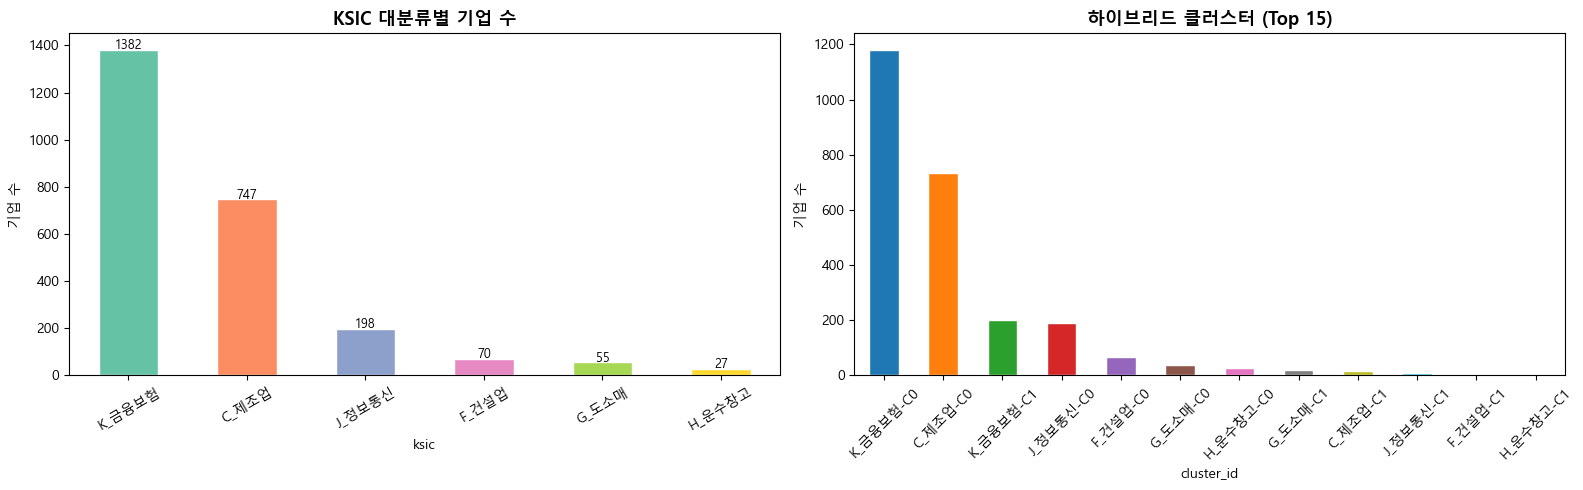

In [12]:

# ══════════════════════════════════════════════════════════════════
# Phase 3-C: 클러스터 검증 & 시각화
# ══════════════════════════════════════════════════════════════════
N_BOOT = CONFIG['N_BOOT_ARI']
ari_all = []
for ind, res in industry_results.items():
    if res['n_firms'] < K_MIN_ * 3 or res['best_k'] < 2: continue
    mask = (cluster_base['ksic'] == ind).values
    df_ind = cluster_base.loc[mask, CLUSTER_FEATS].fillna(
        cluster_base.loc[mask, CLUSTER_FEATS].median())
    X_s = _robust_scale_2d(df_ind.values)   # Phase 3-B 공통 헬퍼 재사용
    ref_raw = cluster_base.loc[mask, 'cluster_id'].values
    uid = {v: i for i, v in enumerate(sorted(set(ref_raw)))}
    ref_lbl = np.array([uid[v] for v in ref_raw])
    for _ in range(N_BOOT):
        idx_b = np.random.choice(len(X_s), size=int(len(X_s)*0.8), replace=False)
        try:
            lbl_b = KMeans(n_clusters=res['best_k'], init='k-means++', n_init=10, random_state=None).fit_predict(X_s[idx_b])
            ari_all.append(adjusted_rand_score(ref_lbl[idx_b], lbl_b))
        except: pass

ari_scores = ari_all
if ari_scores:
    print(f'Bootstrap ARI: {np.mean(ari_scores):.4f} +/- {np.std(ari_scores):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ind_cnt = cluster_base['ksic'].value_counts()
ind_cnt.plot(kind='bar', ax=axes[0], color=sns.color_palette('Set2', len(ind_cnt)), edgecolor='white')
axes[0].set_title('KSIC 대분류별 기업 수', fontsize=13, fontweight='bold')
axes[0].set_ylabel('기업 수'); axes[0].tick_params(axis='x', rotation=30)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()+3), ha='center', fontsize=9)

cl_cnt = cluster_base['cluster_id'].value_counts().head(15)
cl_cnt.plot(kind='bar', ax=axes[1], color=sns.color_palette('tab10', len(cl_cnt)), edgecolor='white')
axes[1].set_title('하이브리드 클러스터 (Top 15)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('기업 수'); axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

# Silhouette 비교
sil_sum = {i: r['sil'] for i, r in industry_results.items() if not np.isnan(r.get('sil', np.nan))}
if sil_sum:
    sil_s = pd.Series(sil_sum).sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(8, 4))
    c_sil = ['#51CF66' if v >= 0.3 else '#FFD43B' if v >= 0.15 else '#FF6B6B' for v in sil_s.values]
    sil_s.plot(kind='barh', ax=ax, color=c_sil)
    ax.axvline(0.3, color='green', ls='--', lw=1, alpha=0.7, label='양호(0.3)')
    ax.axvline(0.15, color='orange', ls='--', lw=1, alpha=0.7, label='보통(0.15)')
    ax.set_title('산업별 Silhouette Score', fontsize=13, fontweight='bold')
    ax.legend(fontsize=9)
    plt.tight_layout(); plt.show()


In [13]:

# ══════════════════════════════════════════════════════════════════
# Phase 3-D: 클러스터 정보 병합
# COL['id'] == '코드' 이므로 on= 를 사용해 컬럼 충돌 방지
# ══════════════════════════════════════════════════════════════════
df_proc = df_proc.merge(
    cluster_base[[COL['id'], 'ksic', 'cluster_id']],
    on=COL['id'], how='left'
)
df_proc['cluster_id'] = df_proc['cluster_id'].fillna('Unknown')
df_proc['ksic']       = df_proc['ksic'].fillna('ETC_기타')

ct = df_proc[df_proc['y']==1].groupby('cluster_id').size().reset_index(name='n_success').sort_values('n_success', ascending=False)
print('클러스터별 성공(y=1) 사례:')
print(ct.head(15).to_string(index=False))
print(f'\n최종: {len(df_proc):,}기업 | {df_proc["cluster_id"].nunique()}개 클러스터')


클러스터별 성공(y=1) 사례:
cluster_id  n_success
 K_금융보험-C0         65
  C_제조업-C0         56
 K_금융보험-C1         20
 J_정보통신-C0         18
  F_건설업-C0          5
 H_운수창고-C0          4
  G_도소매-C0          2
  C_제조업-C1          2

최종: 1,064기업 | 13개 클러스터


## Phase 4: CB-Cost Class Weight + Discrete-time Hazard 모형 (Leakage-Free)

In [14]:

# ══════════════════════════════════════════════════════════════════
# Phase 4-A: Person-Period 패널 생성
# ══════════════════════════════════════════════════════════════════

# ── O(1) 조회용 사전 빌드 (O(n²) → O(n) 개선) ───────────────────
_feat_by_firm    = {fid: grp.set_index(COL['year'])
                    for fid, grp in df_feat.groupby(COL['id'])}
_PP_DIST_COLS    = ['pre_distress_flag', 'pre_distress_oi', 'pre_distress_eq', 'pre_distress_ic']
_model_lookup    = df_model.set_index('코드')[_PP_DIST_COLS + ['imp_complete', 'imp_partial']]

pp_rows = []
for _, base_row in df_model.iterrows():
    fid   = base_row['코드']
    t0    = base_row['T0']
    t_ex  = base_row['T_exit']
    y_val = base_row['y']

    firm_data = _feat_by_firm.get(fid)      # O(1)
    if firm_data is None:
        continue

    # pre_distress + imp 정보: 기업당 1회만 조회 ─────────────────
    if fid in _model_lookup.index:
        m_row = _model_lookup.loc[fid]
        pre_d = {c: int(m_row[c]) if pd.notna(m_row[c]) else 0
                 for c in _PP_DIST_COLS}
        imp_c = int(m_row['imp_complete']) if pd.notna(m_row['imp_complete']) else 0
        imp_p = int(m_row['imp_partial'])  if pd.notna(m_row['imp_partial'])  else 0
    else:
        pre_d = {c: 0 for c in _PP_DIST_COLS}
        imp_c = imp_p = 0

    years_after = [yr for yr in firm_data.index if yr > t0]
    if not years_after:
        continue

    for t_now in sorted(years_after)[:10]:
        duration = t_now - t0
        if pd.notna(t_ex) and t_now == t_ex:
            event = 1 if y_val == 1 else 0
        elif t_now > (t_ex if pd.notna(t_ex) else 9999):
            break
        else:
            event = 0
        row_feat = {fc: firm_data[fc].get(t_now, np.nan)
                    if fc in firm_data.columns else np.nan
                    for fc in FEAT_COLS}
        pp_rows.append({
            '코드': fid, 'year': t_now, 'duration': duration,
            'event': event, 'y_label': y_val,
            'imp_complete': imp_c, 'imp_partial': imp_p,
            **row_feat, **pre_d
        })

df_pp = pd.DataFrame(pp_rows)

# Winsorization + Robust Scaling — Phase 2-C 공통 헬퍼 재사용
_winsor_robust_scale_inplace(df_pp, FEAT_COLS, winsor_pct=pct)
df_pp[FEAT_COLS] = df_pp[FEAT_COLS].fillna(df_pp[FEAT_COLS].median())
df_pp['dur_sq']  = df_pp['duration'] ** 2
df_pp['dur_log'] = np.log1p(df_pp['duration'])

print(f'Person-Period: {len(df_pp):,}행 | 이벤트: {df_pp["event"].mean()*100:.2f}%')


Person-Period: 1,666행 | 이벤트: 10.32%


In [15]:
# ══════════════════════════════════════════════════════════════════
# Phase 4-B: Class Weight + Leakage-Free 분할
# ══════════════════════════════════════════════════════════════════
PP_X_COLS = FEAT_COLS + ['duration', 'dur_sq', 'dur_log', 'pre_distress_flag', 'imp_complete', 'imp_partial']

X_pp = df_pp[PP_X_COLS].values
y_pp = df_pp['event'].values
groups_pp = df_pp['코드'].values

sample_weight = compute_sample_weight(class_weight='balanced', y=y_pp)
cost_mult = CONFIG['COST_MULT']
for i in range(len(sample_weight)):
    if y_pp[i] == 1:
        sample_weight[i] *= cost_mult

TRAIN_YRS = CONFIG['TRAIN_YEARS']
TEST_YRS  = CONFIG['TEST_YEARS']
train_mask_t = df_pp['year'].between(*TRAIN_YRS)
test_mask_t  = df_pp['year'].between(*TEST_YRS)

if y_pp[test_mask_t.values].sum() == 0:
    print('시간분할 이벤트 없음 -> SGKF 5-Fold 전환')
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RS)
    folds = list(sgkf.split(X_pp, y_pp, groups=groups_pp))
    tr_idx, te_idx = folds[-1]
    train_mask = np.zeros(len(y_pp), dtype=bool); train_mask[tr_idx] = True
    test_mask  = np.zeros(len(y_pp), dtype=bool); test_mask[te_idx] = True
    USE_SGKF = True
else:
    train_mask = train_mask_t.values
    test_mask  = test_mask_t.values
    USE_SGKF = False

X_train, y_train, sw_train = X_pp[train_mask], y_pp[train_mask], sample_weight[train_mask]
X_test,  y_test            = X_pp[test_mask],  y_pp[test_mask]

print(f'학습: {X_train.shape[0]:,} | 테스트: {X_test.shape[0]:,}')
print(f'학습 이벤트: {y_train.mean()*100:.2f}% | 테스트: {y_test.mean()*100:.2f}%')

학습: 990 | 테스트: 295
학습 이벤트: 9.49% | 테스트: 1.36%


In [16]:
# ══════════════════════════════════════════════════════════════════
# Phase 4-C: Discrete-time Hazard GBM
# ══════════════════════════════════════════════════════════════════
gbm = GradientBoostingClassifier(
    n_estimators=CONFIG['GBM_N_EST'], max_depth=CONFIG['GBM_DEPTH'],
    learning_rate=CONFIG['GBM_LR'], subsample=0.8,
    min_samples_leaf=20, random_state=RS
)
gbm.fit(X_train, y_train, sample_weight=sw_train)

prob_train = gbm.predict_proba(X_train)[:, 1]
prob_test  = gbm.predict_proba(X_test)[:, 1]

auc_train = roc_auc_score(y_train, prob_train)
auc_test  = roc_auc_score(y_test, prob_test) if y_test.sum() > 0 else np.nan
ap_test   = average_precision_score(y_test, prob_test) if y_test.sum() > 0 else np.nan

print(f'학습 AUC  = {auc_train:.4f}')
print(f'테스트 AUC = {auc_test:.4f}')
print(f'테스트 AP  = {ap_test:.4f}')

학습 AUC  = 1.0000
테스트 AUC = 0.8462
테스트 AP  = 0.0547


Stability Selection (200회):
   ROA                           : 100.0%
   OPM                           : 100.0%
   asset_turn                    : 100.0%
   dur_sq                        : 100.0%
   imp_partial                   : 100.0%
   inv_turn                      : 99.0%
   int_coverage                  : 99.0%
   duration                      : 97.5%
   debt_ratio                    : 89.5%
   cap_intensity                 : 89.5%
   equity_ratio                  : 89.5%
   OCF_ratio                     : 88.0%
   pre_distress_flag             : 82.5%
   GPM                           : 82.0%
   dur_log                       : 80.5%
   rec_turn                      : 79.5%
   ocf_std5                      : 73.0%


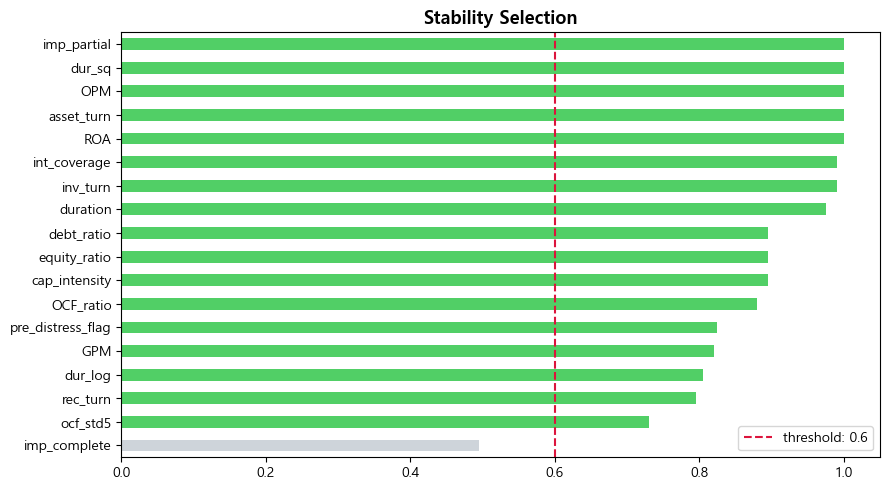

In [17]:
# ══════════════════════════════════════════════════════════════════
# Phase 4-D: Stability Selection
# ══════════════════════════════════════════════════════════════════
N_BOOT_SS = CONFIG['STABILITY_N_BOOT']
THRESH    = CONFIG['STABILITY_THRESH']
feat_names = PP_X_COLS
select_cnt = np.zeros(len(feat_names))

np.random.seed(RS)
for _ in range(N_BOOT_SS):
    idx = np.random.choice(len(X_train), size=int(len(X_train)*0.5), replace=False)
    Xb, yb, swb = X_train[idx], y_train[idx], sw_train[idx]
    if yb.sum() < 3: continue
    try:
        lr = LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, C=0.1, max_iter=500, random_state=None)
        lr.fit(Xb, yb, sample_weight=swb)
        select_cnt += (np.abs(lr.coef_[0]) > 1e-6).astype(int)
    except: pass

select_prob = select_cnt / N_BOOT_SS
stable_vars = [(feat_names[i], select_prob[i]) for i in range(len(feat_names)) if select_prob[i] >= THRESH]
stable_vars_sorted = sorted(stable_vars, key=lambda x: -x[1])

print(f'Stability Selection ({N_BOOT_SS}회):')
for v, p in stable_vars_sorted: print(f'   {v:30s}: {p*100:.1f}%')

fig, ax = plt.subplots(figsize=(9, 5))
sp_df = pd.Series(dict(zip(feat_names, select_prob))).sort_values(ascending=True)
c_sp = ['#51CF66' if v >= THRESH else '#CED4DA' for v in sp_df.values]
sp_df.plot(kind='barh', ax=ax, color=c_sp)
ax.axvline(THRESH, color='crimson', ls='--', lw=1.5, label=f'threshold: {THRESH}')
ax.set_title('Stability Selection', fontsize=13, fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

## Phase 5: 검증, 해석 및 Industry Contrast DNA

In [18]:
# ══════════════════════════════════════════════════════════════════
# Phase 5-A: 확률 교정 (Platt Scaling)
# ══════════════════════════════════════════════════════════════════
if y_test.sum() >= 5:
    from sklearn.frozen import FrozenEstimator
    cal_model = CalibratedClassifierCV(FrozenEstimator(gbm), method=CONFIG['CALIB_METHOD'], cv=5)
    cal_model.fit(X_train, y_train)
    prob_cal = cal_model.predict_proba(X_test)[:, 1]
    bs_raw = brier_score_loss(y_test, prob_test)
    bs_cal = brier_score_loss(y_test, prob_cal)
    print(f'Brier — 원본: {bs_raw:.4f} | 교정: {bs_cal:.4f}')

    fr_r, mp_r = calibration_curve(y_test, prob_test, n_bins=8, strategy='quantile')
    fr_c, mp_c = calibration_curve(y_test, prob_cal,  n_bins=8, strategy='quantile')
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot([0,1],[0,1], 'k--', label='완벽 교정')
    ax.plot(mp_r, fr_r, 's-', label=f'원본 (Brier={bs_raw:.3f})', color='steelblue')
    ax.plot(mp_c, fr_c, 'o-', label=f'교정 (Brier={bs_cal:.3f})', color='#51CF66')
    ax.set_title('Calibration Curve', fontsize=13, fontweight='bold')
    ax.set_xlabel('예측 확률'); ax.set_ylabel('실제 비율'); ax.legend()
    plt.tight_layout(); plt.show()
else:
    print('이벤트 수 부족 -> 교정 생략')
    cal_model = gbm; prob_cal = prob_test

이벤트 수 부족 -> 교정 생략


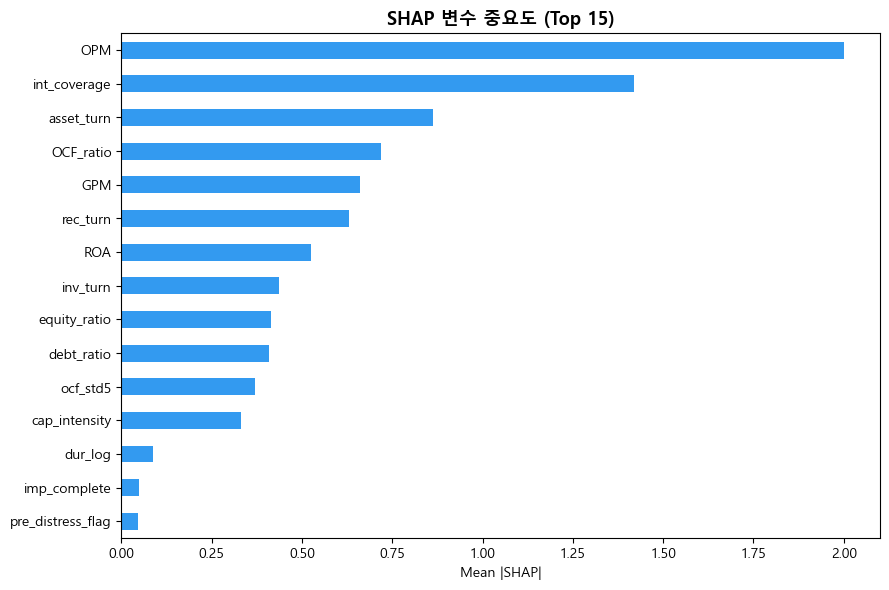

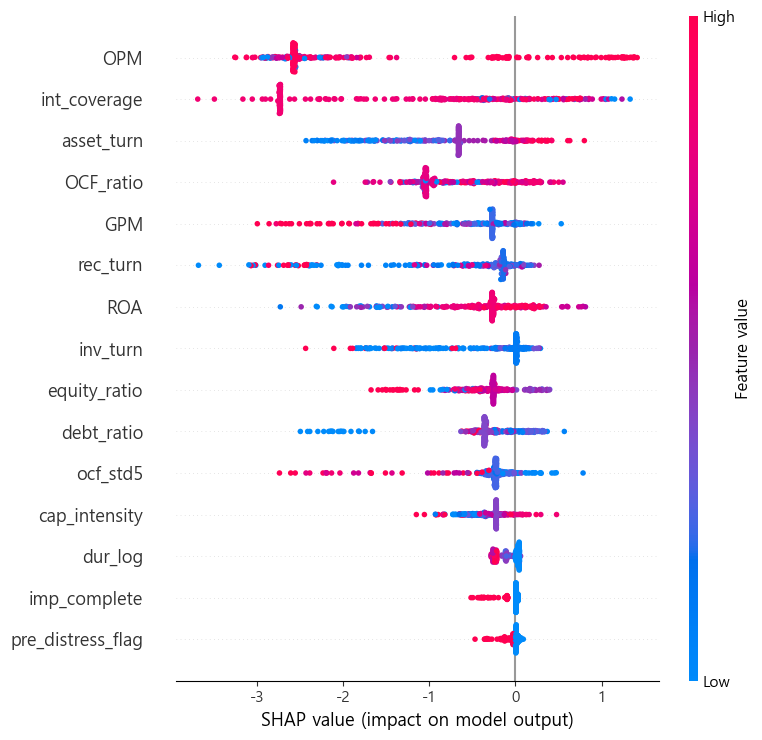


--- Industry Contrast DNA ---
  C_제조업-C0: OPM(2.087), int_coverage(1.430), asset_turn(0.761)
  C_제조업-C1: OPM(2.034), int_coverage(1.899), GPM(0.994)
  F_건설업-C0: OPM(1.613), int_coverage(1.168), asset_turn(0.938)
  J_정보통신-C0: OPM(1.970), GPM(1.425), asset_turn(1.003)
  K_금융보험-C0: OPM(1.979), int_coverage(1.591), asset_turn(0.866)
  K_금융보험-C1: OPM(1.636), asset_turn(1.060), rec_turn(0.976)


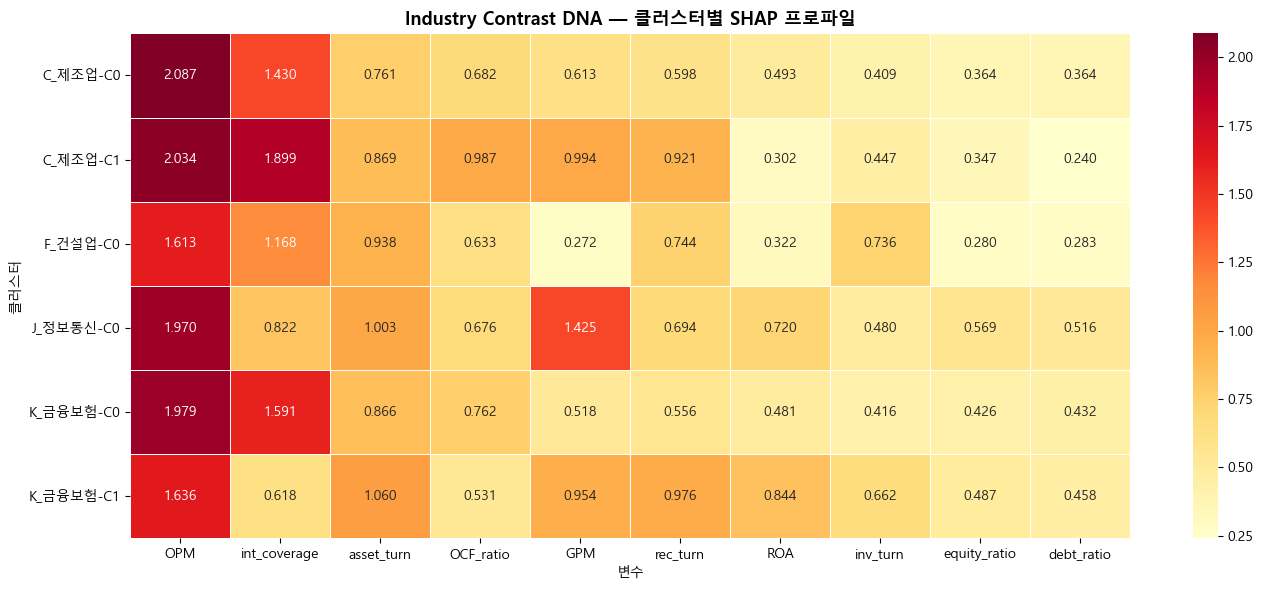


[자동 해석] 클러스터별 SHAP 프로파일이 상이한 변수는 해당 산업 고유의 회생 동인을 의미합니다.
  산업간 차별성이 큰 변수: int_coverage, GPM, ROA
  이 변수들은 산업 특성에 따라 회생 기여도가 크게 달라지는 핵심 DNA입니다.


In [19]:
# ══════════════════════════════════════════════════════════════════
# Phase 5-B: SHAP + Industry Contrast DNA (V7)
# ══════════════════════════════════════════════════════════════════
if SHAP_AVAILABLE:
    explainer = shap.TreeExplainer(gbm)
    shap_vals = explainer.shap_values(X_test)
    shap_arr = shap_vals if isinstance(shap_vals, np.ndarray) else shap_vals[1]

    shap_imp = pd.Series(np.abs(shap_arr).mean(axis=0), index=feat_names).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(9, 6))
    shap_imp.head(15).sort_values().plot(kind='barh', ax=ax, color='#339AF0')
    ax.set_title('SHAP 변수 중요도 (Top 15)', fontsize=13, fontweight='bold')
    ax.set_xlabel('Mean |SHAP|'); plt.tight_layout(); plt.show()

    shap.summary_plot(shap_arr, X_test, feature_names=feat_names, max_display=15, show=True)

    # ── Industry Contrast DNA ──
    cluster_pp = df_pp[test_mask]['코드'].map(
        cluster_base.set_index(COL['id'])['cluster_id']
    ).fillna('Unknown').values

    # 클러스터별 SHAP 프로파일 수집
    contrast_data = {}
    print('\n--- Industry Contrast DNA ---')
    for cl in sorted(set(cluster_pp)):
        if cl == 'Unknown': continue
        m = cluster_pp == cl
        if m.sum() < 5: continue
        cl_shap = pd.Series(np.abs(shap_arr[m]).mean(axis=0), index=feat_names)
        contrast_data[cl] = cl_shap
        top3 = cl_shap.sort_values(ascending=False).head(3)
        print(f'  {cl}: {", ".join([f"{n}({v:.3f})" for n, v in top3.items()])}')

    # Contrast DNA 히트맵
    if len(contrast_data) >= 2:
        contrast_df = pd.DataFrame(contrast_data).T
        # 상위 10개 변수만
        top_feats = shap_imp.head(10).index.tolist()
        plot_df = contrast_df[[f for f in top_feats if f in contrast_df.columns]]
        fig, ax = plt.subplots(figsize=(14, max(6, len(plot_df)*0.4)))
        sns.heatmap(plot_df, annot=True, fmt='.3f', cmap='YlOrRd', ax=ax, linewidths=0.5)
        ax.set_title('Industry Contrast DNA — 클러스터별 SHAP 프로파일', fontsize=13, fontweight='bold')
        ax.set_ylabel('클러스터'); ax.set_xlabel('변수')
        plt.tight_layout(); plt.show()

        print('\n[자동 해석] 클러스터별 SHAP 프로파일이 상이한 변수는 해당 산업 고유의 회생 동인을 의미합니다.')
        # 가장 분산이 큰 변수 = 산업별 차이가 큰 변수
        var_by_feat = plot_df.var()
        top_contrast = var_by_feat.sort_values(ascending=False).head(3)
        print(f'  산업간 차별성이 큰 변수: {", ".join(top_contrast.index.tolist())}')
        print(f'  이 변수들은 산업 특성에 따라 회생 기여도가 크게 달라지는 핵심 DNA입니다.')
else:
    print('SHAP 미설치')
    explainer = None
    shap_arr = None
    contrast_data = {}

OOS 성능 (2022~2024):
              precision    recall  f1-score   support

       부진/퇴출       0.99      0.88      0.93       291
       성공 회생       0.05      0.50      0.10         4

    accuracy                           0.87       295
   macro avg       0.52      0.69      0.52       295
weighted avg       0.98      0.87      0.92       295



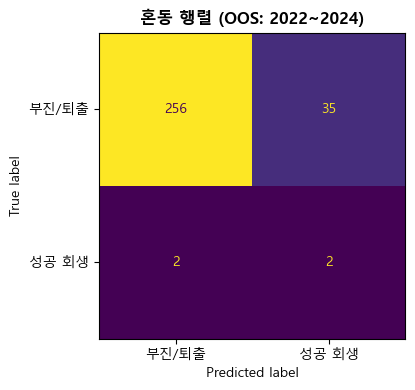

In [20]:
# ══════════════════════════════════════════════════════════════════
# Phase 5-C: OOS 검증
# ══════════════════════════════════════════════════════════════════
threshold = CONFIG['THRESHOLD']
y_pred = (prob_cal >= threshold).astype(int)

split_desc = 'SGKF' if USE_SGKF else f'{TEST_YRS[0]}~{TEST_YRS[1]}'
print(f'OOS 성능 ({split_desc}):')
if y_test.sum() > 0:
    print(classification_report(y_test, y_pred, target_names=['부진/퇴출', '성공 회생']))
    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay(cm, display_labels=['부진/퇴출', '성공 회생']).plot(ax=ax, colorbar=False)
    ax.set_title(f'혼동 행렬 (OOS: {split_desc})', fontsize=12, fontweight='bold')
    plt.tight_layout(); plt.show()
else:
    print('이벤트 없음')

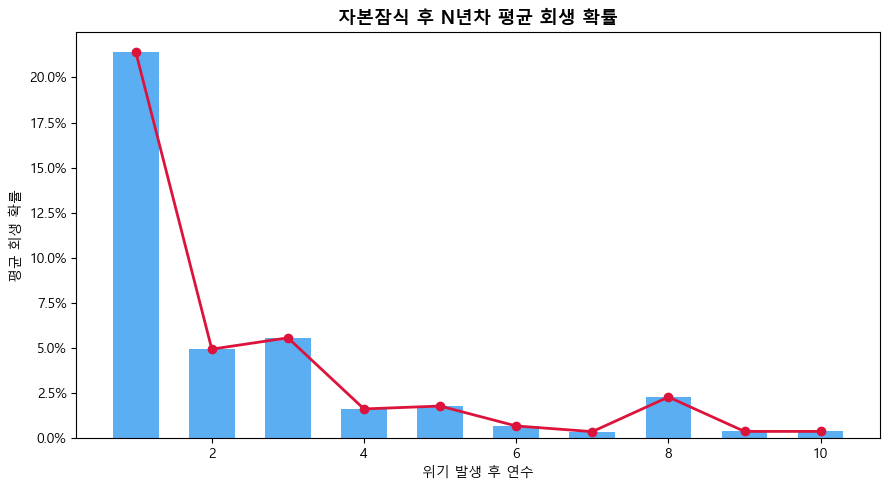

[자동 해석] 회생 확률이 가장 높은 시점: 위기 후 1년차 (21.4%)
  초기(1-3년) 평균: 10.7% vs 후기(4년+) 평균: 1.1%
  -> 조기 개입이 회생 성공의 핵심 (골든타임 존재)


In [21]:

# ══════════════════════════════════════════════════════════════════
# Phase 5-D: Hazard Rate 시각화
# ── 공통 Hazard Rate 차트 헬퍼 (Phase 6-B PDF 에서도 재사용) ───
# ══════════════════════════════════════════════════════════════════

def _draw_hazard_chart(ax, hz_df_data):
    """hz_df_data 의 바 + 라인 차트를 주어진 axes 에 그린다 (타이틀·축 레이블은 호출측에서 설정)."""
    ax.bar(hz_df_data['duration'], hz_df_data['hazard'], color='#339AF0', alpha=0.8, width=0.6)
    ax.plot(hz_df_data['duration'], hz_df_data['hazard'], 'o-', color='crimson', lw=2)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

dur_hazard = []
for dur in range(1, 11):
    mask_d = df_pp['duration'] == dur
    if mask_d.sum() < 10: continue
    X_d = df_pp.loc[mask_d, PP_X_COLS].values
    dur_hazard.append({'duration': dur, 'hazard': cal_model.predict_proba(X_d)[:, 1].mean(), 'n': mask_d.sum()})

hz_df = pd.DataFrame(dur_hazard)
if len(hz_df) > 0:
    fig, ax = plt.subplots(figsize=(9, 5))
    _draw_hazard_chart(ax, hz_df)
    ax.set_title('자본잠식 후 N년차 평균 회생 확률', fontsize=13, fontweight='bold')
    ax.set_xlabel('위기 발생 후 연수')
    ax.set_ylabel('평균 회생 확률')
    plt.tight_layout(); plt.show()

    # 자동 해석
    peak = hz_df.loc[hz_df['hazard'].idxmax()]
    print(f'[자동 해석] 회생 확률이 가장 높은 시점: 위기 후 {int(peak["duration"])}년차 ({peak["hazard"]*100:.1f}%)')
    if len(hz_df) >= 3:
        early = hz_df[hz_df['duration'] <= 3]['hazard'].mean()
        late = hz_df[hz_df['duration'] > 3]['hazard'].mean()
        print(f'  초기(1-3년) 평균: {early*100:.1f}% vs 후기(4년+) 평균: {late*100:.1f}%')
        if early > late:
            print('  -> 조기 개입이 회생 성공의 핵심 (골든타임 존재)')
        else:
            print('  -> 후기 회생도 가능하나, 장기적 구조개선 필요')


## Phase 5-E: V8 Omni-Attribution 근본 원인 진단 엔진

### Waterfall Variance Decomposition: ΔNI = ΔOP + ΔFin_cost + ΔOther

| 로직 단계 | 내용 |
|---|---|
| **변동성 감지** | 2σ 초과 재무 항목 플래그 |
| **Waterfall 분해** | 순이익 변동 → 영업이익/재무비용/기타 기여도 분해 |
| **드릴다운** | 영업이익 원인 → 매출 성장 vs 원가절감 vs 판관비통제 |
| **근거 매칭** | 매출 주도 시 DART 세그먼트 / 비용주도 시 비용분류표 / 자산 시 주요사항보고서 |

In [22]:

# ══════════════════════════════════════════════════════════════════
# Phase 5-E: V8 Omni-Attribution 근본 원인 진단 엔진
#   Waterfall: ΔNI = ΔOP + ΔFin_cost + ΔOther
#   2σ 이상치 감지 + 드릴다운 (매출증가 vs 원가절감 vs 판관비통제)
# ══════════════════════════════════════════════════════════════════

# ── 전역 Waterfall 기여 라벨 (Phase 6-F generate_company_report 에서도 재사용) ──
WATERFALL_LABELS = {
    'op_contribution':    '영업이익 개선',
    'fin_contribution':   '재무비용 절감',
    'other_contribution': '기타(자산처분 등)',
}


def decompose_variance(firm_id, t0=None, t_end=None):
    """ΔNI를 영업/재무/기타 요인으로 Waterfall 분해.
    Returns dict or None if insufficient data."""
    firm_data = df_feat[df_feat[COL['id']] == firm_id].sort_values(COL['year'])
    if len(firm_data) < 2:
        return None

    if t0 is None:
        t0_info = df_model[df_model['코드'] == firm_id]
        t0 = int(t0_info['T0'].iloc[0]) if not t0_info.empty else int(firm_data[COL['year']].min())

    if t_end is None:
        later = firm_data.loc[firm_data[COL['year']] > t0, COL['year']]
        if len(later) >= 2:
            t_end = int(later.iloc[1])
        elif len(later) == 1:
            t_end = int(later.iloc[0])
        else:
            return None

    row_s = firm_data[firm_data[COL['year']] == t0]
    row_e = firm_data[firm_data[COL['year']] == t_end]
    if row_s.empty or row_e.empty:
        return None

    def _g(row, key):
        c = COL.get(key)
        if c and c in row.columns:
            v = row[c].iloc[0]
            return float(v) if pd.notna(v) else np.nan
        return np.nan

    ni_s,  ni_e  = _g(row_s, 'net_income'),  _g(row_e, 'net_income')
    op_s,  op_e  = _g(row_s, 'op_income'),   _g(row_e, 'op_income')
    rev_s, rev_e = _g(row_s, 'revenue'),      _g(row_e, 'revenue')
    gp_s,  gp_e  = _g(row_s, 'gross'),        _g(row_e, 'gross')
    int_s, int_e = _g(row_s, 'int_exp'),      _g(row_e, 'int_exp')

    delta_ni  = (ni_e  - ni_s)  if pd.notna(ni_s)  and pd.notna(ni_e)  else np.nan
    delta_op  = (op_e  - op_s)  if pd.notna(op_s)  and pd.notna(op_e)  else np.nan
    delta_rev = (rev_e - rev_s) if pd.notna(rev_s) and pd.notna(rev_e) else np.nan
    delta_gp  = (gp_e  - gp_s)  if pd.notna(gp_s)  and pd.notna(gp_e)  else np.nan
    # 재무비용 절감: 이자비용 감소분 (양수=절감, 음수=증가)
    delta_fin = (int_s - int_e) if pd.notna(int_s) and pd.notna(int_e) else np.nan

    # 기타 기여 = ΔNI - ΔOP - ΔFin
    if pd.notna(delta_ni) and pd.notna(delta_op) and pd.notna(delta_fin):
        delta_other = delta_ni - delta_op - delta_fin
    elif pd.notna(delta_ni) and pd.notna(delta_op):
        delta_other = delta_ni - delta_op
        delta_fin = np.nan
    else:
        delta_other = np.nan

    raw_vals = {
        'op_contribution':    delta_op,
        'fin_contribution':   delta_fin,
        'other_contribution': delta_other,
    }
    abs_sum = sum(abs(v) for v in raw_vals.values() if pd.notna(v))
    if abs_sum == 0:
        return None

    contributions = {k: v / abs_sum for k, v in raw_vals.items() if pd.notna(v)}

    primary_key = max(contributions, key=lambda k: abs(contributions[k]))
    primary_pct = abs(contributions[primary_key]) * 100

    # 드릴다운: 영업이익 원인 분석
    op_drilldown = {}
    if primary_key == 'op_contribution' and pd.notna(delta_rev) and pd.notna(delta_gp):
        cogs_eff = delta_gp - delta_rev  # 원가 효율화분
        denom = abs(delta_rev) + abs(cogs_eff) + 1e-10
        rev_c = delta_rev / denom
        cg_c  = cogs_eff  / denom
        op_drilldown['rev_contribution']  = float(rev_c)
        op_drilldown['cost_contribution'] = float(cg_c)
        op_drilldown['sub_driver'] = 'revenue_growth' if abs(rev_c) >= abs(cg_c) else 'cost_reduction'

    return {
        'firm_id':      firm_id,
        'T0':           t0,
        'T_end':        t_end,
        'ni_change':    delta_ni,
        'delta_op':     delta_op,
        'delta_fin':    delta_fin,
        'delta_other':  delta_other,
        'delta_revenue': delta_rev,
        'delta_gp':     delta_gp,
        **contributions,
        'primary_driver': primary_key,
        'primary_pct':    primary_pct,
        'op_drilldown':   op_drilldown,
    }


def diagnose_firm(firm_id, verbose=True):
    """
    Phase 5 Systematic Debugging — 4단계 근본 원인 추적
    (변동성 감지 → Waterfall 분해 → 드릴다운 → 이상치 리포트)
    """
    result = decompose_variance(firm_id)
    if result is None:
        if verbose:
            print(f'[{firm_id}] 분석 데이터 부족')
        return None

    firm_rows = df_feat[df_feat[COL['id']] == firm_id]
    firm_name = firm_rows[COL['name']].iloc[0] if not firm_rows.empty else str(firm_id)
    m_rows = df_model[df_model['코드'] == firm_id]
    y_label = label_map.get(int(m_rows['y'].iloc[0]), 'Unknown') if not m_rows.empty else 'Unknown'

    if verbose:
        d_labels = WATERFALL_LABELS   # 전역 상수 재사용
        _delta_map = {
            'op_contribution':    result.get('delta_op',    np.nan),
            'fin_contribution':   result.get('delta_fin',   np.nan),
            'other_contribution': result.get('delta_other', np.nan),
        }
        print(f'\n[Phase 5-E — 근본 원인 진단] {firm_name}  ({y_label})')
        ni_txt = f'{result["T0"]} → T+{result["T_end"]-result["T0"]}({result["T_end"]})'
        print(f'  기간: {ni_txt}')
        ni_c = result['ni_change']
        print(f'  ΔNI: {ni_c:+,.0f} 백만원' if pd.notna(ni_c) else '  ΔNI: N/A')

        print('\n  [Waterfall 분해]')
        for k, lbl in d_labels.items():
            v = result.get(k, np.nan)
            dv = _delta_map.get(k, np.nan)
            if pd.notna(v):
                sign = '+' if v > 0 else ''
                dstr = f' (Δ={dv:+,.0f})' if pd.notna(dv) else ''
                print(f'    {lbl:18s}: {sign}{v*100:.1f}%{dstr}')

        primary = result['primary_driver']
        pct     = result['primary_pct']
        print(f'\n  [1차 원인] {d_labels.get(primary, primary)} | 기여도: {pct:.1f}%')

        if result.get('op_drilldown'):
            dd  = result['op_drilldown']
            sub = dd.get('sub_driver', '')
            dr  = result.get('delta_revenue', np.nan)
            dg  = result.get('delta_gp', np.nan)
            if sub == 'revenue_growth' and pd.notna(dr):
                print(f'    → 매출 성장(ΔSales={dr:+,.0f}) 주도')
                print(f'       [확인 권고] DART 제품별 매출 테이블에서 기여 품목 식별')
            elif sub == 'cost_reduction' and pd.notna(dg):
                print(f'    → 원가/비용 절감(ΔGrossProfit={dg:+,.0f}) 주도')
                print(f'       [확인 권고] 비용의 성격별 분류 테이블 확인')

        if primary == 'fin_contribution':
            print(f'    → 이자비용 감소 핵심 → 부채 축소 / 출자전환 / CB 상환')
            print(f'       [확인 권고] DART 주요사항보고서 자본구조 변동 공시 확인')

        # 2σ 이상치 감지
        print(f'\n  [이상 수치 감지 (>2σ)]')
        found = False
        for fc in ['ROA', 'OPM', 'OCF_ratio', 'debt_ratio', 'equity_ratio']:
            col_l = f'{fc}_L'
            if col_l not in df_proc.columns:
                continue
            pop = df_proc[col_l].dropna()
            if len(pop) < 10:
                continue
            mu, sig = pop.mean(), pop.std()
            f_row = df_proc[df_proc['코드'] == firm_id]
            if f_row.empty:
                continue
            val = f_row[col_l].iloc[0]
            if pd.notna(val) and sig > 0 and abs(val - mu) > 2 * sig:
                direction = '상위' if val > mu else '하위'
                print(f'    ⚠ {fc}: {val:+.3f} (평균{mu:+.3f}±{sig:.3f}, 2σ {direction} 이상치)')
                found = True
        if not found:
            print('    이상치 없음')

    return result


print('[ Phase 5-E: Omni-Attribution 근본 원인 진단 엔진 로드 완료 ]')
print(f'  함수: decompose_variance | diagnose_firm')
print(f'  분석 대상: {len(df_model):,}개 기업')

# 샘플 테스트 (성공형 기업 3개)
_d_lbl = WATERFALL_LABELS   # 전역 상수 재사용
_sample_codes = df_proc[df_proc['y'] == 1]['코드'].head(3).tolist()
print('\n성공형 회생 기업 근본 원인 샘플:')
for _fid in _sample_codes:
    _r = diagnose_firm(_fid, verbose=False)
    if _r and _r.get('primary_driver'):
        _nm = df_feat[df_feat[COL['id']] == _fid][COL['name']].values
        _nm = _nm[0] if len(_nm) > 0 else _fid
        print(f'  {_nm}: 1차 원인={_d_lbl.get(_r["primary_driver"], _r["primary_driver"])} '
              f'({_r["primary_pct"]:.1f}%)')


[ Phase 5-E: Omni-Attribution 근본 원인 진단 엔진 로드 완료 ]
  함수: decompose_variance | diagnose_firm
  분석 대상: 1,064개 기업

성공형 회생 기업 근본 원인 샘플:
  유수홀딩스: 1차 원인=재무비용 절감 (58.3%)
  보해양조: 1차 원인=영업이익 개선 (89.6%)
  DB하이텍: 1차 원인=기타(자산처분 등) (46.7%)


In [23]:
# ══════════════════════════════════════════════════════════════════
# Phase 5-F: V8 매출 구조 & DART 세그먼트 진단 엔진
#   매출 이상 신호 감지: 신제품/원가절감/마케팅 원인 자동 분류
#   DART 단일계정전체추출 API 연동 (API 키 설정 시 활성화)
# ══════════════════════════════════════════════════════════════════

def diagnose_revenue_source(firm_id, verbose=True):
    """매출 변동 원인 역추적: 신제품 vs 기존성장 vs 마케팅 주도."""
    firm_data = df_feat[df_feat[COL['id']] == firm_id].sort_values(COL['year']).copy()
    if len(firm_data) < 3:
        return []

    firm_data['_rev_chg_pct'] = firm_data[COL['revenue']].pct_change() * 100
    firm_data['_gp_margin']   = (firm_data[COL['gross']] /
                                  firm_data[COL['revenue']].replace(0, np.nan))
    firm_data['_oi_margin']   = (firm_data[COL['op_income']] /
                                  firm_data[COL['revenue']].replace(0, np.nan))

    hist_chg = firm_data['_rev_chg_pct'].dropna()
    hist_mu  = float(hist_chg.mean()) if len(hist_chg) >= 3 else 0.0
    hist_sig = float(hist_chg.std())  if len(hist_chg) >= 3 else 30.0

    insights = []
    for _, row in firm_data.dropna(subset=['_rev_chg_pct']).iterrows():
        yr  = int(row[COL['year']])
        chg = float(row['_rev_chg_pct'])
        gpm = float(row['_gp_margin']) if pd.notna(row['_gp_margin']) else np.nan
        oim = float(row['_oi_margin']) if pd.notna(row['_oi_margin']) else np.nan

        # 2σ 초과 + 최소 10% 변화만 분석
        is_anomaly = ((hist_sig > 0 and abs(chg - hist_mu) > 2 * hist_sig)
                      or abs(chg) > 30)
        if not is_anomaly or abs(chg) < 10:
            continue

        # 기준 GPM (이전 연도 평균)
        prev_gpm = firm_data[firm_data[COL['year']] < yr]['_gp_margin'].dropna()
        base_gpm = float(prev_gpm.mean()) if len(prev_gpm) >= 2 else np.nan

        # 원인 추론
        if pd.notna(gpm) and pd.notna(base_gpm):
            if gpm > base_gpm * 1.08:
                cause = '수익성 높은 신제품/신사업 기여'
                cause_code = 'new_product'
            elif gpm < base_gpm * 0.92:
                cause = '저마진 물량 성장 또는 마케팅 비용 증가'
                cause_code = 'marketing_driven'
            else:
                cause = '기존 제품 수요 확대'
                cause_code = 'organic_growth'
        else:
            cause = '원인 미상 (데이터 부족)'
            cause_code = 'unknown'

        # 마케팅 부담 경보: 판관비율 증가 여부
        marketing_alert = None
        if pd.notna(oim) and pd.notna(gpm):
            sga_ratio = gpm - oim
            prev_rows = firm_data[firm_data[COL['year']] < yr]
            if len(prev_rows) >= 1:
                prev_gpm_v = prev_rows['_gp_margin'].dropna()
                prev_oim_v = prev_rows['_oi_margin'].dropna()
                if len(prev_gpm_v) >= 1 and len(prev_oim_v) >= 1:
                    prev_sga = float(prev_gpm_v.iloc[-1]) - float(prev_oim_v.iloc[-1])
                    if prev_sga != 0:
                        sga_chg = (sga_ratio - prev_sga) / abs(prev_sga) * 100
                        if pd.notna(sga_chg) and sga_chg > abs(chg):
                            marketing_alert = (
                                f'판관비율 증가폭({sga_chg:.1f}%p) > 매출증가율({chg:.1f}%)'
                                f' → 마케팅 기반 성장 의심'
                            )

        ins = {
            'year': yr, 'rev_change_pct': chg,
            'direction': '급증' if chg > 0 else '급감',
            'anomaly': True, 'likely_cause': cause, 'cause_code': cause_code,
        }
        if marketing_alert:
            ins['marketing_alert'] = marketing_alert

        insights.append(ins)

        if verbose:
            print(f'  [{yr}] 매출 {chg:+.1f}% → {cause}')
            if marketing_alert:
                print(f'       ⚠ {marketing_alert}')

    return insights


def fetch_dart_product_sales(corp_code, bsns_year=None, timeout=15, max_retry=3):
    """DART 단일계정전체추출 API — 매출 관련 계정 추출 (백만원 단위로 반환)."""
    dart_key = CONFIG.get('DART_API_KEY', '')
    if not dart_key:
        return pd.DataFrame()

    if bsns_year is None:
        bsns_year = str(int(df[COL['year']].max()))

    url = 'https://opendart.fss.or.kr/api/fnlttSinglAcnt.json'
    params = {
        'crtfc_key': dart_key,
        'corp_code': corp_code,
        'bsns_year': str(bsns_year),
        'reprt_code': '11011',
    }
    data = {}
    for attempt in range(max_retry):
        try:
            r = requests.get(url, params=params, timeout=timeout)
            data = r.json()
            if data.get('status') == '000':
                break
            time.sleep(min(2 ** attempt, 8))
        except Exception as e:
            if attempt == max_retry - 1:
                print(f'[DART] API 오류: {e}')
                return pd.DataFrame()
            time.sleep(min(2 ** attempt, 8))

    items = data.get('list', [])
    if not items:
        return pd.DataFrame()

    rows = []
    rev_kws = ['매출', '수익', '영업수익']
    for item in items:
        nm = item.get('account_nm', '')
        if not any(kw in nm for kw in rev_kws):
            continue
        try:
            cur  = float(str(item.get('thstrm_amount', '0') or '0').replace(',', ''))
            prev = float(str(item.get('frmtrm_amount', '0') or '0').replace(',', ''))
            growth = (cur - prev) / abs(prev) * 100 if prev != 0 else np.nan
            rows.append({
                'item_name':  nm,
                'sales_mn':   cur / 1e6,     # 원 → 백만원
                'growth_pct': growth,
                'contribution': np.nan,
            })
        except (ValueError, TypeError):
            continue

    if not rows:
        return pd.DataFrame()

    seg = pd.DataFrame(rows)
    total = seg['sales_mn'].sum()
    if total > 0:
        seg['contribution'] = seg['sales_mn'] / total
    return seg


def run_omni_diagnosis(firm_id, use_dart=False, verbose=True):
    """
    V8 통합 근본 원인 진단: Waterfall 분해 + 매출 이상 신호 + DART 세그먼트 연동.
    Returns dict: {'waterfall': ..., 'revenue_insights': [...], 'segment': DataFrame}
    """
    firm_rows = df_feat[df_feat[COL['id']] == firm_id]
    firm_name = firm_rows[COL['name']].iloc[0] if not firm_rows.empty else str(firm_id)

    if verbose:
        print(f'\n{"="*65}')
        print(f'   V8 Omni-Attribution 진단: {firm_name}')
        print(f'{"="*65}')

    # 1. Waterfall 분해
    wf = decompose_variance(firm_id)

    # 2. 매출 이상 신호
    if verbose:
        print('\n[매출 이상 신호 탐지]')
    rev_ins = diagnose_revenue_source(firm_id, verbose=verbose)
    if verbose and not rev_ins:
        print('  (이상 신호 없음)')

    # 3. DART 세그먼트 (API 연동 시)
    seg_df = pd.DataFrame()
    if use_dart:
        dart_df = dart_companies if 'dart_companies' in dir() and len(dart_companies) > 0 else pd.DataFrame()
        if not dart_df.empty:
            match = dart_df[dart_df['corp_name'] == str(firm_name).strip()]
            if not match.empty:
                corp_code_d = match['corp_code'].iloc[0]
                if verbose:
                    print(f'\n[DART 세그먼트 조회] corp_code={corp_code_d}')
                seg_df = fetch_dart_product_sales(corp_code_d)
                if not seg_df.empty and verbose:
                    print('[DART 주요 매출 항목]:')
                    for _, row in seg_df.head(5).iterrows():
                        gstr = f'{row["growth_pct"]:+.1f}%' if pd.notna(row['growth_pct']) else 'N/A'
                        print(f'  {row["item_name"]}: {row["sales_mn"]:.0f}백만원 ({gstr})')

    # 4. 통합 결론
    if verbose and wf:
        d_lbl = {
            'op_contribution':    '영업이익 개선',
            'fin_contribution':   '재무비용 절감',
            'other_contribution': '기타(자산처분 등)',
        }
        primary = wf.get('primary_driver', 'unknown')
        pct     = wf.get('primary_pct', 0)
        ni_c    = wf.get('ni_change', np.nan)
        ni_str  = f'{ni_c:+,.0f}백만원' if pd.notna(ni_c) else 'N/A'
        print(f'\n[최종 진단]')
        print(f'  ΔNI={ni_str} | 1차 원인: {d_lbl.get(primary, primary)} ({pct:.1f}%)')

        if wf.get('op_drilldown'):
            sub = wf['op_drilldown'].get('sub_driver', '')
            has_new_product = any(i.get('cause_code') == 'new_product' for i in rev_ins)
            if sub == 'revenue_growth':
                detail = '신제품 기여 의심' if has_new_product else '기존 수요 확대'
                print(f'  세부 원인: 매출 성장 → {detail}')
            elif sub == 'cost_reduction':
                print(f'  세부 원인: 원가/비용 절감 효율화')

        anomaly_yrs = [str(i['year']) for i in rev_ins if i.get('anomaly')]
        if anomaly_yrs:
            print(f'  매출 이상 시점: {", ".join(anomaly_yrs)}년')

    return {'waterfall': wf, 'revenue_insights': rev_ins, 'segment': seg_df}


print('[ Phase 5-F: V8 매출 구조 / DART 세그먼트 진단 엔진 로드 완료 ]')
print('  함수: diagnose_revenue_source | fetch_dart_product_sales | run_omni_diagnosis')

# 샘플 테스트
_sample_f = df_proc[df_proc['y'] == 1]['코드'].head(1).tolist()
if _sample_f:
    _rev = diagnose_revenue_source(_sample_f[0], verbose=False)
    _nm2 = df_feat[df_feat[COL['id']] == _sample_f[0]][COL['name']].values
    _nm2 = _nm2[0] if len(_nm2) > 0 else _sample_f[0]
    print(f'\n매출 이상 신호 샘플 [{_nm2}]: {len(_rev)}개 이상 구간 감지')

[ Phase 5-F: V8 매출 구조 / DART 세그먼트 진단 엔진 로드 완료 ]
  함수: diagnose_revenue_source | fetch_dart_product_sales | run_omni_diagnosis

매출 이상 신호 샘플 [유수홀딩스]: 3개 이상 구간 감지


## Phase 6: CBR V2 Engine + Executive Summary + 포렌식 진단 (V8)

### V8 신규 기능:
1. **CBR V2 (Case-Based Reasoning)** — Level×0.6 + Delta×0.4 가중 코사인 유사도 성공기업 매칭
2. **Executive Summary PDF** — PdfPages 글로벌 대시보드
3. **자동 해석 텍스트** — 차트별 인사이트 자동 출력
4. **맞춤형 추천** — 상태별 실행 가능한 권고사항
5. **V8 포렌식 리포트** — Waterfall 근본 원인 + 매출 이상 신호 통합

In [24]:
# ══════════════════════════════════════════════════════════════════
# Phase 6-A: CBR V2 — Level+Delta 가중 코사인 유사도 엔진
#   V8 개선: Level 가중치(0.6) + Delta 가중치(0.4) 분리 계산
#   Delta 부족 시 Level-only fallback 자동 적용
# ══════════════════════════════════════════════════════════════════
CBR_LEVEL_W = 0.6   # Level(현재 상태) 가중치
CBR_DELTA_W = 0.4   # Delta(추세 변화) 가중치


def find_similar_success(company_code, top_k=None, target_y=1):
    """
    CBR V2: Level+Delta 가중 코사인 유사도로 유사기업 매칭.
    target_y: 검색 그룹 (1=성공형, 0=부진, 2=퇴출, 3=회복중, None=전체)
    """
    if top_k is None:
        top_k = CONFIG['CBR_TOP_K']

    target = df_proc[df_proc['코드'] == company_code]
    if target.empty:
        return pd.DataFrame()

    # Level / Delta 컬럼 분리
    l_cols = [c for c in X_cols if c.endswith('_L')]
    d_cols = [c for c in X_cols if c.endswith('_D')]

    t_lv = target[l_cols].values[0].astype(np.float64)
    t_dv = target[d_cols].values[0].astype(np.float64)

    pool = df_proc[df_proc['y'] == target_y].copy() if target_y is not None else df_proc.copy()
    if len(pool) == 0:
        return pd.DataFrame()

    sims = []
    for _, srow in pool.iterrows():
        if srow['코드'] == company_code:
            continue

        sv_l = srow[l_cols].values.astype(np.float64)
        sv_d = srow[d_cols].values.astype(np.float64)

        vl = ~(np.isnan(t_lv) | np.isnan(sv_l))
        vd = ~(np.isnan(t_dv) | np.isnan(sv_d))

        if vl.sum() < 3:
            continue

        try:
            sim_l = 1.0 - cosine_dist(t_lv[vl], sv_l[vl])
        except Exception:
            continue

        # Delta 유효값 3개 이상 시 Delta 유사도 계산, 아니면 Level로 대체
        if vd.sum() >= 3:
            try:
                sim_d = 1.0 - cosine_dist(t_dv[vd], sv_d[vd])
            except Exception:
                sim_d = sim_l
        else:
            sim_d = sim_l

        # 가중 결합
        sim = (CBR_LEVEL_W * sim_l + CBR_DELTA_W * sim_d) / (CBR_LEVEL_W + CBR_DELTA_W)

        sims.append({
            '코드':       srow['코드'],
            'similarity': float(sim),
            'sim_level':  float(sim_l),
            'sim_delta':  float(sim_d),
            'cluster_id': srow.get('cluster_id', 'Unknown'),
            'ksic':       srow.get('ksic', 'Unknown'),
        })

    if not sims:
        return pd.DataFrame()

    sim_df = (pd.DataFrame(sims)
              .sort_values('similarity', ascending=False)
              .head(top_k)
              .reset_index(drop=True))
    sim_df = sim_df.merge(
        df_feat.drop_duplicates(COL['id'])[[COL['id'], COL['name']]],
        left_on='코드', right_on=COL['id'], how='left'
    )
    return sim_df


# 테스트: 부진 기업 → 유사 성공기업 매칭
_test_codes = df_proc[df_proc['y'] == 0]['코드'].head(3).tolist()
print(f'CBR V2 (Level×{CBR_LEVEL_W} + Delta×{CBR_DELTA_W}) 테스트:')
for _tc in _test_codes:
    _res = find_similar_success(_tc)
    _name = df_feat[df_feat[COL['id']] == _tc][COL['name']].values
    _name = _name[0] if len(_name) > 0 else _tc
    if len(_res) > 0:
        _best = _res.iloc[0]
        _mn   = _best.get(COL['name'], _best['코드'])
        print(f'  {_name} → {_mn} '
              f'(sim={_best["similarity"]:.3f}, '
              f'L={_best["sim_level"]:.3f}, D={_best["sim_delta"]:.3f})')
    else:
        print(f'  {_name} → 매칭 없음')

print(f'\nCBR V2 로드 완료 | 성공기업 풀: {len(df_proc[df_proc["y"]==1])}개')

CBR V2 (Level×0.6 + Delta×0.4) 테스트:
  두산 → 두산에너빌리티 (sim=0.744, L=0.801, D=0.660)
  엔비알모션 → 동양 (sim=0.821, L=0.701, D=1.000)
  아크릴 → 넥스틴 (sim=0.928, L=0.879, D=1.000)

CBR V2 로드 완료 | 성공기업 풀: 172개


In [25]:

# ══════════════════════════════════════════════════════════════════
# Phase 6-B: Executive Summary PDF
# ══════════════════════════════════════════════════════════════════
pdf_path = CONFIG['PDF_OUTPUT']

with PdfPages(pdf_path) as pdf:
    # ── Page 1: 전체 개요 ──
    fig, axes = plt.subplots(2, 2, figsize=(14, 11))
    fig.suptitle('V7 Executive Summary: Capital Impairment Recovery DNA', fontsize=16, fontweight='bold', y=0.98)

    # 1-1: 종속변수 파이차트
    ax = axes[0, 0]
    y_dist = label_s['y'].value_counts().sort_index()
    pie_labels = [label_map.get(k, str(k)) for k in y_dist.index]
    pie_colors = ['#FF6B6B', '#51CF66', '#339AF0', '#FFD43B']
    ax.pie(y_dist.values, labels=pie_labels, colors=pie_colors[:len(y_dist)],
           autopct='%1.1f%%', startangle=90, textprops={'fontsize':9})
    ax.set_title('전체 분류 분포', fontsize=12, fontweight='bold')

    # 1-2: 산업별 스택 바
    ax = axes[0, 1]
    ind_label = df_proc.groupby(['ksic', 'y']).size().unstack(fill_value=0)
    ind_label.plot(kind='bar', stacked=True, ax=ax, color=pie_colors[:ind_label.shape[1]], edgecolor='white')
    ax.set_title('산업별 분류 분포', fontsize=12, fontweight='bold')
    ax.set_ylabel('기업 수'); ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=7, title='y')

    # 1-3: Top SHAP
    ax = axes[1, 0]
    if SHAP_AVAILABLE and shap_arr is not None:
        shap_imp.head(10).sort_values().plot(kind='barh', ax=ax, color='#339AF0')
        ax.set_title('SHAP Top 10', fontsize=12, fontweight='bold')
        ax.set_xlabel('Mean |SHAP|')
    else:
        ax.text(0.5, 0.5, 'SHAP 미사용', ha='center', va='center', fontsize=14)
        ax.set_title('SHAP', fontsize=12)

    # 1-4: 모형 성능 텍스트
    ax = axes[1, 1]
    ax.axis('off')
    perf_text = (
        f'Model Performance\n'
        f'{"="*30}\n'
        f'AUC (Train): {auc_train:.4f}\n'
        f'AUC (Test):  {auc_test:.4f}\n'
        f'AP  (Test):  {ap_test:.4f}\n'
    )
    if y_test.sum() >= 5:
        perf_text += f'Brier (Cal): {bs_cal:.4f}\n'
    perf_text += f'\nStable Variables: {len(stable_vars_sorted)}\n'
    perf_text += f'Clusters: {total_clusters}\n'
    perf_text += f'Impaired Firms: {len(crisis_df)}\n'
    perf_text += f'Split: {"SGKF" if USE_SGKF else "Temporal"}'
    ax.text(0.1, 0.9, perf_text, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', fontfamily='monospace',
            bbox=dict(boxstyle='round', facecolor='#F8F9FA', edgecolor='#CED4DA'))

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    pdf.savefig(fig); plt.close()

    # ── Page 2: Hazard + Contrast DNA ──
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle('Hazard Rate & Industry Contrast DNA', fontsize=14, fontweight='bold')

    ax = axes[0]
    if len(hz_df) > 0:
        _draw_hazard_chart(ax, hz_df)   # Phase 5-D 공통 헬퍼 재사용
        ax.set_title('N년차 평균 회생 확률', fontsize=12, fontweight='bold')
        ax.set_xlabel('위기후 연수')
        ax.set_ylabel('회생 확률')

    ax = axes[1]
    if contrast_data and len(contrast_data) >= 2:
        c_df = pd.DataFrame(contrast_data).T
        top_f = shap_imp.head(6).index.tolist()
        plot_cols = [f for f in top_f if f in c_df.columns]
        if plot_cols:
            sns.heatmap(c_df[plot_cols], annot=True, fmt='.2f', cmap='YlOrRd',
                        ax=ax, linewidths=0.5, cbar_kws={'shrink':0.8})
            ax.set_title('Contrast DNA (Top 6 vars)', fontsize=12, fontweight='bold')
    else:
        ax.text(0.5, 0.5, 'Contrast DNA N/A', ha='center', va='center')
        ax.set_title('Contrast DNA', fontsize=12)

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    pdf.savefig(fig); plt.close()

    # ── Page 3: 잠식유형 분석 ──
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle('Capital Impairment Type Analysis (V7)', fontsize=14, fontweight='bold')

    ax = axes[0]
    imp_dist = crisis_df['T0_imp_type'].value_counts()
    imp_dist.plot(kind='bar', ax=ax, color=['#FF6B6B','#FFD43B'], edgecolor='white')
    ax.set_title('잠식유형 분포', fontsize=12, fontweight='bold')
    ax.set_ylabel('기업 수')
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()+1), ha='center')

    ax = axes[1]
    imp_label = df_model.groupby(['imp_complete', 'y']).size().unstack(fill_value=0)
    imp_label.index = ['부분잠식', '완전잠식']
    imp_label.columns = [label_map.get(c, str(c)) for c in imp_label.columns]
    imp_label.plot(kind='bar', ax=ax, color=pie_colors[:imp_label.shape[1]], edgecolor='white')
    ax.set_title('잠식유형별 결과 분포', fontsize=12, fontweight='bold')
    ax.set_ylabel('기업 수'); ax.legend(fontsize=7)

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    pdf.savefig(fig); plt.close()

print(f'Executive Summary PDF 생성 완료: {pdf_path}')


Executive Summary PDF 생성 완료: V7_Executive_Summary.pdf


In [26]:
# ══════════════════════════════════════════════════════════════════
# Phase 6-C: OpenDART 상장폐지 사유 텍스트 추출
# ══════════════════════════════════════════════════════════════════
DART_KEY = CONFIG['DART_API_KEY']

def fetch_dart_company_list():
    url = 'https://opendart.fss.or.kr/api/corpCode.xml'
    params = {'crtfc_key': DART_KEY}
    try:
        resp = requests.get(url, params=params, timeout=30)
        if resp.status_code != 200:
            print(f'DART API error: {resp.status_code}')
            return pd.DataFrame()
        zf = zipfile.ZipFile(io.BytesIO(resp.content))
        xml_name = zf.namelist()[0]
        xml_data = zf.read(xml_name)
        root = ET.fromstring(xml_data)
        records = []
        for item in root.findall('.//list'):
            corp_code = item.findtext('corp_code', '')
            corp_name = item.findtext('corp_name', '')
            stock_code = item.findtext('stock_code', '')
            records.append({'corp_code': corp_code, 'corp_name': corp_name, 'stock_code': stock_code})
        dart_df = pd.DataFrame(records)
        dart_df = dart_df[dart_df['stock_code'].str.strip() != '']
        return dart_df
    except Exception as e:
        print(f'DART error: {e}')
        return pd.DataFrame()

def fetch_dart_delisting_info(corp_code):
    url = 'https://opendart.fss.or.kr/api/list.json'
    params = {
        'crtfc_key': DART_KEY,
        'corp_code': corp_code,
        'pblntf_ty': 'F',
        'page_count': 100,
    }
    try:
        resp = requests.get(url, params=params, timeout=15)
        data = resp.json()
        if data.get('status') != '000':
            return []
        return data.get('list', [])
    except:
        return []

print('OpenDART 기업 목록 다운로드...')
dart_companies = fetch_dart_company_list()

POSITIVE_EXIT_KW = ['피흡수합병', '주식교환', '자진상장폐지', '자진상폐', '포괄적 이전']
NEGATIVE_EXIT_KW = ['감사의견 거절', '감사의견거절', '자본전액잠식', '영업정지',
                    '횡령', '배임', '부도', '파산', '회생절차', '관리종목',
                    '상장적격성 실질심사', '실질심사']
RECOVERING_KW = ['경영정상화', '재무구조 개선', '개선기간', '거래정지']

cat_map = {'positive_exit': '긍정적 퇴출(M&A/자진)', 'negative_exit': '부실 퇴출',
           'recovering': '회복 시도중', 'unknown': '미분류'}

def classify_delisting_reason(disclosures):
    reasons = []
    category = 'unknown'
    for disc in disclosures:
        title = disc.get('report_nm', '')
        reasons.append(title)
        for kw in POSITIVE_EXIT_KW:
            if kw in title: category = 'positive_exit'
        for kw in NEGATIVE_EXIT_KW:
            if kw in title: category = 'negative_exit'
        for kw in RECOVERING_KW:
            if kw in title:
                if category == 'unknown': category = 'recovering'
    return category, reasons[:5]

delisting_reasons = {}
if len(dart_companies) > 0:
    print(f'DART 목록: {len(dart_companies):,}개')
    delisted_firms = df_proc[df_proc['y'] == 2]['코드'].unique()
    delisted_names = df_feat[df_feat[COL['id']].isin(delisted_firms)].drop_duplicates(COL['id'])[[COL['id'], COL['name']]]
    dart_match = delisted_names.merge(
        dart_companies[['corp_name', 'corp_code', 'stock_code']],
        left_on=COL['name'], right_on='corp_name', how='left'
    )
    matched = dart_match[dart_match['corp_code'].notna()]
    n_query = min(20, len(matched))
    print(f'폐지사유 조회: {n_query}개')
    for i, (_, row) in enumerate(matched.head(n_query).iterrows()):
        disclosures = fetch_dart_delisting_info(row['corp_code'])
        cat, reasons = classify_delisting_reason(disclosures)
        delisting_reasons[row[COL['id']]] = {
            'name': row[COL['name']], 'category': cat,
            'reasons': reasons, 'n_disclosures': len(disclosures)
        }
        time.sleep(0.5)
    cat_counts = pd.Series([v['category'] for v in delisting_reasons.values()]).value_counts()
    print('사유분류:')
    for cat, cnt in cat_counts.items():
        print(f'  {cat_map.get(cat, cat)}: {cnt}')

    dart_results = pd.DataFrame([
        {'코드': k, '기업명': v['name'], '사유분류': cat_map.get(v['category'], v['category']),
         '주요공시': ' | '.join(v['reasons'][:3])}
        for k, v in delisting_reasons.items()
    ])
else:
    print('DART 목록 없음')
    dart_results = pd.DataFrame()

OpenDART 기업 목록 다운로드...
DART 목록: 3,960개
폐지사유 조회: 20개
사유분류:
  미분류: 20


   산업별 자본잠식 회생/퇴출 동인 포렌식 보고서

산업별 분포:
        지속부진/가짜회생(y=0)  성공형회생(y=1)  영구퇴출(y=2)  회복형/진행중(y=3)
ksic                                                       
C_제조업               23          58         54           217
ETC_기타               1           0         32             0
F_건설업                2           5          9            14
G_도소매                0           2         10             6
H_운수창고               1           4          5             4
J_정보통신               1          18         15            58
K_금융보험              32          85        112           296


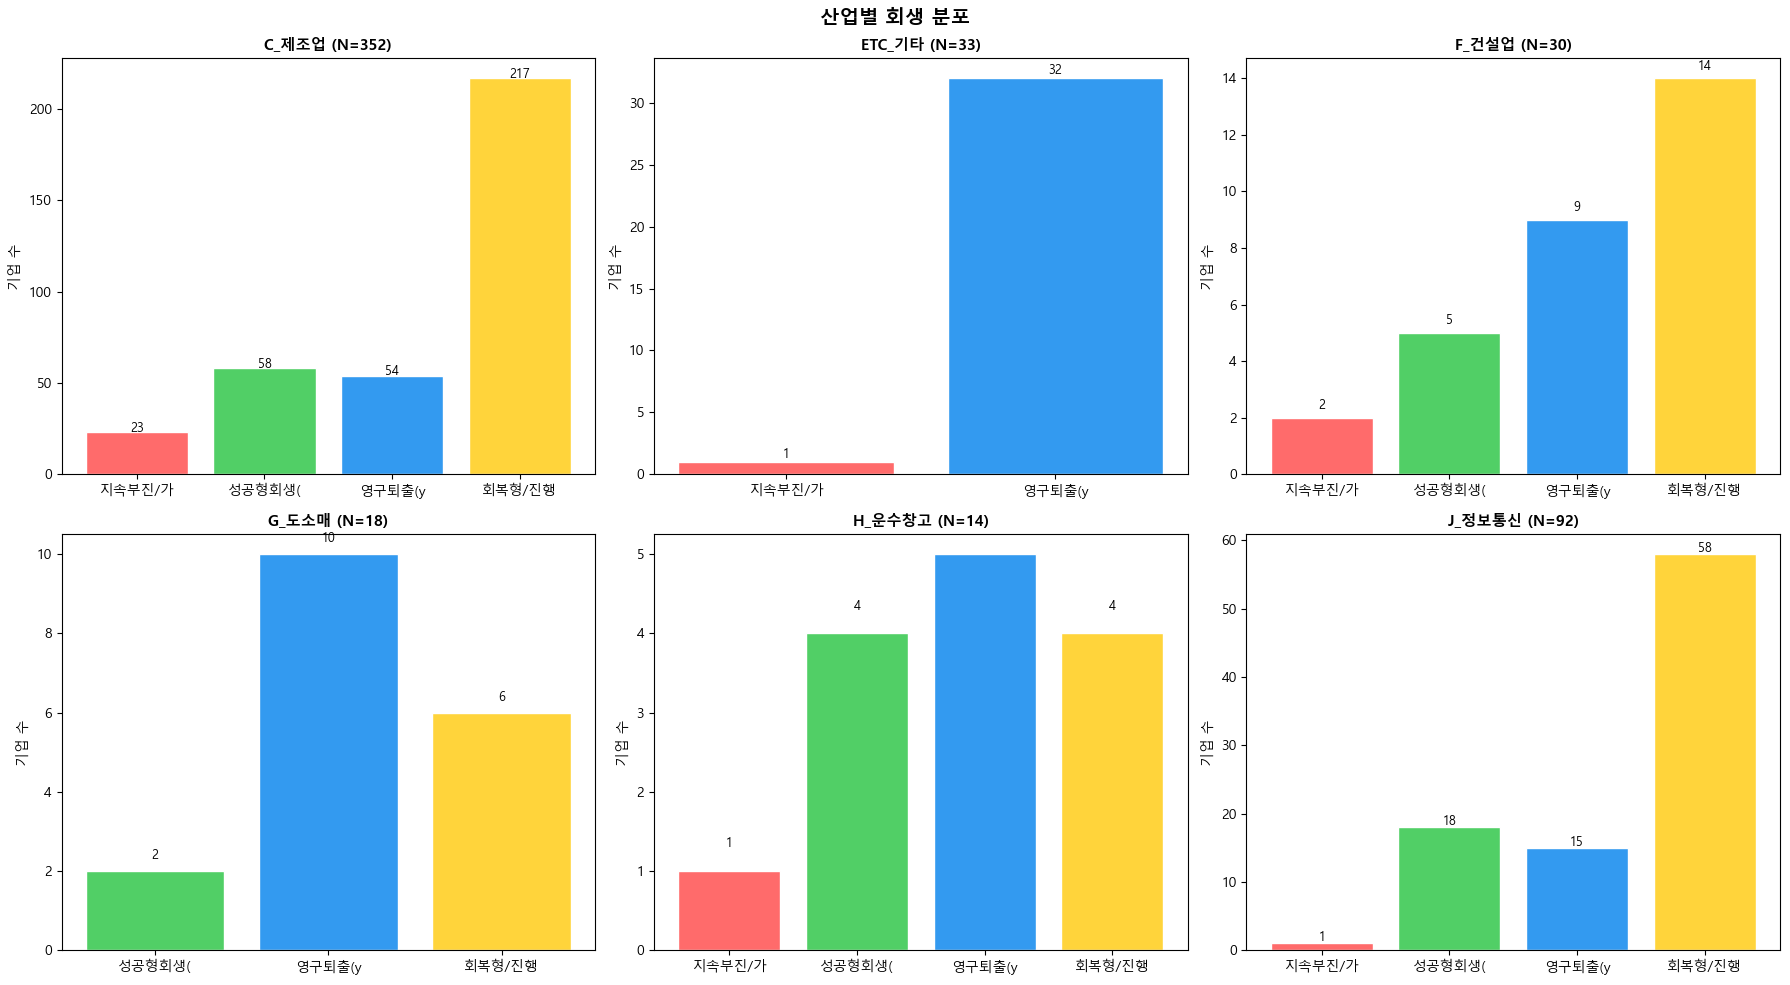


산업별 성공(y=1) vs 부진(y=0) 핵심 재무:

  C_제조업:
    ROA_L                 : 성공 +0.423 vs 부진 +0.236 (+0.186)
    debt_ratio_L          : 성공 +0.282 vs 부진 +0.155 (+0.128)
    equity_ratio_L        : 성공 -0.282 vs 부진 -0.155 (-0.128)
    OCF_ratio_L           : 성공 +0.334 vs 부진 +0.181 (+0.153)
    asset_turn_L          : 성공 +0.353 vs 부진 -0.170 (+0.522)

  F_건설업:
    ROA_L                 : 성공 +0.247 vs 부진 -0.012 (+0.259)
    debt_ratio_L          : 성공 +0.654 vs 부진 +0.344 (+0.310)
    equity_ratio_L        : 성공 -0.654 vs 부진 -0.344 (-0.310)
    OCF_ratio_L           : 성공 +0.458 vs 부진 +0.095 (+0.363)
    asset_turn_L          : 성공 +0.312 vs 부진 +0.743 (-0.431)

  K_금융보험:
    ROA_L                 : 성공 +0.262 vs 부진 -0.045 (+0.307)
    debt_ratio_L          : 성공 +0.205 vs 부진 -0.047 (+0.253)
    equity_ratio_L        : 성공 -0.205 vs 부진 +0.047 (-0.253)
    OCF_ratio_L           : 성공 +0.227 vs 부진 +0.036 (+0.191)
    asset_turn_L          : 성공 +0.378 vs 부진 -0.040 (+0.418)


In [27]:
# ══════════════════════════════════════════════════════════════════
# Phase 6-D: 산업별 포렌식 보고서
# ══════════════════════════════════════════════════════════════════
print('=' * 70)
print('   산업별 자본잠식 회생/퇴출 동인 포렌식 보고서')
print('=' * 70)

industry_label = df_proc.groupby(['ksic', 'y']).size().unstack(fill_value=0)
industry_label.columns = [label_map.get(c, str(c)) for c in industry_label.columns]
print('\n산업별 분포:')
print(industry_label.to_string())

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes_flat = axes.flatten()
for ax_i, ind in enumerate(sorted(df_proc['ksic'].unique())[:6]):
    ax = axes_flat[ax_i]
    ind_data = df_proc[df_proc['ksic'] == ind]
    y_counts = ind_data['y'].value_counts().sort_index()
    colors_ind = ['#FF6B6B', '#51CF66', '#339AF0', '#FFD43B']
    bars = ax.bar(
        [label_map.get(k, str(k))[:6] for k in y_counts.index],
        y_counts.values,
        color=[colors_ind[k] if k < len(colors_ind) else '#CED4DA' for k in y_counts.index],
        edgecolor='white'
    )
    ax.set_title(f'{ind} (N={len(ind_data)})', fontsize=11, fontweight='bold')
    ax.set_ylabel('기업 수')
    for b in bars:
        ax.annotate(f'{int(b.get_height())}', (b.get_x()+b.get_width()/2, b.get_height()+0.3),
                    ha='center', fontsize=9)
for i in range(len(df_proc['ksic'].unique()), 6):
    if i < len(axes_flat): axes_flat[i].set_visible(False)
plt.suptitle('산업별 회생 분포', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

# 성공 vs 부진 비교
key_ratios = ['ROA_L', 'debt_ratio_L', 'equity_ratio_L', 'OCF_ratio_L', 'asset_turn_L']
available_ratios = [r for r in key_ratios if r in df_proc.columns]

print('\n산업별 성공(y=1) vs 부진(y=0) 핵심 재무:')
for ind in sorted(df_proc['ksic'].unique()):
    ind_data = df_proc[df_proc['ksic'] == ind]
    success = ind_data[ind_data['y'] == 1]
    distress = ind_data[ind_data['y'] == 0]
    if len(success) < 2 or len(distress) < 2: continue
    print(f'\n  {ind}:')
    for r in available_ratios:
        s_med = success[r].median()
        d_med = distress[r].median()
        diff = s_med - d_med
        arrow = '+' if diff > 0 else '-'
        print(f'    {r:22s}: 성공 {s_med:+.3f} vs 부진 {d_med:+.3f} ({arrow}{abs(diff):.3f})')

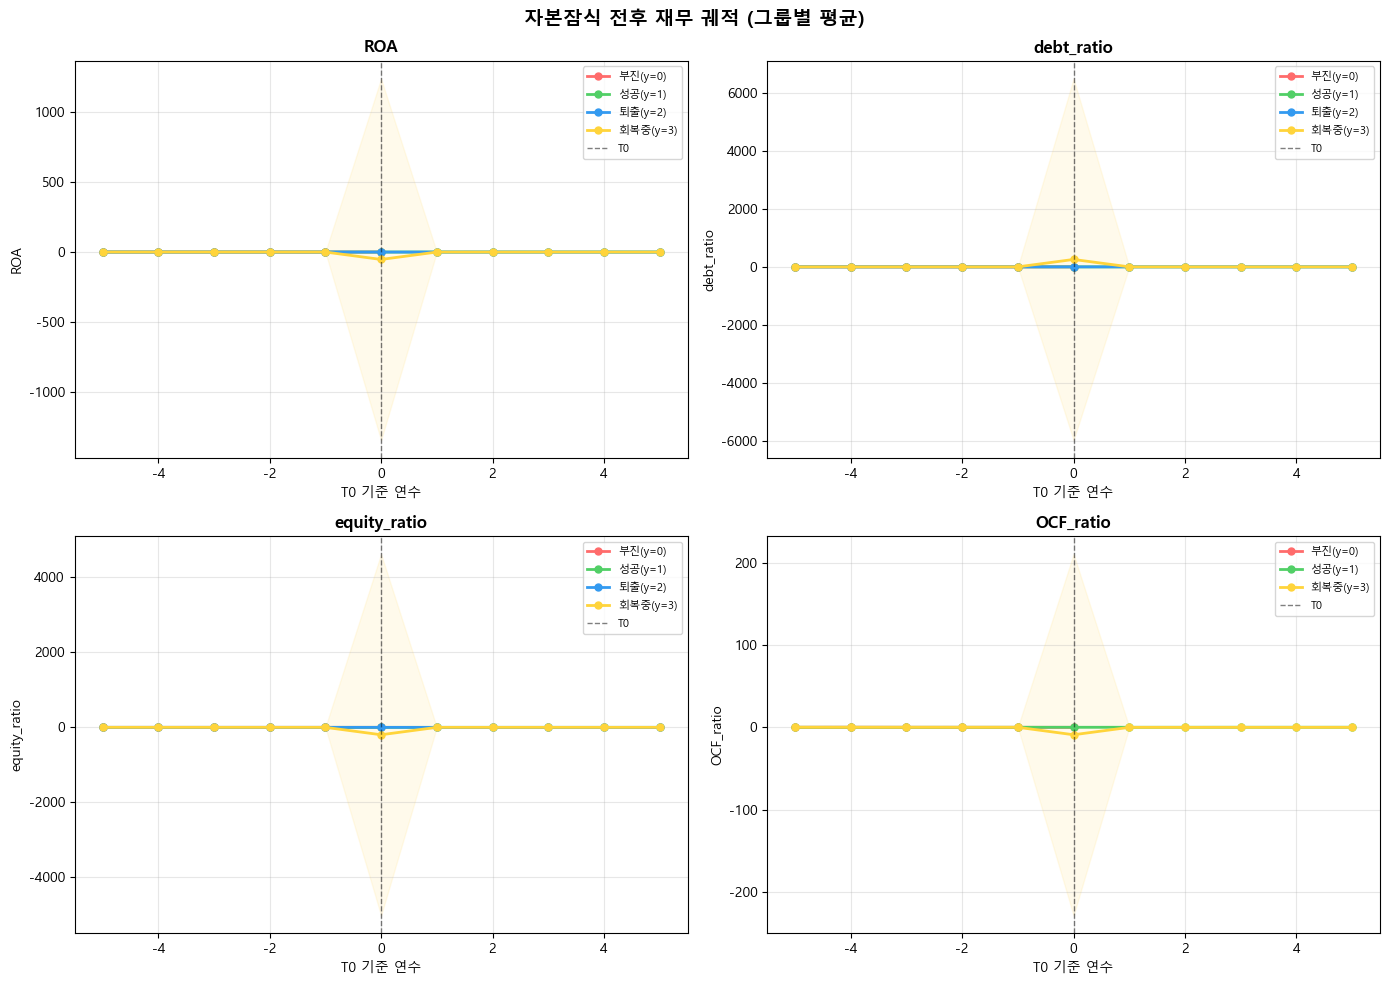

[자동 해석] 재무 궤적 분석:
  ROA: 성공군 변화 +0.034 vs 부진군 +nan
  debt_ratio: 성공군 변화 -0.057 vs 부진군 +nan
  equity_ratio: 성공군 변화 +0.057 vs 부진군 +nan
  OCF_ratio: 성공군 변화 +0.029 vs 부진군 +nan


In [28]:
# ══════════════════════════════════════════════════════════════════
# Phase 6-E: 재무 궤적(Trajectory) 분석
# ══════════════════════════════════════════════════════════════════
traj_feats = ['ROA', 'debt_ratio', 'equity_ratio', 'OCF_ratio']
traj_data = []

for _, base_row in df_model.iterrows():
    fid = base_row['코드']; t0 = int(base_row['T0']); y_val = int(base_row['y'])
    firm_data = df_feat[df_feat[COL['id']] == fid].set_index(COL['year'])
    for yr in firm_data.index:
        t_rel = yr - t0
        if abs(t_rel) > 5: continue
        row_t = {'코드': fid, 'y': y_val, 't_rel': t_rel}
        for fc in traj_feats:
            row_t[fc] = firm_data[fc].get(yr, np.nan)
        traj_data.append(row_t)

df_traj = pd.DataFrame(traj_data)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
group_colors = {0: '#FF6B6B', 1: '#51CF66', 2: '#339AF0', 3: '#FFD43B'}
group_labels = {0: '부진(y=0)', 1: '성공(y=1)', 2: '퇴출(y=2)', 3: '회복중(y=3)'}

for ax_i, feat in enumerate(traj_feats):
    ax = axes[ax_i // 2][ax_i % 2]
    for y_grp in sorted(df_traj['y'].unique()):
        grp_data = df_traj[df_traj['y'] == y_grp]
        mean_traj = grp_data.groupby('t_rel')[feat].agg(['mean', 'std', 'count']).reset_index()
        mean_traj = mean_traj[mean_traj['count'] >= 5]
        if len(mean_traj) < 2: continue
        ax.plot(mean_traj['t_rel'], mean_traj['mean'], 'o-',
                color=group_colors.get(y_grp, 'gray'),
                label=group_labels.get(y_grp, f'y={y_grp}'), lw=2, markersize=5)
        ax.fill_between(mean_traj['t_rel'],
            mean_traj['mean'] - mean_traj['std'],
            mean_traj['mean'] + mean_traj['std'],
            alpha=0.1, color=group_colors.get(y_grp, 'gray'))
    ax.axvline(0, color='black', ls='--', lw=1, alpha=0.5, label='T0')
    ax.set_title(feat, fontsize=12, fontweight='bold')
    ax.set_xlabel('T0 기준 연수'); ax.set_ylabel(feat)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.suptitle('자본잠식 전후 재무 궤적 (그룹별 평균)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

# 자동 해석
print('[자동 해석] 재무 궤적 분석:')
for feat in traj_feats:
    s_data = df_traj[(df_traj['y']==1) & (df_traj['t_rel'].between(-1,3))].groupby('t_rel')[feat].mean()
    d_data = df_traj[(df_traj['y']==0) & (df_traj['t_rel'].between(-1,3))].groupby('t_rel')[feat].mean()
    if len(s_data) >= 2 and len(d_data) >= 2:
        s_change = s_data.iloc[-1] - s_data.iloc[0]
        d_change = d_data.iloc[-1] - d_data.iloc[0]
        print(f'  {feat}: 성공군 변화 {s_change:+.3f} vs 부진군 {d_change:+.3f}')
        if s_change > d_change:
            print(f'    -> 성공형은 {feat}를 적극 개선. 핵심 회생 지표.')

   기업 포렌식 진단 리포트: 유수홀딩스 (V8)

  [기본 정보]
     코드: A000700 | 산업: J_정보통신
     클러스터: J_정보통신-C0
     분류: 성공형회생(y=1)
     T0: 2013 | 탈출: 2014
     잠식유형: partial
     Pre-distress: 정상

  [SHAP 회생/실패 동인]
     1. inv_turn                 : |SHAP|=1.7429 (- 위험 증가)
     2. OPM                      : |SHAP|=1.6300 (+ 회생 기여)
     3. ocf_std5                 : |SHAP|=0.6722 (- 위험 증가)
     4. int_coverage             : |SHAP|=0.5696 (+ 회생 기여)
     5. debt_ratio               : |SHAP|=0.3538 (+ 회생 기여)


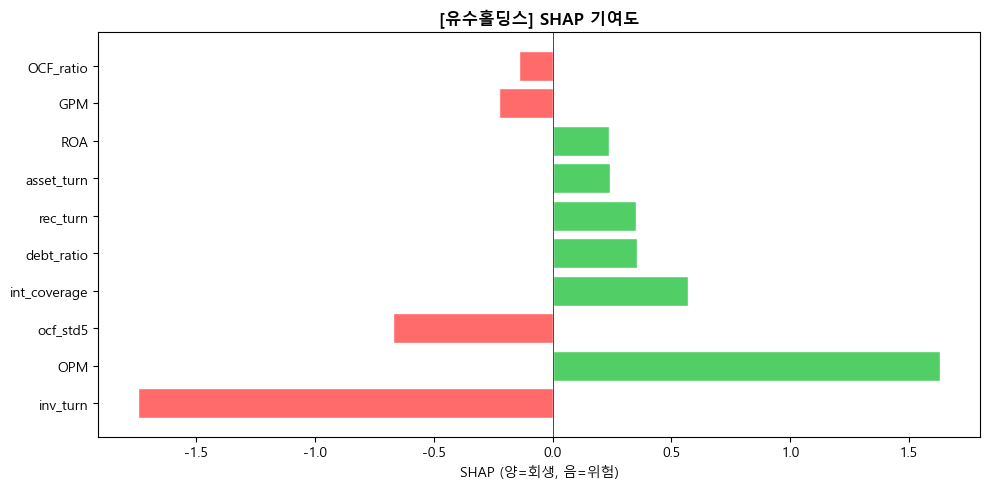


  [SHAP 자동 해석]
     회생 기여 요인: OPM, int_coverage, debt_ratio
     -> 이 지표들이 양호하여 회생 가능성을 높이고 있습니다.
     위험 증가 요인: inv_turn, ocf_std5
     -> 이 지표를 우선 개선하면 회생 확률이 향상됩니다.

  [궤적 분석]


  [궤적 자동 해석]
     ROA: T0=-0.061 -> T+5=0.047 (개선)
     debt_ratio: T0=0.934 -> T+5=0.387 (악화)
     equity_ratio: T0=0.066 -> T+5=0.613 (개선)
     OCF_ratio: T0=0.056 -> T+5=0.008 (악화)

  [CBR V2 유사 성공기업]
     1. 서울바이오시스 (유사도: 0.941 [L=0.902, D=1.000], C_제조업-C0)
     2. 아시아나항공 (유사도: 0.893 [L=0.821, D=1.000], C_제조업-C0)
     3. 깨끗한나라 (유사도: 0.818 [L=0.697, D=1.000], K_금융보험-C0)
  [CBR 해석] 위 기업들은 유사한 재무 프로파일에서 성공적으로 회생함.
     이들의 전략(비용구조, 자산효율)을 벤치마킹할 것을 권고.

  [산업 비교] J_정보통신
     ROA_L                 : +0.317 (산업 상위 34%)
     debt_ratio_L          : +0.854 (산업 상위 12%)
     equity_ratio_L        : -0.854 (산업 하위 11%)
     OCF_ratio_L           : +0.622 (산업 상위 20%)
     asset_turn_L          : +0.574 (산업 상위 24%)

  [V8 근본 원인 진단 — Waterfall]
     기간: T0=2013 → T+2(2015) | ΔNI=+706,527백만원
     영업이익 개선           : +38.7% (Δ=+273,767)
     재무비용 절감           : +58.3% (Δ=+411,678)
     기타(자산처분 등)        : +3.0% (Δ=+21,082)
     → 1차 원인: 재무비용 절감 (58.3%)
       세부: 이자비용 감소 → DART 주요사항보고서 자본구조 공시 확인



In [29]:
# ══════════════════════════════════════════════════════════════════
# Phase 6-F: 사용자 지정 기업 포렌식 리포트 (V8 강화)
#   V8 추가: Waterfall 근본 원인 진단 + 매출 이상 신호 감지
# ══════════════════════════════════════════════════════════════════
company_list = df_proc[['코드', 'y', 'ksic', 'cluster_id']].copy()
company_list = company_list.merge(
    df_feat.drop_duplicates(COL['id'])[[COL['id'], COL['name']]],
    left_on='코드', right_on=COL['id'], how='left'
)
company_list['display'] = (company_list[COL['name']].astype(str)
                           + ' [' + company_list['y'].map(label_map).astype(str) + ']')

# 상태별 맞춤형 추천
RECOMMENDATIONS = {
    0: [
        '부채 구조조정: 단기차입금 → 장기전환 또는 채무 재조정 협상',
        '비핵심 자산 매각: 유형자산/비영업자산 처분으로 유동성 확보',
        '원가 절감: 매출원가율 및 판관비 절감 프로그램 도입',
        '전략적 투자자 유치: 자본 확충을 위한 제3자 배정 증자 검토',
    ],
    1: [
        '현금 버퍼 유지: 매출 대비 현금성 자산 15% 이상 확보',
        'R&D 지속 투자: 경쟁력 유지를 위한 연구개발비 일정 수준 유지',
        '배당 정책 안정화: 재무 안정 확인 후 점진적 배당 재개',
        '리스크 모니터링: 영업이익률 및 부채비율 분기별 점검',
    ],
    2: [
        '(상장폐지) 투자자 유의사항 확인',
        '유사 업종 잔존 기업의 회생 사례 참조',
    ],
    3: [
        '비용 통제: 판관비 중 재량적 비용(광고/접대) 우선 절감',
        '자본 확충: 유상증자 또는 전환사채 발행 검토',
        '영업이익 흑자 전환: 3년 연속 흑자 시 성공형 재분류 가능',
        '산업 평균 대비 약점 지표 집중 개선',
    ]
}


def generate_company_report(company_code):
    firm_info = company_list[company_list['코드'] == company_code]
    if firm_info.empty:
        print(f'기업 코드 {company_code} 미발견')
        return

    firm_name    = firm_info[COL['name']].iloc[0]
    firm_y       = int(firm_info['y'].iloc[0])
    firm_ksic    = firm_info['ksic'].iloc[0]
    firm_cluster = firm_info['cluster_id'].iloc[0]

    print('=' * 65)
    print(f'   기업 포렌식 진단 리포트: {firm_name} (V8)')
    print('=' * 65)
    print(f'\n  [기본 정보]')
    print(f'     코드: {company_code} | 산업: {firm_ksic}')
    print(f'     클러스터: {firm_cluster}')
    print(f'     분류: {label_map.get(firm_y, "Unknown")}')

    t0_info = df_model[df_model['코드'] == company_code]
    if not t0_info.empty:
        t0      = int(t0_info['T0'].iloc[0])
        t_exit  = t0_info['T_exit'].iloc[0]
        imp_type = 'complete' if t0_info['imp_complete'].iloc[0] else 'partial'
        print(f'     T0: {t0} | 탈출: {int(t_exit) if pd.notna(t_exit) else "미탈출"}')
        print(f'     잠식유형: {imp_type}')
        pre_d = int(t0_info['pre_distress_flag'].iloc[0])
        print(f'     Pre-distress: {"위기 전조 감지" if pre_d else "정상"}')

    # ── 1. SHAP 분석 + 자동 해석 ──
    print(f'\n  [SHAP 회생/실패 동인]')
    firm_pp = df_pp[df_pp['코드'] == company_code]
    if len(firm_pp) > 0 and SHAP_AVAILABLE and explainer is not None:
        X_firm = firm_pp[PP_X_COLS].values
        shap_firm = explainer.shap_values(X_firm)
        shap_firm_arr = shap_firm if isinstance(shap_firm, np.ndarray) else shap_firm[1]
        mean_shap = np.abs(shap_firm_arr).mean(axis=0)
        top_idx = np.argsort(mean_shap)[::-1][:CONFIG['REPORT_TOP_N']]

        positive_factors = []
        negative_factors = []
        for rank, fi in enumerate(top_idx, 1):
            fname_s = feat_names[fi]
            val_s = mean_shap[fi]
            dir_val = shap_firm_arr[:, fi].mean()
            if dir_val > 0:
                positive_factors.append(fname_s)
                print(f'     {rank}. {fname_s:25s}: |SHAP|={val_s:.4f} (+ 회생 기여)')
            else:
                negative_factors.append(fname_s)
                print(f'     {rank}. {fname_s:25s}: |SHAP|={val_s:.4f} (- 위험 증가)')

        # SHAP Waterfall
        fig, ax = plt.subplots(figsize=(10, 5))
        firm_shap_mean = shap_firm_arr.mean(axis=0)
        sorted_idx = np.argsort(np.abs(firm_shap_mean))[::-1][:10]
        sorted_names = [feat_names[i] for i in sorted_idx]
        sorted_vals  = firm_shap_mean[sorted_idx]
        colors_w = ['#51CF66' if v > 0 else '#FF6B6B' for v in sorted_vals]
        ax.barh(range(len(sorted_names)), sorted_vals, color=colors_w, edgecolor='white')
        ax.set_yticks(range(len(sorted_names)))
        ax.set_yticklabels(sorted_names)
        ax.set_title(f'[{firm_name}] SHAP 기여도', fontsize=12, fontweight='bold')
        ax.set_xlabel('SHAP (양=회생, 음=위험)')
        ax.axvline(0, color='black', lw=0.5)
        plt.tight_layout(); plt.show()

        print(f'\n  [SHAP 자동 해석]')
        if positive_factors:
            print(f'     회생 기여 요인: {", ".join(positive_factors[:3])}')
            print(f'     -> 이 지표들이 양호하여 회생 가능성을 높이고 있습니다.')
        if negative_factors:
            print(f'     위험 증가 요인: {", ".join(negative_factors[:3])}')
            print(f'     -> 이 지표를 우선 개선하면 회생 확률이 향상됩니다.')
    else:
        print('     (데이터 부족 또는 SHAP 미사용)')

    # ── 2. 재무 궤적 + 자동 해석 ──
    print(f'\n  [궤적 분석]')
    firm_traj = df_traj[df_traj['코드'] == company_code].sort_values('t_rel')
    if len(firm_traj) > 0:
        fig, axes_t = plt.subplots(1, len(traj_feats), figsize=(16, 4))
        for ti, feat in enumerate(traj_feats):
            ax_t = axes_t[ti]
            for y_grp in [0, 1]:
                grp = df_traj[df_traj['y'] == y_grp]
                grp_mean = grp.groupby('t_rel')[feat].agg(['mean', 'std']).reset_index()
                grp_mean = grp_mean[grp_mean['t_rel'].between(-3, 5)]
                if len(grp_mean) < 2:
                    continue
                ax_t.fill_between(grp_mean['t_rel'],
                    grp_mean['mean'] - grp_mean['std'],
                    grp_mean['mean'] + grp_mean['std'],
                    alpha=0.15, color=group_colors[y_grp])
                ax_t.plot(grp_mean['t_rel'], grp_mean['mean'], '--',
                          color=group_colors[y_grp], alpha=0.5, lw=1,
                          label=f'{group_labels[y_grp]} 평균')
            ft = firm_traj[firm_traj[feat].notna()]
            ax_t.plot(ft['t_rel'], ft[feat], 'ko-', lw=2.5, markersize=6,
                      label=firm_name, zorder=5)
            ax_t.axvline(0, color='black', ls='--', lw=0.8, alpha=0.5)
            ax_t.set_title(feat, fontsize=10, fontweight='bold')
            ax_t.set_xlabel('T0 기준 연수')
            ax_t.legend(fontsize=7, loc='best')
            ax_t.grid(True, alpha=0.2)
        plt.suptitle(f'[{firm_name}] 재무 궤적', fontsize=12, fontweight='bold')
        plt.tight_layout(); plt.show()

        print(f'  [궤적 자동 해석]')
        for feat in traj_feats:
            ft = firm_traj[['t_rel', feat]].dropna()
            if len(ft) >= 2:
                t0_val = ft[ft['t_rel'] == 0][feat].values
                latest = ft.iloc[-1]
                if len(t0_val) > 0:
                    change = latest[feat] - t0_val[0]
                    trend = '개선' if change > 0.01 else ('악화' if change < -0.01 else '유지')
                    print(f'     {feat}: T0={t0_val[0]:.3f} -> T+{int(latest["t_rel"])}={latest[feat]:.3f} ({trend})')

    # ── 3. CBR V2 유사 성공기업 매칭 ──
    print(f'\n  [CBR V2 유사 성공기업]')
    cbr_result = find_similar_success(company_code)
    if len(cbr_result) > 0:
        for rank, (_, r) in enumerate(cbr_result.iterrows(), 1):
            sim_name = r.get(COL['name'], r['코드'])
            print(f'     {rank}. {sim_name} (유사도: {r["similarity"]:.3f} '
                  f'[L={r["sim_level"]:.3f}, D={r["sim_delta"]:.3f}], '
                  f'{r["cluster_id"]})')
        print(f'  [CBR 해석] 위 기업들은 유사한 재무 프로파일에서 성공적으로 회생함.')
        print(f'     이들의 전략(비용구조, 자산효율)을 벤치마킹할 것을 권고.')
    else:
        print('     매칭 결과 없음')

    # ── 4. OpenDART ──
    if company_code in delisting_reasons:
        info = delisting_reasons[company_code]
        print(f'\n  [OpenDART 공시]')
        print(f'     분류: {cat_map.get(info["category"], info["category"])}')
        for r in info['reasons'][:5]:
            print(f'     - {r}')

    # ── 5. 산업 내 위치 ──
    print(f'\n  [산업 비교] {firm_ksic}')
    same_ind = df_proc[df_proc['ksic'] == firm_ksic]
    firm_row = df_proc[df_proc['코드'] == company_code]
    key_ratios   = ['ROA_L', 'debt_ratio_L', 'equity_ratio_L', 'OCF_ratio_L', 'asset_turn_L']
    available_ratios = [r for r in key_ratios if r in df_proc.columns]
    if not firm_row.empty:
        for r in available_ratios:
            val    = firm_row[r].iloc[0]
            pctile = (same_ind[r] < val).mean() * 100
            status = '상위' if pctile >= 50 else '하위'
            print(f'     {r:22s}: {val:+.3f} (산업 {status} {abs(100-pctile) if pctile>=50 else abs(pctile):.0f}%)')

    # ── 6. V8 Waterfall 근본 원인 진단 ──
    print(f'\n  [V8 근본 원인 진단 — Waterfall]')
    rc = decompose_variance(company_code)
    if rc:
        _d_lbl_r = WATERFALL_LABELS  # Phase 5-E 전역 상수 재사용
        _delta_r = {
            'op_contribution':    rc.get('delta_op',    np.nan),
            'fin_contribution':   rc.get('delta_fin',   np.nan),
            'other_contribution': rc.get('delta_other', np.nan),
        }
        ni_c = rc.get('ni_change', np.nan)
        ni_str = f'{ni_c:+,.0f}백만원' if pd.notna(ni_c) else 'N/A'
        print(f'     기간: T0={rc["T0"]} → T+{rc["T_end"]-rc["T0"]}({rc["T_end"]}) | ΔNI={ni_str}')
        for k, lbl in _d_lbl_r.items():
            v  = rc.get(k, np.nan)
            dv = _delta_r.get(k, np.nan)
            if pd.notna(v):
                sign = '+' if v > 0 else ''
                dstr = f' (Δ={dv:+,.0f})' if pd.notna(dv) else ''
                print(f'     {lbl:18s}: {sign}{v*100:.1f}%{dstr}')
        primary = rc.get('primary_driver', 'unknown')
        pct_r   = rc.get('primary_pct', 0)
        print(f'     → 1차 원인: {_d_lbl_r.get(primary, primary)} ({pct_r:.1f}%)')
        if rc.get('op_drilldown'):
            sub_r = rc['op_drilldown'].get('sub_driver', '')
            dr_r  = rc.get('delta_revenue', np.nan)
            dg_r  = rc.get('delta_gp', np.nan)
            if sub_r == 'revenue_growth' and pd.notna(dr_r):
                print(f'       세부: 매출성장(ΔSales={dr_r:+,.0f}) → DART 제품별 매출 확인 권고')
            elif sub_r == 'cost_reduction' and pd.notna(dg_r):
                print(f'       세부: 원가절감(ΔGP={dg_r:+,.0f}) → 비용 성격별 분류표 확인 권고')
        if primary == 'fin_contribution':
            print(f'       세부: 이자비용 감소 → DART 주요사항보고서 자본구조 공시 확인')
    else:
        print('     (데이터 부족 — 분석 불가)')

    # ── 7. V8 매출 이상 신호 감지 ──
    print(f'\n  [V8 매출 이상 신호 감지]')
    rev_ins = diagnose_revenue_source(company_code, verbose=False)
    if rev_ins:
        for ins in rev_ins[-3:]:
            yr    = ins.get('year', '?')
            chg   = ins.get('rev_change_pct', 0)
            cause = ins.get('likely_cause', 'N/A')
            print(f'     {yr}년: 매출 {chg:+.1f}% → {cause}')
            if 'marketing_alert' in ins:
                print(f'       ⚠ {ins["marketing_alert"]}')
    else:
        print('     이상 신호 없음')

    # ── 8. 맞춤형 추천 ──
    print(f'\n  [맞춤형 권고사항] (상태: {label_map.get(firm_y, "Unknown")})')
    recs = RECOMMENDATIONS.get(firm_y, [])
    for i, rec in enumerate(recs, 1):
        print(f'     {i}. {rec}')

    print('\n' + '=' * 65)


# 테스트
test_firm = (company_list[company_list['y'] == 1]['코드'].iloc[0]
             if (company_list['y'] == 1).any() else company_list['코드'].iloc[0])
generate_company_report(test_firm)

In [30]:
# ══════════════════════════════════════════════════════════════════
# Phase 6-G: 사용자 지정 검색 인터페이스
# ══════════════════════════════════════════════════════════════════
if WIDGETS_AVAILABLE:
    industry_companies = {}
    for ind in sorted(company_list['ksic'].unique()):
        firms = company_list[company_list['ksic'] == ind].sort_values(COL['name'])
        industry_companies[ind] = firms

    industry_dropdown = widgets.Dropdown(
        options=sorted(company_list['ksic'].unique()),
        description='산업군:',
        style={'description_width': '80px'},
        layout=widgets.Layout(width='300px')
    )
    company_dropdown = widgets.Dropdown(
        options=[], description='기업명:',
        style={'description_width': '80px'},
        layout=widgets.Layout(width='500px')
    )
    output_area = widgets.Output()

    def update_companies(*args):
        ind = industry_dropdown.value
        firms = industry_companies.get(ind, pd.DataFrame())
        if len(firms) > 0:
            options = [(row['display'], row['코드']) for _, row in firms.iterrows()]
            company_dropdown.options = options
        else:
            company_dropdown.options = []

    industry_dropdown.observe(update_companies, 'value')
    update_companies()

    btn = widgets.Button(description='V7 포렌식 리포트', button_style='success',
                         layout=widgets.Layout(width='250px', height='35px'))

    def on_click(b):
        with output_area:
            clear_output()
            code = company_dropdown.value
            if code:
                generate_company_report(code)
            else:
                print('기업을 선택해주세요.')

    btn.on_click(on_click)

    print('V7 포렌식 리포트 생성기 (산업 -> 기업 -> 버튼)')
    ui = widgets.VBox([
        widgets.HBox([industry_dropdown, company_dropdown]),
        btn, output_area
    ])
    display(ui)
else:
    print('ipywidgets 미설치 -- 텍스트 모드')
    print('  generate_company_report("기업코드")')

V7 포렌식 리포트 생성기 (산업 -> 기업 -> 버튼)


## Phase 6-H: 맞춤형 재무제표 입력 기반 CBR 비교 엔진 (PDF / XBRL)

| 기능 | 설명 |
|---|---|
| **파일 자동탐색** | `BUN_SEOK` 에서 회사명으로 검색 |
| **XBRL 파싱** | DART IFRS/K-GAAP XBRL 원문 (.xbrl, .zip) |
| **PDF 파싱** | 사업보고서 PDF에서 재무제표 텍스트/테이블 추출 |
| **유사도 계산** | Phase 2-C 스케일 파라미터 적용 + Cosine Similarity |
| **수동 입력** | 딕셔너리 직접 입력 가능 |

In [31]:
# ══════════════════════════════════════════════════════════════════
# Phase 6-H Part-1: 파일 파서 및 보조 함수
# ══════════════════════════════════════════════════════════════════
import os, re as _re_h, glob, zipfile, io as _io_h, tempfile, shutil

try:
    import pdfplumber
    _PDFPLUMBER = True
except ImportError:
    _PDFPLUMBER = False
    print('[경고] pdfplumber 미설치. pip install pdfplumber 로 설치하세요.')

BUN_SEOK_DIR = r'BUN_SEOK'

# ─── 파일 탐색기 ───────────────────────────────────────────────
def find_financial_file(company_name=None, base_dir=BUN_SEOK_DIR):
    '''
    BUN_SEOK 폴더에서 PDF / XBRL 파일을 탐색한다.
    Returns list of (file_type, path) tuples.
    file_type: pdf | xbrl | xbrl_zip
    '''
    results = []
    if not os.path.exists(base_dir):
        print(f'[경고] 폴더 없음: {base_dir}')
        return results

    for item in os.listdir(base_dir):
        item_path = os.path.join(base_dir, item)
        if company_name:
            if company_name not in item:
                continue
        ext = os.path.splitext(item)[1].lower()
        if ext == '.pdf':
            results.append(('pdf', item_path))
        elif ext == '.zip':
            results.append(('xbrl_zip', item_path))
        elif os.path.isdir(item_path):
            xbrl_in_dir = [os.path.join(item_path, f)
                           for f in os.listdir(item_path) if f.endswith('.xbrl')]
            if xbrl_in_dir:
                results.append(('xbrl', xbrl_in_dir[0]))

    if not results and company_name:
        all_items = os.listdir(base_dir) if os.path.exists(base_dir) else []
        print(f'[안내] "{company_name}" 파일 미발견. {base_dir} 내 파일:')
        for it in all_items:
            print(f'   - {it}')
    return results


# ─── XBRL 파서 ────────────────────────────────────────────────
def _parse_xbrl(xbrl_path):
    # DART XBRL 파일에서 핵심 재무 항목 추출 (원화 원단위 -> 백만원 변환)
    import xml.etree.ElementTree as ET
    NS = 'http://www.xbrl.org/2003/instance'

    try:
        tree = ET.parse(xbrl_path)
    except ET.ParseError as e:
        print(f'[XBRL] 파싱 오류: {e}')
        return {}

    root = tree.getroot()

    # ── 컨텍스트 분류 (CFY/PFY, d=flow, e=instant, 연결/별도) ──
    ctx_map = {}
    for c in root.findall('{%s}context' % NS):
        cid = c.get('id', '')
        m = _re_h.match(r'^(CFY|PFY|BPFY)(\d{4})(d|e)FY', cid)
        if not m:
            continue
        prefix, yr, kind = m.group(1), int(m.group(2)), m.group(3)
        n_axes = cid.count('Axis')
        is_consol = ('ConsolidatedMember' in cid and 'SeparateMember' not in cid)
        is_sep    = ('SeparateMember' in cid and 'ConsolidatedMember' not in cid)
        if n_axes == 1:
            stmt = 'consol' if is_consol else ('sep' if is_sep else None)
        else:
            stmt = None
        if stmt:
            ctx_map[cid] = {'prefix': prefix, 'year': yr, 'kind': kind, 'stmt': stmt}

    if not ctx_map:
        print('[XBRL] 유효 컨텍스트 미발견. DART XBRL 표준 형식을 확인하세요.')
        return {}

    cur_yr = max(v['year'] for v in ctx_map.values())

    def _pick(kind, stmts=('consol', 'sep')):
        for s in stmts:
            for cid, info in ctx_map.items():
                if info['year'] == cur_yr and info['kind'] == kind and info['stmt'] == s:
                    return cid
        return None

    ctx_flow = _pick('d')
    ctx_inst = _pick('e')
    if not ctx_flow and not ctx_inst:
        print(f'[XBRL] {cur_yr}년도 컨텍스트 없음')
        return {}

    target_ctxs = set(filter(None, [ctx_flow, ctx_inst]))

    # ── 개념명 → 항목 키 매핑 (앞쪽 우선) ──
    _CONCEPT_PRIORITY = [
        ('asset',      ['Assets']),
        ('liability',  ['Liabilities']),
        ('equity',     ['Equity', 'EquityAttributableToOwnersOfParent']),
        ('ppe',        ['PropertyPlantAndEquipment']),
        ('rec',        ['CurrentTradeReceivables', 'TradeAndOtherCurrentReceivables']),
        ('inv',        ['Inventories']),
        ('ret_earn',   ['RetainedEarnings']),
        ('revenue',    ['Revenue']),
        ('gross',      ['GrossProfit']),
        ('op_income',  ['OperatingIncomeLoss', 'ProfitLossFromOperatingActivities']),
        ('net_income', ['ProfitLoss']),
        ('cost_sales', ['CostOfSales']),
        ('int_exp',    ['FinanceCosts', 'InterestExpensePaid']),
        ('ocf',        ['CashFlowsFromUsedInOperatingActivities']),
        ('depr',       ['DepreciationPropertyPlantAndEquipment']),
    ]
    local_to_key = {}
    for key, names in _CONCEPT_PRIORITY:
        for n in names:
            if n not in local_to_key:
                local_to_key[n] = key

    raw = {}
    for elem in root:
        if elem.get('contextRef', '') not in target_ctxs:
            continue
        local = elem.tag.split('}')[-1]
        if local not in local_to_key or not elem.text:
            continue
        key = local_to_key[local]
        if key in raw:
            continue
        try:
            raw[key] = float(elem.text)
        except (ValueError, TypeError):
            pass

    # ── 단위 변환: 원화 원단위 → 백만원 ──
    divisor = 1.0
    asset_val = raw.get('asset', 0)
    if asset_val > 1e11:          # 100조 원 이상 → 원단위
        divisor = 1e6
        print(f'[XBRL] 원화 원단위 감지 → 백만원 변환 (÷{divisor:.0e})')
    elif asset_val > 1e8:         # 1000억 이상 → 천원
        divisor = 1e3
        print(f'[XBRL] 천원 단위 감지 → 백만원 변환 (÷{divisor:.0e})')
    else:
        print(f'[XBRL] 기존 단위 유지 (추정: 백만원)')

    raw_mn = {k: v / divisor for k, v in raw.items()}

    # 이자비용 부호 정규화 (비용은 양수)
    if 'int_exp' in raw_mn and raw_mn['int_exp'] < 0:
        raw_mn['int_exp'] = abs(raw_mn['int_exp'])

    print(f'[XBRL] 파싱 완료: {cur_yr}년 | {len(raw_mn)}개 항목 | {os.path.basename(xbrl_path)}')
    return raw_mn


def _load_xbrl_zip(zip_path):
    # ZIP 파일에서 XBRL 추출 후 파싱
    tmp = tempfile.mkdtemp()
    try:
        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall(tmp)
        xbrl_found = []
        for root_w, _, files_w in os.walk(tmp):
            xbrl_found += [os.path.join(root_w, f) for f in files_w if f.endswith('.xbrl')]
        if not xbrl_found:
            print(f'[경고] ZIP 내 XBRL 없음: {zip_path}')
            return {}
        return _parse_xbrl(xbrl_found[0])
    finally:
        shutil.rmtree(tmp, ignore_errors=True)


# ─── PDF 파서 ──────────────────────────────────────────────────
def _parse_pdf(pdf_path):
    # 사업보고서 PDF에서 재무제표 항목 추출 (pdfplumber 기반)
    if not _PDFPLUMBER:
        print('[오류] pdfplumber 미설치. pip install pdfplumber')
        return {}

    KR_LABELS = {
        'asset':      ['자산총계', '자 산 총 계', '총자산'],
        'liability':  ['부채총계', '부 채 총 계', '총부채'],
        'equity':     ['자본총계', '자 본 총 계', '총자본'],
        'revenue':    ['매출액', '수익(매출액)', '영업수익'],
        'gross':      ['매출총이익', '매출 총이익'],
        'op_income':  ['영업이익', '영업손익', '영업이익(손실)'],
        'net_income': ['당기순이익', '당기순손익', '당기순이익(손실)', '분기순이익'],
        'ocf':        ['영업활동으로인한현금흐름', '영업활동현금흐름',
                       '영업활동으로 인한 현금흐름'],
        'ppe':        ['유형자산'],
        'rec':        ['매출채권'],
        'inv':        ['재고자산'],
        'int_exp':    ['이자비용', '금융원가'],
        'ret_earn':   ['이익잉여금'],
        'cost_sales': ['매출원가'],
    }
    label_to_key = {}
    for key, lbls in KR_LABELS.items():
        for lb in lbls:
            label_to_key[lb] = key

    def _clean_num(s):
        s = s.strip().replace(',', '').replace(' ', '')
        if s.startswith('(') and s.endswith(')'):
            s = '-' + s[1:-1]
        return float(s)

    raw = {}
    unit_mul = 1.0   # 최종적으로 백만원 단위로 저장

    with pdfplumber.open(pdf_path) as pdf:
        print(f'[PDF] {len(pdf.pages)}페이지 분석 중...')

        # 단위 감지 (앞 10페이지)
        for page in pdf.pages[:10]:
            txt = page.extract_text() or ''
            if '(단위 : 백만원)' in txt or '(단위:백만원)' in txt or '단위: 백만원' in txt:
                unit_mul = 1.0
                print('[PDF] 단위: 백만원')
                break
            elif '(단위 : 천원)' in txt or '(단위:천원)' in txt:
                unit_mul = 0.001    # 천원 → 백만원: ×0.001
                print('[PDF] 단위: 천원 → 백만원 변환')
                break
            elif '(단위 : 원)' in txt or '(단위:원)' in txt:
                unit_mul = 1e-6
                print('[PDF] 단위: 원 → 백만원 변환')
                break

        # 재무제표 페이지 식별
        fin_kws = ['재무상태표', '포괄손익계산서', '손익계산서', '현금흐름표', '재무제표']
        fin_pages = [i for i, p in enumerate(pdf.pages)
                     if any(k in (p.extract_text() or '') for k in fin_kws)]
        if not fin_pages:
            fin_pages = list(range(min(len(pdf.pages), 80)))

        for pi in fin_pages:
            if len(raw) >= len(KR_LABELS):
                break
            page = pdf.pages[pi]

            # ① 테이블 추출
            for tbl in (page.extract_tables() or []):
                for row in tbl:
                    if not row:
                        continue
                    cells = [str(c or '').strip() for c in row]
                    label_cell = cells[0]
                    for lb, key in label_to_key.items():
                        if lb in label_cell and key not in raw:
                            for vc in cells[1:]:
                                vc = vc.strip()
                                if not vc or vc in ('-', '—'):
                                    continue
                                try:
                                    raw[key] = _clean_num(vc) * unit_mul
                                    break
                                except (ValueError, TypeError):
                                    continue

            # ② 텍스트 라인 패턴 매칭 (테이블 실패 보완)
            if len(raw) < 5:
                for line in (page.extract_text() or '').split('\n'):
                    for lb, key in label_to_key.items():
                        if lb in line and key not in raw:
                            nums = _re_h.findall(r'[\-\(]?[\d,]+(?:\.\d+)?[\)]?', line)
                            for n in nums:
                                try:
                                    v = _clean_num(n)
                                    if abs(v) > 50:   # 50백만원 이상
                                        raw[key] = v * unit_mul
                                        break
                                except (ValueError, TypeError):
                                    continue

    if raw:
        print(f'[PDF] 파싱 완료: {len(raw)}개 항목 추출')
    else:
        print('[PDF] 자동 추출 실패. 수동 입력을 사용하세요.')
    return raw


# ─── 재무비율 계산 ─────────────────────────────────────────────
def compute_ratios_from_raw(raw):
    # 원시 재무항목(백만원 기준)에서 FEAT_COLS 재무비율 계산
    def _sdiv(a, b):
        if b and not np.isnan(float(b)) and float(b) != 0:
            return float(a) / float(b)
        return np.nan

    A   = raw.get('asset',      np.nan)
    D   = raw.get('liability',  np.nan)
    E   = raw.get('equity',     np.nan)
    R   = raw.get('revenue',    np.nan)
    OI  = raw.get('op_income',  np.nan)
    NI  = raw.get('net_income', np.nan)
    OCF = raw.get('ocf',        np.nan)
    G   = raw.get('gross',      np.nan)
    PPE = raw.get('ppe',        np.nan)
    REC = raw.get('rec',        np.nan)
    INV = raw.get('inv',        np.nan)
    INT = raw.get('int_exp',    np.nan)

    if np.isnan(G) and 'cost_sales' in raw and not np.isnan(R):
        G = float(R) - float(raw['cost_sales'])

    ratios = {
        'ROA':           _sdiv(NI,  A),
        'GPM':           _sdiv(G,   R),
        'OPM':           _sdiv(OI,  R),
        'OCF_ratio':     _sdiv(OCF, A),
        'debt_ratio':    _sdiv(D,   A),
        'cap_intensity': _sdiv(PPE, A),
        'rec_turn':      _sdiv(R,   REC),
        'inv_turn':      _sdiv(R,   INV),
        'asset_turn':    _sdiv(R,   A),
        'int_coverage':  _sdiv(OI,  INT),
        'equity_ratio':  _sdiv(E,   A),
        'ocf_std5':      np.nan,
    }

    print('\n[계산된 재무비율 (FEAT_COLS 기준)]:')
    for k, v in ratios.items():
        status = f'{v:+.4f}' if not np.isnan(v) else 'N/A'
        print(f'  {k:20s}: {status}')
    return ratios


# ─── 스케일링 (Phase 2-C 파라미터 적용) ───────────────────────
def _scale_input(ratios):
    # 입력 비율에 Phase 2-C winsor_params + scale_params 적용
    scaled = {}
    for fc in FEAT_COLS:
        col = f'{fc}_L'
        v = ratios.get(fc, np.nan)
        if np.isnan(v):
            scaled[col] = np.nan
            continue
        # Winsorization
        if col in winsor_params:
            v = float(np.clip(v, winsor_params[col]['lo'], winsor_params[col]['hi']))
        # Robust Scaling
        if col in scale_params:
            sp = scale_params[col]
            scaled[col] = (v - sp['med']) / sp['iqr']
        else:
            scaled[col] = v
    return scaled


print('Phase 6-H Part-1 로드 완료 (파서 함수 정의)')
print(f'  BUN_SEOK_DIR = {BUN_SEOK_DIR}')
print(f'  scale_params 키 수: {len(scale_params)}개')

In [32]:
# ══════════════════════════════════════════════════════════════════
# Phase 6-H Part-2: 맞춤형 CBR 비교 함수
# ══════════════════════════════════════════════════════════════════

def compare_custom_financials(custom_data, target_y=None, top_k=3, _from_raw=False):
    # 재무비율(또는 원시 재무항목) 딕셔너리를 입력받아 유사 기업을 검색/비교
    # custom_data: FEAT_COLS 비율 딕셔너리 또는 원시 항목 딕셔너리(_from_raw=True)
    # target_y: 0=부진 1=성공형 2=퇴출 3=회복중 None=전체
    # top_k: 출력 유사기업 수
    print('=' * 65)
    print('   맞춤형 재무구조 유사 기업 매칭 및 비교 리포트')
    print('=' * 65)

    # ① 입력 처리
    if _from_raw:
        ratios = compute_ratios_from_raw(custom_data)
    else:
        ratios = custom_data

    # ② 스케일링
    scaled_input = _scale_input(ratios)
    level_cols = [f'{fc}_L' for fc in FEAT_COLS]
    custom_vec = np.array([scaled_input.get(col, np.nan) for col in level_cols],
                          dtype=np.float64)

    valid_n = int((~np.isnan(custom_vec)).sum())
    print(f'\n유효 지표: {valid_n}/{len(level_cols)}개')
    if valid_n < 3:
        print('[오류] 유효 지표가 3개 미만 — 매칭 불가.')
        print('  자산총계(asset), 매출액(revenue), 영업이익(op_income) 등을 확인하세요.')
        return pd.DataFrame()

    # ③ 검색 풀 설정
    if target_y is not None:
        pool = df_proc[df_proc['y'] == target_y].copy()
        pool_label = label_map.get(target_y, str(target_y))
    else:
        pool = df_proc.copy()
        pool_label = '전체 자본잠식 경험 그룹'
    print(f'검색 대상: {pool_label} (N={len(pool):,}개)')

    # ④ 코사인 유사도 계산
    cbr_cols = [c for c in level_cols if c in df_proc.columns]
    c_vec = custom_vec[:len(cbr_cols)]

    sims = []
    for _, srow in pool.iterrows():
        r_vec = np.array([srow.get(c, np.nan) for c in cbr_cols], dtype=np.float64)
        valid = ~(np.isnan(c_vec) | np.isnan(r_vec))
        if valid.sum() < 3:
            continue
        try:
            sim = 1.0 - cosine_dist(c_vec[valid], r_vec[valid])
        except Exception:
            continue
        sims.append({
            '코드':        srow['코드'],
            'similarity':  float(sim),
            'cluster_id':  srow.get('cluster_id', 'Unknown'),
            'ksic':        srow.get('ksic', 'Unknown'),
            'y_raw':       int(srow.get('y', -1)),
            'y_label':     label_map.get(int(srow.get('y', -1)), 'Unknown'),
        })

    if not sims:
        print('[결과] 유사한 기업을 찾을 수 없습니다.')
        return pd.DataFrame()

    sim_df = (pd.DataFrame(sims)
              .sort_values('similarity', ascending=False)
              .head(top_k)
              .reset_index(drop=True))
    sim_df = sim_df.merge(
        df_feat.drop_duplicates(COL['id'])[[COL['id'], COL['name']]],
        left_on='코드', right_on=COL['id'], how='left'
    )

    # ⑤ 결과 출력
    compare_keys = ['ROA', 'GPM', 'OPM', 'OCF_ratio',
                    'debt_ratio', 'equity_ratio', 'asset_turn', 'int_coverage']
    avail_keys = [k for k in compare_keys if not np.isnan(ratios.get(k, np.nan))]

    print(f'\n[Top {top_k} 유사기업]')
    print('-' * 65)
    for rank, (_, row) in enumerate(sim_df.iterrows(), 1):
        fname = row.get(COL['name'], row['코드'])
        print(f'\n  {rank}. {fname} (코드: {row["코드"]})')
        print(f'     유사도: {row["similarity"]:.4f} | 산업: {row["ksic"]}')
        print(f'     분류:   {row["y_label"]} | 클러스터: {row["cluster_id"]}')

        match_row = df_proc[df_proc['코드'] == row['코드']]
        if not match_row.empty and avail_keys:
            print('     [주요 지표: 입력값(원비율) vs 매칭기업(스케일값) | 차이(스케일)]')
            for k in avail_keys[:6]:
                col_l = f'{k}_L'
                in_ratio  = ratios.get(k, np.nan)
                in_scaled = scaled_input.get(col_l, np.nan)
                m_scaled  = match_row[col_l].iloc[0] if col_l in match_row.columns else np.nan
                if np.isnan(in_ratio) or np.isnan(m_scaled):
                    continue
                diff = (in_scaled - m_scaled) if not np.isnan(in_scaled) else np.nan
                sign = '+' if (diff or 0) > 0 else ''
                diff_s = f'{sign}{diff:.3f}' if not np.isnan(diff) else 'N/A'
                print(f'       {k:18s}: {in_ratio:+.4f}  |  매칭={m_scaled:+.3f}  ({diff_s})')

    # ⑥ Top-1 회생 이력 참조
    if len(sim_df) > 0:
        best_code = sim_df['코드'].iloc[0]
        m_info = df_model[df_model['코드'] == best_code]
        if not m_info.empty:
            t0_yr  = int(m_info['T0'].iloc[0])
            t_exit = m_info['T_exit'].iloc[0]
            y_best = int(m_info['y'].iloc[0])
            print(f'\n[참고] Top-1 매칭기업 위기 이력:')
            print(f'   위기 T0: {t0_yr}년 | 탈출: {int(t_exit) if pd.notna(t_exit) else "진행중"}년')
            print(f'   최종 결과: {label_map.get(y_best, "Unknown")}')
            recs = RECOMMENDATIONS.get(y_best, [])[:2]
            if recs:
                print('   [이 기업의 접근법에서 참고 가능한 권고사항:]')
                for r in recs:
                    print(f'   · {r}')

    print('\n' + '=' * 65)
    return sim_df


def compare_from_file(file_path_or_name, target_y=None, top_k=3):
    # PDF 또는 XBRL 파일에서 재무구조를 읽어 유사기업을 비교
    # file_path_or_name: 절대경로 또는 회사명 (BUN_SEOK_DIR에서 자동 탐색, XBRL 우선)
    # target_y: 0=부진 1=성공형 2=퇴출 3=회복중 None=전체
    # top_k: 출력 유사기업 수
    print('=' * 65)
    print('   파일 기반 재무구조 유사기업 비교')
    print('=' * 65)

    # ① 경로/이름 분기
    if os.path.exists(file_path_or_name):
        chosen_path = file_path_or_name
        ext = os.path.splitext(chosen_path)[1].lower()
        if os.path.isdir(chosen_path):
            xbrl_list = [os.path.join(chosen_path, f)
                             for f in os.listdir(chosen_path) if f.endswith('.xbrl')]
            if xbrl_list:
                chosen_path, ext = xbrl_list[0], '.xbrl'
            else:
                print(f'[오류] 디렉토리 내 XBRL 미발견: {chosen_path}')
                return pd.DataFrame()
        if ext == '.pdf':
            file_type = 'pdf'
        elif ext == '.zip':
            file_type = 'xbrl_zip'
        elif ext == '.xbrl':
            file_type = 'xbrl'
        else:
            print(f'[오류] 지원 형식: .pdf / .xbrl / .zip  (입력: {ext})')
            return pd.DataFrame()
    else:
        company_name = file_path_or_name
        print(f'[탐색] "{company_name}" → {BUN_SEOK_DIR}')
        found = find_financial_file(company_name, BUN_SEOK_DIR)
        if not found:
            return pd.DataFrame()
        # XBRL 우선, PDF 폴백
        xbrl_files = [f for f in found if f[0] in ('xbrl', 'xbrl_zip')]
        pdf_files  = [f for f in found if f[0] == 'pdf']
        chosen = (xbrl_files or pdf_files)[0]
        file_type, chosen_path = chosen[0], chosen[1]
        print(f'[선택] {file_type}: {os.path.basename(chosen_path)}')

    # ② 파싱
    print(f'\n[파싱] {os.path.basename(chosen_path)}')
    if file_type == 'pdf':
        raw = _parse_pdf(chosen_path)
    elif file_type == 'xbrl':
        raw = _parse_xbrl(chosen_path)
    elif file_type == 'xbrl_zip':
        raw = _load_xbrl_zip(chosen_path)
    else:
        raw = {}

    if not raw:
        print('[오류] 재무 데이터를 추출하지 못했습니다.')
        return pd.DataFrame()

    return compare_custom_financials(raw, target_y=target_y, top_k=top_k, _from_raw=True)


# ── 로드 확인 메시지 ──────────────────────────────────────────
print('Phase 6-H Part-2 로드 완료 (compare_custom_financials / compare_from_file)')
print()
print('사용 예시:')
print('  # ① XBRL/PDF 파일 자동 탐색 (회사명 입력)')
print('  result = compare_from_file("이마트", target_y=None, top_k=5)')
print()
print('  # ② 절대경로 직접 지정')
print(r"  result = compare_from_file(r'BUN_SEOK\[이마트]사업보고서(2026.03.18).pdf')")
print()
print('  # ③ 재무비율 수동 입력')
print('  result = compare_custom_financials(')
print('      {"ROA": -0.05, "OPM": -0.02, "debt_ratio": 2.5,')
print('       "equity_ratio": 0.1, "OCF_ratio": 0.01},')
print('      target_y=1, top_k=3)')

In [33]:
# ══════════════════════════════════════════════════════════════════
# Phase 6-H Part-3: 이마트 XBRL 테스트 + Widget UI
# ══════════════════════════════════════════════════════════════════

# ─── 이마트 자동 테스트 ───────────────────────────────────────
print('[ 이마트 파일 탐색 테스트 ]')
emart_found = find_financial_file('이마트', BUN_SEOK_DIR)
print(f'발견 파일: {len(emart_found)}개')
for ft, fp in emart_found:
    print(f'  [{ft:10s}] {os.path.basename(fp)}')

print()
print('이마트 XBRL 분석 실행 (target_y=None, top_k=3)...')
emart_result = compare_from_file('이마트', target_y=None, top_k=3)

# ─── Widget UI (ipywidgets 사용 가능 시) ──────────────────────
if WIDGETS_AVAILABLE:
    print('\n[ 파일 기반 CBR 비교 인터페이스 ]')

    _file_input = widgets.Text(
        value=r'BUN_SEOK',
        description='파일/회사명:',
        style={'description_width': '90px'},
        layout=widgets.Layout(width='480px'),
        placeholder='회사명 또는 파일 절대경로',
    )
    _target_y_dd = widgets.Dropdown(
        options=[('전체 (None)', -1), ('부진/가짜회생 (y=0)', 0),
                 ('성공형 회생 (y=1)', 1), ('영구퇴출 (y=2)', 2), ('회복형/진행중 (y=3)', 3)],
        value=-1,
        description='대상 그룹:',
        style={'description_width': '80px'},
        layout=widgets.Layout(width='280px'),
    )
    _topk_slider = widgets.IntSlider(
        value=3, min=1, max=10, step=1,
        description='Top-K:',
        style={'description_width': '50px'},
        layout=widgets.Layout(width='250px'),
    )
    _run_btn = widgets.Button(
        description='파일 분석 & 유사기업 매칭',
        button_style='info',
        layout=widgets.Layout(width='260px', height='36px'),
    )
    _out_area = widgets.Output()

    def _on_run(b):
        with _out_area:
            clear_output()
            fval  = _file_input.value.strip()
            ty    = None if _target_y_dd.value == -1 else _target_y_dd.value
            topk  = _topk_slider.value
            if not fval:
                print('[안내] 파일 경로 또는 회사명을 입력하세요.')
                return
            compare_from_file(fval, target_y=ty, top_k=topk)

    _run_btn.on_click(_on_run)

    # ── 수동 비율 입력 UI ──────────────────────────────────────
    _ratio_inputs = {
        'ROA':          widgets.FloatText(value=0.0,  description='ROA:',          layout=widgets.Layout(width='200px')),
        'OPM':          widgets.FloatText(value=0.0,  description='OPM:',          layout=widgets.Layout(width='200px')),
        'debt_ratio':   widgets.FloatText(value=1.0,  description='부채비율:',      layout=widgets.Layout(width='200px')),
        'equity_ratio': widgets.FloatText(value=0.3,  description='자기자본비율:',  layout=widgets.Layout(width='200px')),
        'OCF_ratio':    widgets.FloatText(value=0.0,  description='OCF비율:',       layout=widgets.Layout(width='200px')),
        'GPM':          widgets.FloatText(value=0.2,  description='매출총이익률:',  layout=widgets.Layout(width='200px')),
    }
    _manual_btn = widgets.Button(
        description='수동 비율 입력 매칭',
        button_style='warning',
        layout=widgets.Layout(width='200px', height='36px'),
    )
    _out_manual = widgets.Output()

    def _on_manual(b):
        with _out_manual:
            clear_output()
            manual_data = {k: float(w.value) for k, w in _ratio_inputs.items()}
            ty   = None if _target_y_dd.value == -1 else _target_y_dd.value
            topk = _topk_slider.value
            compare_custom_financials(manual_data, target_y=ty, top_k=topk)

    _manual_btn.on_click(_on_manual)

    ui_h = widgets.VBox([
        widgets.HTML('<b>▶ 파일 기반 검색 (PDF / XBRL / 회사명)</b>'),
        widgets.HBox([_file_input]),
        widgets.HBox([_target_y_dd, _topk_slider]),
        _run_btn,
        _out_area,
        widgets.HTML('<hr><b>▶ 재무비율 수동 입력 매칭</b>'),
        widgets.GridBox(list(_ratio_inputs.values()),
                        layout=widgets.Layout(grid_template_columns='repeat(3, 210px)')),
        _manual_btn,
        _out_manual,
    ])
    display(ui_h)
else:
    print('[안내] ipywidgets 미설치 — 코드셀에서 직접 함수 호출로 사용하세요.')
    print('  compare_from_file("이마트", target_y=1, top_k=3)')

## 최종 결과 요약 대시보드

In [34]:
# ══════════════════════════════════════════════════════════════════
# 최종 요약 — V8
# ══════════════════════════════════════════════════════════════════
print('=' * 65)
print('   자본잠식 기업 구조적 회생 DNA 분석 — V8 최종 요약')
print('=' * 65)

print(f'\n[데이터]')
print(f'  기간: {df[COL["year"]].min()} ~ {df[COL["year"]].max()}')
print(f'  기업: {df[COL["id"]].nunique():,}개 | 단위: 백만원')
print(f'  자본잠식 기업: {len(crisis_df):,}개')
imp_dist = crisis_df['T0_imp_type'].value_counts()
for t, c in imp_dist.items():
    print(f'    {t}: {c}개')

y_dist = label_s['y'].value_counts().sort_index()
print(f'\n[종속변수 — V8 강화 4-class]')
for k, v in y_dist.items():
    print(f'  {label_map.get(k, str(k)):28s}: {v:4d}개 ({v/len(label_s)*100:.1f}%)')
print(f'  성공 기준: 잠식 탈출(자본총계+이익잉여금 > 0) + {CONFIG["SUCCESS_OI_YEARS"]}년 연속 흑자')

print(f'\n[클러스터링]')
print(f'  산업: {len(industries)}개 | 클러스터: {total_clusters}개')
if ari_scores:
    print(f'  ARI: {np.mean(ari_scores):.4f}')

split_desc = 'SGKF' if USE_SGKF else f'{TEST_YRS[0]}~{TEST_YRS[1]}'
print(f'\n[모형 ({split_desc})]')
print(f'  AUC={auc_test:.4f} | AP={ap_test:.4f}')
if y_test.sum() >= 5:
    print(f'  Brier(cal)={bs_cal:.4f}')

print(f'\n[안정 변수 (>={THRESH*100:.0f}%)]')
for v, p in stable_vars_sorted[:8]:
    print(f'  {v:30s}: {p*100:.1f}%')

# V8 신규 기능 요약
print(f'\n[V8 신규 기능]')
print(f'  3단계 잠식: 완전/부분/위험')
print(f'  Industry Contrast DNA: {len(contrast_data)}개 클러스터 프로파일')
print(f'  CBR V2: Level×{CBR_LEVEL_W}+Delta×{CBR_DELTA_W} 가중 코사인 | 성공기업 풀 {len(df_proc[df_proc["y"]==1])}개')

# Phase 5-E 근본 원인 샘플
_wf_sample = df_proc[df_proc['y'] == 1]['코드'].head(3).tolist()
_wf_counts = {'op_contribution': 0, 'fin_contribution': 0, 'other_contribution': 0}
for _c in _wf_sample:
    _r = decompose_variance(_c)
    if _r and _r.get('primary_driver') in _wf_counts:
        _wf_counts[_r['primary_driver']] += 1
_wf_lbl = {'op_contribution': '영업이익', 'fin_contribution': '재무비용절감', 'other_contribution': '기타'}
print(f'  Waterfall 분해: 성공형 샘플({len(_wf_sample)}) — '
      + ' / '.join(f'{_wf_lbl[k]}:{v}건' for k, v in _wf_counts.items() if v > 0))

print(f'  매출 이상 신호 엔진: diagnose_revenue_source | run_omni_diagnosis')
print(f'  DART 세그먼트: fetch_dart_product_sales (API 키: {"OK" if CONFIG["DART_API_KEY"] else "미설정"})')
print(f'  Executive Summary PDF: {CONFIG["PDF_OUTPUT"]}')
print(f'  자동 해석 + 맞춤형 추천: 활성화')
print(f'\n  Phase 6-H (파일 비교): compare_from_file("이마트") | compare_custom_financials(dict)')

print('\n' + '=' * 65)

   자본잠식 기업 구조적 회생 DNA 분석 — V8 최종 요약

[데이터]
  기간: 2010 ~ 2024
  기업: 4,281개 | 단위: 백만원
  자본잠식 기업: 1,064개
    partial: 974개
    complete: 90개

[종속변수 — V8 강화 4-class]
  지속부진/가짜회생(y=0)              :   60개 (5.6%)
  성공형회생(y=1)                  :  172개 (16.2%)
  영구퇴출(y=2)                   :  237개 (22.3%)
  회복형/진행중(y=3)                :  595개 (55.9%)
  성공 기준: 잠식 탈출(자본총계+이익잉여금 > 0) + 3년 연속 흑자

[클러스터링]
  산업: 6개 | 클러스터: 12개
  ARI: 0.3392

[모형 (2022~2024)]
  AUC=0.8462 | AP=0.0547

[안정 변수 (>=60%)]
  ROA                           : 100.0%
  OPM                           : 100.0%
  asset_turn                    : 100.0%
  dur_sq                        : 100.0%
  imp_partial                   : 100.0%
  inv_turn                      : 99.0%
  int_coverage                  : 99.0%
  duration                      : 97.5%

[V8 신규 기능]
  3단계 잠식: 완전/부분/위험
  Industry Contrast DNA: 6개 클러스터 프로파일
  CBR V2: Level×0.6+Delta×0.4 가중 코사인 | 성공기업 풀 172개
  Waterfall 분해: 성공형 샘플(3) — 영업이익:1건 / 재무비용절감:1건 / 기타:1건
  매출 이상 

---
## V8 분석 완료

| Phase | 내용 | V8 신규 |
|---|---|---|
| 1 | 3단계 자본잠식 식별 + 강화 라벨링 | **완전/부분/위험 분류, 3년 연속 흑자 기준** |
| 2 | 변수 생성 + 전처리 | **잠식유형 피쳐 추가** |
| 3 | 계층적 산업 DNA 클러스터링 | - |
| 4 | Class Weight + SGKF + GBM Hazard | - |
| 5 | 검증 + SHAP | **Industry Contrast DNA** |
| 5-E | Omni-Attribution 근본 원인 진단 | **Waterfall ΔNI 분해 + 2σ 이상치 탐지** |
| 5-F | 매출 구조 & DART 세그먼트 | **신제품/원가절감/마케팅 원인 자동 분류** |
| 6 | CBR V2 + PDF + 포렌식 | **Level×0.6+Delta×0.4 가중 유사도, 근본원인+매출이상 통합** |
| 6-H | 파일 기반 CBR 비교 | **PDF/XBRL 파서, 회사명 자동 탐색** |

---
## Phase 7: 재무 분석 한글 PDF 보고서 생성기

전문 웹디자이너 수준의 레이아웃으로 사용자가 지정한 기업의 분석 결과를 **한글 PDF 보고서**로 출력합니다.

| 섹션 | 내용 |
|---|---|
| 표지 | 기업명 · 분석일 · 분류 결과 |
| 1. 기업 개요 | 코드·산업·클러스터·자본잠식 유형 |
| 2. 재무 핵심 지표 | ROA·OPM·부채비율 등 한눈에 비교 |
| 3. 회생/위험 동인 | SHAP 기여도 시각화 |
| 4. 재무 궤적 분석 | T0 기준 시계열 변화 차트 |
| 5. 근본 원인 진단 | Waterfall ΔNI 분해 결과 |
| 6. 유사 성공 기업 | CBR Top-3 매칭 결과 |
| 7. 맞춤형 권고사항 | 상태별 전략적 행동 방안 |

In [35]:
# ══════════════════════════════════════════════════════════════════
# Phase 7: 재무 분석 한글 PDF 보고서 생성기 (reportlab Platypus 기반)
# ══════════════════════════════════════════════════════════════════
import os, io, warnings, datetime
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.backends.backend_agg import FigureCanvasAgg

warnings.filterwarnings('ignore')

from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
    HRFlowable, KeepTogether, Image as RLImage, PageBreak
)
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle
from reportlab.lib.units import mm
from reportlab.lib import colors
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont

# ─── 한글 폰트 등록 ───────────────────────────────────────────
_FONT_REG  = 'C:/Windows/Fonts/malgun.ttf'
_FONT_BOLD = 'C:/Windows/Fonts/malgunbd.ttf'
pdfmetrics.registerFont(TTFont('MG',   _FONT_REG))
pdfmetrics.registerFont(TTFont('MG-B', _FONT_BOLD))

# ─── 디자인 토큰 ──────────────────────────────────────────────
_C_NAVY    = colors.HexColor('#1B3A6B')   # 네이비 (헤더 배경)
_C_BLUE    = colors.HexColor('#2D72D2')   # 블루 (강조)
_C_TEAL    = colors.HexColor('#0CA678')   # 청록 (긍정)
_C_RED     = colors.HexColor('#E03131')   # 레드 (부정/경고)
_C_AMBER   = colors.HexColor('#F59F00')   # 앰버 (주의)
_C_LIGHT   = colors.HexColor('#F0F4FA')   # 연한 배경
_C_BORDER  = colors.HexColor('#DEE2E6')   # 테두리
_C_GRAY    = colors.HexColor('#868E96')   # 설명 텍스트
_C_WHITE   = colors.white
_C_BLACK   = colors.HexColor('#212529')

A4_W, A4_H = A4
MARGIN = 20 * mm

# ─── 단락 스타일 ──────────────────────────────────────────────
def _ps(name, fontName='MG', fontSize=10, leading=14, textColor=_C_BLACK,
        spaceAfter=2, spaceBefore=0, alignment=0, leftIndent=0, bold=False):
    return ParagraphStyle(
        name, fontName='MG-B' if bold else fontName,
        fontSize=fontSize, leading=leading,
        textColor=textColor, spaceAfter=spaceAfter,
        spaceBefore=spaceBefore, alignment=alignment,
        leftIndent=leftIndent,
    )

_S = {
    'cover_title':  _ps('cover_title',  fontSize=28, leading=36, textColor=_C_WHITE,   bold=True, alignment=1),
    'cover_sub':    _ps('cover_sub',    fontSize=14, leading=20, textColor=_C_LIGHT,   alignment=1),
    'cover_date':   _ps('cover_date',   fontSize=10, leading=14, textColor=_C_BORDER,  alignment=1),
    'section':      _ps('section',      fontSize=14, leading=18, textColor=_C_WHITE,   bold=True, spaceBefore=8, spaceAfter=4),
    'subsection':   _ps('subsection',   fontSize=11, textColor=_C_NAVY,   bold=True, spaceBefore=6, spaceAfter=3),
    'body':         _ps('body',         fontSize=9,  leading=14, textColor=_C_BLACK,   spaceAfter=2),
    'body_small':   _ps('body_small',   fontSize=8,  leading=12, textColor=_C_GRAY,    spaceAfter=1),
    'badge_green':  _ps('badge_green',  fontSize=9,  bold=True,  textColor=_C_TEAL),
    'badge_red':    _ps('badge_red',    fontSize=9,  bold=True,  textColor=_C_RED),
    'badge_amber':  _ps('badge_amber',  fontSize=9,  bold=True,  textColor=_C_AMBER),
    'table_head':   _ps('table_head',   fontSize=8,  bold=True,  textColor=_C_WHITE,   alignment=1),
    'table_cell':   _ps('table_cell',   fontSize=8,  textColor=_C_BLACK,   alignment=1, leading=11),
    'table_cell_l': _ps('table_cell_l', fontSize=8,  textColor=_C_BLACK,   leading=11),
    'caption':      _ps('caption',      fontSize=8,  textColor=_C_GRAY,    alignment=1, spaceBefore=2),
    'tip':          _ps('tip',          fontSize=8,  textColor=_C_NAVY,    leftIndent=8, leading=12),
    'recommend':    _ps('recommend',    fontSize=8,  leading=13, textColor=_C_BLACK,   leftIndent=12, spaceAfter=3),
}

# ─── 헬퍼 함수들 ──────────────────────────────────────────────
def _section_bar(title):
    """섹션 타이틀 블록 (파란 배경)"""
    tbl = Table([[Paragraph(title, _S['section'])]], colWidths=[A4_W - 2*MARGIN])
    tbl.setStyle(TableStyle([
        ('BACKGROUND', (0,0), (-1,-1), _C_NAVY),
        ('ROUNDEDCORNERS', [3]),
        ('TOPPADDING',    (0,0), (-1,-1), 7),
        ('BOTTOMPADDING', (0,0), (-1,-1), 7),
        ('LEFTPADDING',   (0,0), (-1,-1), 10),
    ]))
    return tbl

def _kv_table(rows, col1=60*mm, col2=None):
    """Key-Value 2열 테이블"""
    cw2 = col2 or (A4_W - 2*MARGIN - col1)
    data = [[Paragraph(f'<b>{k}</b>', _S['table_cell_l']),
             Paragraph(str(v), _S['table_cell_l'])] for k, v in rows]
    tbl = Table(data, colWidths=[col1, cw2])
    ts = TableStyle([
        ('BACKGROUND',   (0,0), (0,-1), _C_LIGHT),
        ('GRID',         (0,0), (-1,-1), 0.4, _C_BORDER),
        ('TOPPADDING',   (0,0), (-1,-1), 4),
        ('BOTTOMPADDING',(0,0), (-1,-1), 4),
        ('LEFTPADDING',  (0,0), (-1,-1), 6),
        ('VALIGN',       (0,0), (-1,-1), 'MIDDLE'),
    ])
    for i in range(0, len(data), 2):
        ts.add('BACKGROUND', (1,i), (1,i), colors.white)
    tbl.setStyle(ts)
    return tbl

def _fig_to_rl_image(fig, width=None, height=None):
    """matplotlib Figure → ReportLab Image"""
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=150, bbox_inches='tight',
                facecolor='white', edgecolor='none')
    buf.seek(0)
    img = RLImage(buf)
    if width:
        scale = width / img.drawWidth
        img.drawWidth = width
        img.drawHeight = img.drawHeight * scale
    elif height:
        scale = height / img.drawHeight
        img.drawHeight = height
        img.drawWidth = img.drawWidth * scale
    return img

def _rl_hex(c):
    """ReportLab HexColor -> HTML hex string '#RRGGBB'"""
    h = c.hexval()  # returns '0xRRGGBB'
    return '#' + h[2:]

def _color_for_ratio(key, val):
    """비율 종류에 따라 긍정/부정 색상 반환"""
    if np.isnan(val):
        return _C_GRAY
    positive_high = {'ROA', 'GPM', 'OPM', 'OCF_ratio', 'equity_ratio', 'int_coverage',
                     'rec_turn', 'inv_turn', 'asset_turn'}
    negative_high = {'debt_ratio'}
    if key in positive_high:
        return _C_TEAL if val >= 0 else _C_RED
    elif key in negative_high:
        return _C_RED if val > 1 else _C_TEAL
    return _C_BLACK

# ─── 커버 페이지 ──────────────────────────────────────────────
def _build_cover(firm_name, firm_y, analysis_date):
    label = label_map.get(firm_y, '분석불가')
    badge_color = {0: _C_RED, 1: _C_TEAL, 2: _C_RED, 3: _C_AMBER}.get(firm_y, _C_GRAY)
    badge_text  = {0: '부진/가짜회생', 1: '성공적 회생', 2: '상장폐지', 3: '회복 진행중'}.get(firm_y, label)

    # 커버 배경 박스
    cover_bg = Table(
        [[Paragraph('자본잠식 기업', _S['cover_sub']),
          Paragraph('구조적 회생 DNA 분석', _S['cover_title']),
          Paragraph(f'기업 재무 분석 보고서', _S['cover_sub']),
          Spacer(1, 6*mm),
          Paragraph(f'<b>{firm_name}</b>', _ps('cn', fontSize=22, leading=28,
                    textColor=_C_WHITE, bold=True, alignment=1)),
          Paragraph(badge_text, _ps('ba', fontSize=12, bold=True,
                    textColor=badge_color, alignment=1)),
          Spacer(1, 10*mm),
          Paragraph(f'분석 기준일: {analysis_date}', _S['cover_date']),
          Paragraph('생성: 자본잠식 기업 구조적 회생 DNA 분석 V8 엔진', _S['cover_date']),
        ]],
        colWidths=[A4_W - 2*MARGIN]
    )
    cover_bg.setStyle(TableStyle([
        ('BACKGROUND',   (0,0), (-1,-1), _C_NAVY),
        ('TOPPADDING',   (0,0), (-1,-1), 20),
        ('BOTTOMPADDING',(0,0), (-1,-1), 20),
        ('LEFTPADDING',  (0,0), (-1,-1), 15),
        ('ALIGN',        (0,0), (-1,-1), 'CENTER'),
        ('VALIGN',       (0,0), (-1,-1), 'MIDDLE'),
    ]))
    return [cover_bg, Spacer(1, 8*mm)]

# ─── 핵심 지표 게이지 차트 ────────────────────────────────────
def _build_ratio_chart(firm_code, ratios_raw):
    """주요 재무 비율을 바차트로 시각화"""
    keys = ['ROA', 'OPM', 'GPM', 'OCF_ratio', 'debt_ratio', 'equity_ratio',
            'int_coverage', 'asset_turn']
    labels_kr = {'ROA': '총자산수익률(ROA)', 'OPM': '영업이익률(OPM)',
                 'GPM': '매출총이익률(GPM)', 'OCF_ratio': '현금창출력(OCF/A)',
                 'debt_ratio': '부채비율', 'equity_ratio': '자기자본비율',
                 'int_coverage': '이자보상배율', 'asset_turn': '총자산회전율'}

    vals, lbls, bar_colors = [], [], []
    for k in keys:
        v = ratios_raw.get(k, np.nan)
        if np.isnan(v):
            continue
        v_disp = min(max(v, -3), 10)   # 표시 범위 제한
        vals.append(v_disp)
        lbls.append(labels_kr.get(k, k))
        bar_colors.append('#0CA678' if _color_for_ratio(k, v) == _C_TEAL else '#E03131')

    if not vals:
        return None

    fig, ax = plt.subplots(figsize=(9, max(3, 0.5 * len(vals))))
    fig.patch.set_facecolor('white')
    y_pos = range(len(vals))
    bars = ax.barh(list(y_pos), vals, color=bar_colors, height=0.55,
                   edgecolor='white', linewidth=0.8)
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels(lbls, fontsize=9, fontfamily='Malgun Gothic')
    ax.axvline(0, color='#ADB5BD', lw=1.0, zorder=3)
    ax.set_xlabel('비율 / 배수 (이상치 ±10 제한)', fontsize=8, color='#6C757D',
                  fontfamily='Malgun Gothic')
    ax.set_title('핵심 재무 지표 현황', fontsize=11, fontweight='bold',
                 fontfamily='Malgun Gothic', pad=10)
    ax.spines[['top','right','left']].set_visible(False)
    ax.tick_params(axis='x', labelsize=8)
    ax.grid(axis='x', linestyle='--', alpha=0.4, zorder=0)

    # 수치 레이블
    for bar, v in zip(bars, vals):
        x_off = 0.05 if v >= 0 else -0.05
        ha = 'left' if v >= 0 else 'right'
        ax.text(v + x_off, bar.get_y() + bar.get_height()/2,
                f'{v:+.3f}', va='center', ha=ha, fontsize=7.5, color='#343A40')

    plt.tight_layout()
    rl_img = _fig_to_rl_image(fig, width=A4_W - 2*MARGIN - 5)
    plt.close(fig)
    return rl_img

# ─── SHAP 기여도 차트 ─────────────────────────────────────────
def _build_shap_chart(firm_code):
    """SHAP 기여도 수평 바차트"""
    firm_pp = df_pp[df_pp['코드'] == firm_code]
    if len(firm_pp) == 0 or not SHAP_AVAILABLE or explainer is None:
        return None, []

    X_firm = firm_pp[PP_X_COLS].values
    shap_firm = explainer.shap_values(X_firm)
    shap_arr_f = shap_firm if isinstance(shap_firm, np.ndarray) else shap_firm[1]
    mean_sv = shap_arr_f.mean(axis=0)
    top_idx = np.argsort(np.abs(mean_sv))[::-1][:10]
    names = [feat_names[i] for i in top_idx]
    vals  = mean_sv[top_idx]

    fig, ax = plt.subplots(figsize=(9, 4.5))
    fig.patch.set_facecolor('white')
    bar_colors = ['#0CA678' if v > 0 else '#E03131' for v in vals]
    ax.barh(range(len(names)), vals, color=bar_colors, height=0.55,
            edgecolor='white')
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=9, fontfamily='Malgun Gothic')
    ax.axvline(0, color='#ADB5BD', lw=1)
    ax.set_title('SHAP 기여도 (양수=회생 기여, 음수=위험 증가)',
                 fontsize=10, fontweight='bold', fontfamily='Malgun Gothic')
    ax.spines[['top','right','left']].set_visible(False)
    ax.grid(axis='x', linestyle='--', alpha=0.4)
    plt.tight_layout()
    rl_img = _fig_to_rl_image(fig, width=A4_W - 2*MARGIN - 5)
    plt.close(fig)

    # 텍스트 해석
    pos_facts = [names[i] for i, v in enumerate(vals) if v > 0][:3]
    neg_facts = [names[i] for i, v in enumerate(vals) if v < 0][:3]
    return rl_img, (pos_facts, neg_facts)

# ─── 재무 궤적 차트 ───────────────────────────────────────────
def _build_traj_chart(firm_code, firm_name):
    """T0 기준 재무 궤적 라인 차트"""
    firm_traj = df_traj[df_traj['코드'] == firm_code].sort_values('t_rel')
    if len(firm_traj) == 0:
        return None

    feats = traj_feats[:4]
    n = len(feats)
    fig, axes_arr = plt.subplots(1, n, figsize=(14, 3.5), sharey=False)
    if n == 1:
        axes_arr = [axes_arr]
    fig.patch.set_facecolor('white')

    for i, feat in enumerate(feats):
        ax_t = axes_arr[i]
        for y_grp, g_color, g_lbl in [(0, '#E03131', '부진형'), (1, '#0CA678', '성공형')]:
            grp = df_traj[df_traj['y'] == y_grp]
            grp_m = grp.groupby('t_rel')[feat].agg(['mean','std']).reset_index()
            grp_m = grp_m[grp_m['t_rel'].between(-3, 5)]
            if len(grp_m) >= 2:
                ax_t.fill_between(grp_m['t_rel'],
                    grp_m['mean'] - grp_m['std'],
                    grp_m['mean'] + grp_m['std'],
                    alpha=0.1, color=g_color)
                ax_t.plot(grp_m['t_rel'], grp_m['mean'], '--', color=g_color,
                          alpha=0.6, lw=1.2, label=g_lbl)
        ft = firm_traj[['t_rel', feat]].dropna()
        if len(ft) > 0:
            ax_t.plot(ft['t_rel'], ft[feat], 'o-', color='#1B3A6B',
                      lw=2.2, markersize=5, label=firm_name, zorder=5)
        ax_t.axvline(0, color='#ADB5BD', ls='--', lw=0.8)
        ax_t.set_title(feat, fontsize=9, fontweight='bold',
                       fontfamily='Malgun Gothic')
        ax_t.set_xlabel('T0 기준 연수', fontsize=7.5,
                        fontfamily='Malgun Gothic')
        ax_t.spines[['top','right']].set_visible(False)
        ax_t.grid(True, alpha=0.2)
        ax_t.tick_params(labelsize=7)
        if i == 0:
            ax_t.legend(fontsize=6.5, loc='best')

    plt.suptitle(f'[{firm_name}] 재무 궤적 (T0=자본잠식 기준년)',
                 fontsize=10, fontweight='bold', fontfamily='Malgun Gothic', y=1.02)
    plt.tight_layout()
    rl_img = _fig_to_rl_image(fig, width=A4_W - 2*MARGIN - 5)
    plt.close(fig)
    return rl_img

# ─── 워터폴 차트 ──────────────────────────────────────────────
def _build_waterfall_chart(firm_code):
    """ΔNI 분해 워터폴 차트"""
    wf = decompose_variance(firm_code)
    if not wf:
        return None, None

    labels = ['영업이익\n변화(ΔOP)', '재무비용\n변화(ΔFin)', '기타\n변화(ΔOther)', '순이익\n총변화(ΔNI)']
    values = [
        wf.get('op_contribution', 0),
        wf.get('fin_contribution', 0),
        wf.get('other_contribution', 0),
        wf.get('op_contribution', 0) + wf.get('fin_contribution', 0) + wf.get('other_contribution', 0),
    ]
    c_list = ['#0CA678' if v >= 0 else '#E03131' for v in values]
    c_list[-1] = '#2D72D2'   # 합계는 파란색

    fig, ax = plt.subplots(figsize=(7, 3.5))
    fig.patch.set_facecolor('white')
    ax.bar(labels, values, color=c_list, width=0.55, edgecolor='white')
    ax.axhline(0, color='#ADB5BD', lw=0.8)
    ax.set_title('순이익 변화 분해 (워터폴 분석)', fontsize=10,
                 fontweight='bold', fontfamily='Malgun Gothic')
    ax.set_ylabel('기여도 (비율)', fontsize=8, fontfamily='Malgun Gothic')
    for xi, (lbl, v) in enumerate(zip(labels, values)):
        ax.text(xi, v + (0.01 if v >= 0 else -0.01),
                f'{v:+.1%}', ha='center', va='bottom' if v >= 0 else 'top',
                fontsize=8, fontweight='bold')
    ax.spines[['top','right']].set_visible(False)
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.tick_params(axis='x', labelsize=8)
    plt.tight_layout()
    rl_img = _fig_to_rl_image(fig, width=100*mm)
    plt.close(fig)
    return rl_img, wf

# ─── CBR 유사기업 테이블 ──────────────────────────────────────
def _build_cbr_table(firm_code, top_k=3):
    """CBR 유사 성공 기업 매칭 결과 테이블 — find_similar_success 재사용"""
    sim_df = find_similar_success(firm_code, top_k=top_k, target_y=1)
    if sim_df is None or len(sim_df) == 0:
        return None
    t_cols = [c for c in ['코드', 'T0', 'T_exit'] if c in df_model.columns]
    t_base = df_model[t_cols].drop_duplicates('코드')
    sim_df = sim_df.merge(t_base, on='코드', how='left')
    head = ['순위', '기업명', '유사도', 'T0(위기년)', '위기 탈출년']
    rows = []
    for i, row in enumerate(sim_df.itertuples(index=False)):
        name_val  = getattr(row, COL['name'], None) or getattr(row, '코드', '-')
        sim_val   = f"{getattr(row, 'similarity', 0):.3f}"
        t0_val    = str(int(row.T0))     if hasattr(row, 'T0')     and row.T0 == row.T0     else '-'
        texit_val = str(int(row.T_exit)) if hasattr(row, 'T_exit') and row.T_exit == row.T_exit else '진행중'
        rows.append([
            Paragraph(str(i + 1),    _S['table_cell']),
            Paragraph(str(name_val), _S['table_cell_l']),
            Paragraph(sim_val,       _S['table_cell']),
            Paragraph(t0_val,        _S['table_cell']),
            Paragraph(texit_val,     _S['table_cell']),
        ])
    col_w = [12*mm, 60*mm, 25*mm, 25*mm, 25*mm]
    tbl = Table([[Paragraph(h, _S['table_head']) for h in head]] + rows, colWidths=col_w)
    tbl.setStyle(TableStyle([
        ('BACKGROUND',    (0, 0), (-1,  0), _C_BLUE),
        ('ROWBACKGROUNDS',(0, 1), (-1, -1), [colors.white, _C_LIGHT]),
        ('GRID',          (0, 0), (-1, -1),  0.4, _C_BORDER),
        ('TOPPADDING',    (0, 0), (-1, -1),  5),
        ('BOTTOMPADDING', (0, 0), (-1, -1),  5),
        ('LEFTPADDING',   (0, 0), (-1, -1),  6),
        ('VALIGN',        (0, 0), (-1, -1), 'MIDDLE'),
    ]))
    return tbl

# ─── 권고사항 빌더 ────────────────────────────────────────────
def _build_recommendation_section(firm_y):
    """상태별 맞춤 권고사항 단락 리스트"""
    recs = RECOMMENDATIONS.get(firm_y, ['분석 데이터 부족으로 권고사항 자동 생성이 어렵습니다.'])
    items = []
    for i, r in enumerate(recs, 1):
        items.append(Paragraph(f'<b>{i}.</b>  {r}', _S['recommend']))
    return items

# ─── 용어 해설 테이블 ─────────────────────────────────────────
_GLOSSARY = [
    ('ROA (총자산수익률)',  '순이익 ÷ 총자산. 기업이 가진 모든 자산을 얼마나 효율적으로 활용해 돈을 벌었는지 나타냅니다. +이면 이익, -이면 손실.'),
    ('OPM (영업이익률)',    '영업이익 ÷ 매출액. 물건을 팔아서 남긴 순수 영업 수익률입니다. 높을수록 본업 경쟁력이 강합니다.'),
    ('GPM (매출총이익률)',  '(매출액 - 매출원가) ÷ 매출액. 원가를 제외한 기초 수익성 지표입니다.'),
    ('OCF 비율',           '영업현금흐름 ÷ 총자산. 장부상 이익이 아니라 실제 현금이 얼마나 들어오는지 보여줍니다.'),
    ('부채비율',           '부채 ÷ 총자산. 1을 초과하면 빚이 자산보다 많다는 의미입니다.'),
    ('자기자본비율',       '자기자본 ÷ 총자산. 높을수록 재무 안정성이 좋습니다.'),
    ('이자보상배율',       '영업이익 ÷ 이자비용. 1 미만이면 영업이익으로 이자도 못 내는 상태입니다.'),
    ('SHAP 기여도',        '인공지능(GBM 모델)이 이 기업의 회생/실패 판단에 어떤 지표를 얼마나 중요하게 사용했는지 보여주는 수치입니다.'),
    ('T0 (위기 기준년)',   '자본잠식이 처음 발생한 연도입니다. 이 연도를 0으로 놓고 이전/이후를 비교합니다.'),
    ('Waterfall 분해',     '순이익 변화를 ①영업이익 변화 ②재무비용 변화 ③기타 요인으로 쪼개서 어디서 문제가 발생했는지 알아냅니다.'),
    ('CBR (사례 기반 추론)', '이 기업과 재무구조가 가장 비슷했던 과거 성공 기업을 찾아주는 기능입니다. 그 기업이 어떻게 회생했는지 참고할 수 있습니다.'),
    ('자본잠식',           '손실이 누적되어 이익잉여금이 마이너스가 되고, 자기자본이 줄어드는 상태입니다. 심해지면 상장폐지 위험이 생깁니다.'),
]

def _build_glossary_table():
    head = ['용어', '쉬운 해설']
    rows_data = [[Paragraph(f'<b>{t}</b>', _S['table_cell_l']),
                  Paragraph(d, _S['table_cell_l'])] for t, d in _GLOSSARY]
    tbl = Table(
        [[Paragraph(h, _S['table_head']) for h in head]] + rows_data,
        colWidths=[50*mm, A4_W - 2*MARGIN - 50*mm]
    )
    tbl.setStyle(TableStyle([
        ('BACKGROUND',    (0,0), (-1,0),  _C_NAVY),
        ('ROWBACKGROUNDS',(0,1),(-1,-1), [colors.white, _C_LIGHT]),
        ('GRID',          (0,0), (-1,-1), 0.4, _C_BORDER),
        ('TOPPADDING',    (0,0), (-1,-1), 5),
        ('BOTTOMPADDING', (0,0), (-1,-1), 5),
        ('LEFTPADDING',   (0,0), (-1,-1), 6),
        ('VALIGN',        (0,0), (-1,-1), 'TOP'),
    ]))
    return tbl

# ─── 메인 보고서 생성 함수 ────────────────────────────────────
def generate_pdf_report(company_code, output_path=None, open_after=False):
    """
    지정한 기업의 재무 분석 결과를 전문 한글 PDF 보고서로 생성합니다.

    Parameters
    ----------
    company_code : str
        분석할 기업 코드 (df_proc['코드'] 값)
    output_path  : str, optional
        저장 경로. None이면 CONFIG['PDF_OUTPUT'] 폴더 내에 자동 저장
    open_after   : bool
        True이면 생성 후 PDF를 자동으로 열기 (Windows)

    Returns
    -------
    str : 생성된 PDF 파일 경로
    """
    import platform

    # ── 기업 정보 조회 ──────────────────────────────────────
    firm_info = company_list[company_list['코드'] == company_code]
    if firm_info.empty:
        print(f'[오류] 기업 코드 미발견: {company_code}')
        return None

    firm_name    = str(firm_info[COL['name']].iloc[0])
    firm_y       = int(firm_info['y'].iloc[0])
    firm_ksic    = str(firm_info['ksic'].iloc[0])
    firm_cluster = str(firm_info['cluster_id'].iloc[0])
    analysis_date = datetime.datetime.now().strftime('%Y년 %m월 %d일')

    # ── 출력 경로 설정 ──────────────────────────────────────
    safe_name = firm_name.replace('/', '_').replace('\\', '_').replace(' ', '_')
    if output_path is None:
        out_dir = os.path.dirname(CONFIG.get('PDF_OUTPUT', 'report.pdf'))
        if not out_dir:
            out_dir = r'.'
        os.makedirs(out_dir, exist_ok=True)
        output_path = os.path.join(out_dir, f'{safe_name}_재무분석보고서.pdf')

    print(f'[PDF 보고서 생성 시작] {firm_name} ({company_code})')
    print(f'  저장 위치: {output_path}')

    # ── 재무 비율 조회 ──────────────────────────────────────
    firm_proc = df_proc[df_proc['코드'] == company_code]
    ratios_raw = {}
    if not firm_proc.empty:
        for fc in FEAT_COLS:
            col_l = f'{fc}_L'
            # 스케일 역변환 (대략적 원비율 복원)
            raw_col = fc
            firm_feat = df_feat[df_feat[COL['id']] == company_code]
            if not firm_feat.empty and raw_col in firm_feat.columns:
                ratios_raw[fc] = float(firm_feat[raw_col].iloc[-1]) \
                                  if not pd.isna(firm_feat[raw_col].iloc[-1]) else np.nan
            else:
                ratios_raw[fc] = np.nan

    # ── T0 정보 ─────────────────────────────────────────────
    t0_info = df_model[df_model['코드'] == company_code]
    t0_yr, t_exit_yr, imp_type_str = None, None, '알 수 없음'
    if not t0_info.empty:
        t0_yr = int(t0_info['T0'].iloc[0])
        te = t0_info['T_exit'].iloc[0]
        t_exit_yr = int(te) if pd.notna(te) else None
        is_complete = bool(t0_info['imp_complete'].iloc[0]) if 'imp_complete' in t0_info.columns else False
        imp_type_str = '완전 자본잠식' if is_complete else '부분 자본잠식'
        pre_d = int(t0_info['pre_distress_flag'].iloc[0]) if 'pre_distress_flag' in t0_info.columns else 0

    # ── 확률 예측 ───────────────────────────────────────────
    firm_pp_rows = df_pp[df_pp['코드'] == company_code]
    prob_val = None
    if len(firm_pp_rows) > 0:
        try:
            X_q = firm_pp_rows[PP_X_COLS].values
            probs = cal_model.predict_proba(X_q)
            if probs.ndim == 2 and probs.shape[1] > 1:
                prob_val = float(probs[:, 1].mean())
        except Exception:
            pass

    # ══ 페이지 구성 시작 ════════════════════════════════════
    story = []

    # ── 섹션 0: 커버 ─────────────────────────────────────
    story += _build_cover(firm_name, firm_y, analysis_date)

    # ── 섹션 1: 기업 개요 ─────────────────────────────────
    story.append(_section_bar('📋  1. 기업 개요'))
    story.append(Spacer(1, 3*mm))

    status_kr = label_map.get(firm_y, '분류 불가')
    status_color_map = {0: '#E03131', 1: '#0CA678', 2: '#868E96', 3: '#F59F00'}
    status_html = (f'<font color="{status_color_map.get(firm_y, "#212529")}">'
                   f'<b>{status_kr}</b></font>')

    ov_rows = [
        ('기업 코드',     company_code),
        ('기업명',        firm_name),
        ('산업 분류',     firm_ksic),
        ('클러스터',      firm_cluster),
        ('자본잠식 유형', imp_type_str),
        ('T0 (위기 기준년)', f'{t0_yr}년' if t0_yr else '-'),
        ('위기 탈출년',   f'{t_exit_yr}년' if t_exit_yr else '탈출 미완료 / 관찰 중'),
        ('분석 결과 분류', status_kr),
    ]
    if prob_val is not None:
        ov_rows.append(('회생 확률 (모델 예측)', f'{prob_val:.1%}'))

    story.append(_kv_table(ov_rows))
    story.append(Spacer(1, 3*mm))

    # 분류 설명
    explain_map = {
        0: ('⚠️  부진 / 가짜 회생',
            '이 기업은 자본잠식 이후에도 뚜렷한 회생 신호가 없거나, '
            '일시적으로 회복된 것처럼 보였지만 실제로는 재하락한 사례입니다. '
            '장기적인 구조 개선이 시급한 상태입니다.'),
        1: ('✅  성공적 회생',
            '이 기업은 자본잠식에서 탈출한 후 3년 이상 연속으로 영업이익 흑자를 유지하였습니다. '
            '재무 구조를 안정적으로 개선한 성공 사례입니다.'),
        2: ('❌  상장폐지 / 영구 퇴출',
            '이 기업은 자본잠식 이후 결국 상장폐지 또는 퇴출로 결론이 났습니다. '
            '투자자와 채권자는 리스크 관리에 각별히 유의해야 합니다.'),
        3: ('🔄  회복 진행 중',
            '이 기업은 아직 관찰 기간 중으로, 회생 방향으로 움직이고 있지만 '
            '성공 기준을 완전히 충족하지는 못한 상태입니다. 지속적인 모니터링이 필요합니다.'),
    }
    if firm_y in explain_map:
        etitle, ebody = explain_map[firm_y]
        tip_tbl = Table(
            [[Paragraph(f'<b>{etitle}</b>', _S['subsection']),
              Paragraph(ebody, _S['tip'])]],
            colWidths=[45*mm, A4_W - 2*MARGIN - 45*mm]
        )
        tip_tbl.setStyle(TableStyle([
            ('BACKGROUND',   (0,0), (-1,-1), _C_LIGHT),
            ('GRID',         (0,0), (-1,-1), 0.4, _C_BORDER),
            ('TOPPADDING',   (0,0), (-1,-1), 6),
            ('BOTTOMPADDING',(0,0), (-1,-1), 6),
            ('LEFTPADDING',  (0,0), (-1,-1), 8),
            ('VALIGN',       (0,0), (-1,-1), 'TOP'),
        ]))
        story.append(tip_tbl)

    story.append(Spacer(1, 4*mm))

    # ── 섹션 2: 핵심 재무 지표 ────────────────────────────
    story.append(_section_bar('📊  2. 핵심 재무 지표'))
    story.append(Spacer(1, 3*mm))
    story.append(Paragraph('아래 차트는 이 기업의 주요 재무 비율을 한눈에 보여줍니다. '
                            '초록색 막대는 긍정적인 신호, 빨간색 막대는 개선이 필요한 지표입니다.',
                            _S['body']))
    story.append(Spacer(1, 2*mm))

    ratio_img = _build_ratio_chart(company_code, ratios_raw)
    if ratio_img is not None:
        story.append(ratio_img)
        story.append(Paragraph('* 이상치 방지를 위해 ±10 범위로 표시 제한', _S['caption']))
    else:
        story.append(Paragraph('[핵심 지표 차트를 생성할 수 없습니다 — 원시 재무 데이터 확인 필요]',
                                _S['body_small']))

    # 지표 수치 테이블
    ratio_labels = {
        'ROA': 'ROA (총자산수익률)', 'OPM': '영업이익률(OPM)', 'GPM': '매출총이익률(GPM)',
        'OCF_ratio': '현금창출력(OCF/자산)', 'debt_ratio': '부채비율',
        'equity_ratio': '자기자본비율', 'int_coverage': '이자보상배율',
        'asset_turn': '총자산회전율',
    }
    ratio_table_data = []
    for k, lbl in ratio_labels.items():
        v = ratios_raw.get(k, np.nan)
        v_str = f'{v:+.4f}' if not np.isnan(v) else 'N/A'
        c = status_color_map.get(firm_y, '#212529') if not np.isnan(v) else '#868E96'
        ratio_table_data.append([
            Paragraph(lbl, _S['table_cell_l']),
            Paragraph(f'<font color="{_rl_hex(_color_for_ratio(k, v)) if not np.isnan(v) else "#868E96"}">'
                      f'<b>{v_str}</b></font>', _S['table_cell']),
        ])
    if ratio_table_data:
        # 2-column layout
        half = len(ratio_table_data) // 2 + len(ratio_table_data) % 2
        left_half  = ratio_table_data[:half]
        right_half = ratio_table_data[half:]
        while len(right_half) < len(left_half):
            right_half.append([Paragraph('', _S['table_cell_l']), Paragraph('', _S['table_cell'])])

        inner_tbl_left  = Table(left_half,  colWidths=[52*mm, 28*mm])
        inner_tbl_right = Table(right_half, colWidths=[52*mm, 28*mm])
        for t in [inner_tbl_left, inner_tbl_right]:
            t.setStyle(TableStyle([
                ('GRID',         (0,0),(-1,-1), 0.4, _C_BORDER),
                ('ROWBACKGROUNDS',(0,0),(-1,-1), [colors.white, _C_LIGHT]),
                ('TOPPADDING',   (0,0),(-1,-1), 4),
                ('BOTTOMPADDING',(0,0),(-1,-1), 4),
                ('LEFTPADDING',  (0,0),(-1,-1), 6),
                ('VALIGN',       (0,0),(-1,-1), 'MIDDLE'),
            ]))

        two_col = Table([[inner_tbl_left, Spacer(5*mm, 1), inner_tbl_right]],
                        colWidths=[80*mm, 5*mm, 80*mm])
        two_col.setStyle(TableStyle([('VALIGN', (0,0),(-1,-1), 'TOP')]))
        story.append(Spacer(1, 2*mm))
        story.append(two_col)

    story.append(Spacer(1, 4*mm))

    # ── 섹션 3: 회생/위험 동인 (SHAP) ────────────────────
    story.append(_section_bar('🧠  3. 회생 · 위험 동인 분석 (AI 설명)'))
    story.append(Spacer(1, 3*mm))
    story.append(Paragraph(
        'AI 모델(Gradient Boosting)이 이 기업을 분류할 때 어떤 재무 지표를 '
        '중요하게 판단했는지 보여줍니다. '
        '<font color="#0CA678"><b>초록색(양수)</b></font>은 회생에 기여한 지표, '
        '<font color="#E03131"><b>빨간색(음수)</b></font>은 위험을 높인 지표입니다.',
        _S['body']
    ))
    story.append(Spacer(1, 2*mm))

    shap_img, shap_facts = _build_shap_chart(company_code)
    if shap_img is not None:
        story.append(shap_img)
        if shap_facts:
            pos_f, neg_f = shap_facts
            if pos_f:
                story.append(Paragraph(
                    f'<b>✅ 회생 기여 지표:</b>  {", ".join(pos_f)}  → 이 지표들이 양호하여 회생 가능성을 높이고 있습니다.',
                    _S['tip']))
            if neg_f:
                story.append(Paragraph(
                    f'<b>⚠️  위험 증가 지표:</b>  {", ".join(neg_f)}  → 이 지표를 집중 개선하면 회생 확률이 향상됩니다.',
                    _S['tip']))
    else:
        story.append(Paragraph('[SHAP 분석 데이터 없음 — 모델 실행 후 재시도하세요]', _S['body_small']))

    story.append(Spacer(1, 4*mm))

    # ── 섹션 4: 재무 궤적 ────────────────────────────────
    story.append(_section_bar('📈  4. 재무 궤적 분석'))
    story.append(Spacer(1, 3*mm))
    story.append(Paragraph(
        'T0(자본잠식 발생년)를 0으로 놓고, '
        '위기 전후 주요 재무 지표가 어떻게 변화했는지 추적합니다. '
        '점선은 성공형/부진형 평균이며, 검은 실선은 이 기업의 실제 궤적입니다.',
        _S['body']
    ))
    story.append(Spacer(1, 2*mm))

    traj_img = _build_traj_chart(company_code, firm_name)
    if traj_img is not None:
        story.append(traj_img)
    else:
        story.append(Paragraph('[궤적 데이터 없음]', _S['body_small']))

    story.append(Spacer(1, 4*mm))

    # ── 섹션 5: 근본 원인 진단 (Waterfall) ──────────────
    story.append(_section_bar('🔍  5. 근본 원인 진단 (순이익 변화 분해)'))
    story.append(Spacer(1, 3*mm))
    story.append(Paragraph(
        '순이익 변화(ΔNI)를  ① 영업이익 변화(ΔOP)  ② 재무비용 변화(ΔFin)  ③ 기타 요인으로 분해하여, '
        '어디서 문제가 발생했는지 또는 회생이 이루어졌는지 파악합니다.',
        _S['body']
    ))
    story.append(Spacer(1, 2*mm))

    wf_img, wf_data = _build_waterfall_chart(company_code)
    if wf_img is not None and wf_data is not None:
        primary = wf_data.get('primary_driver', '알 수 없음')
        primary_kr = {'op_contribution': '영업이익 변화', 'fin_contribution': '재무비용 변화',
                      'other_contribution': '기타 요인'}.get(primary, primary)

        wf_kv = [
            ('주요 원인',     primary_kr),
            ('ΔOP 기여도',    f"{wf_data.get('op_contribution', 0):+.1%}"),
            ('ΔFin 기여도',   f"{wf_data.get('fin_contribution', 0):+.1%}"),
            ('ΔOther 기여도', f"{wf_data.get('other_contribution', 0):+.1%}"),
        ]
        wf_tbl = _kv_table(wf_kv, col1=45*mm, col2=60*mm)
        layout = Table([[wf_img, Spacer(8*mm, 1), wf_tbl]],
                       colWidths=[100*mm, 8*mm, A4_W - 2*MARGIN - 108*mm])
        layout.setStyle(TableStyle([('VALIGN', (0,0), (-1,-1), 'TOP')]))
        story.append(layout)

        tip_text = {
            'op_contribution': '영업 활동(매출 증대 또는 원가 절감)이 순이익 변화의 가장 핵심 요인입니다. '
                               '매출을 늘리거나 매출원가율을 낮추는 전략이 효과적입니다.',
            'fin_contribution': '이자비용 등 금융비용의 변화가 순이익에 가장 큰 영향을 미치고 있습니다. '
                                '부채 구조조정으로 이자 부담을 줄이는 것이 최우선 과제입니다.',
            'other_contribution': '영업외 수익/비용, 법인세, 특별 손익 등 기타 요인이 주요 변동 원인입니다. '
                                  '일회성 항목인지 구조적 문제인지를 구분하여 대응하세요.',
        }.get(primary, '')
        if tip_text:
            story.append(Spacer(1, 2*mm))
            story.append(Paragraph(f'<b>💡 분석 코멘트:</b>  {tip_text}', _S['tip']))
    else:
        story.append(Paragraph('[워터폴 분해 데이터 없음 — 해당 기업의 궤적 데이터가 부족합니다]',
                                _S['body_small']))

    story.append(Spacer(1, 4*mm))

    # ── 섹션 6: 유사 성공 기업 매칭 (CBR) ───────────────
    story.append(_section_bar('🔗  6. 유사 성공 기업 매칭 (CBR)'))
    story.append(Spacer(1, 3*mm))
    story.append(Paragraph(
        '이 기업과 재무 구조가 가장 비슷했던 과거 성공 사례(y=1 성공적 회생)를 찾아드립니다. '
        '그 기업들이 어떻게 위기를 극복했는지 참고하세요.',
        _S['body']
    ))
    story.append(Spacer(1, 2*mm))

    cbr_tbl = _build_cbr_table(company_code, top_k=3)
    if cbr_tbl is not None:
        story.append(cbr_tbl)
    else:
        story.append(Paragraph('[CBR 매칭 데이터 없음]', _S['body_small']))

    story.append(Spacer(1, 4*mm))

    # ── 섹션 7: 맞춤형 권고사항 ──────────────────────────
    story.append(_section_bar('💼  7. 맞춤형 전략 권고사항'))
    story.append(Spacer(1, 3*mm))
    story.append(Paragraph(
        f'분석 결과 이 기업은 <b>{label_map.get(firm_y, "")}</b> 유형으로 분류되었습니다. '
        '아래는 이 유형의 기업에게 적합한 전략적 행동 방안입니다.',
        _S['body']
    ))
    story.append(Spacer(1, 2*mm))

    rec_items = _build_recommendation_section(firm_y)
    rec_bg = Table([[item] for item in rec_items],
                   colWidths=[A4_W - 2*MARGIN])
    rec_bg.setStyle(TableStyle([
        ('BACKGROUND',   (0,0), (-1,-1), _C_LIGHT),
        ('GRID',         (0,0), (-1,-1), 0.4, _C_BORDER),
        ('TOPPADDING',   (0,0), (-1,-1), 3),
        ('BOTTOMPADDING',(0,0), (-1,-1), 3),
        ('LEFTPADDING',  (0,0), (-1,-1), 10),
    ]))
    story.append(rec_bg)
    story.append(Spacer(1, 4*mm))

    # ── 섹션 8: 용어 해설 ─────────────────────────────────
    story.append(PageBreak())
    story.append(_section_bar('📚  부록: 재무 용어 쉬운 해설'))
    story.append(Spacer(1, 3*mm))
    story.append(Paragraph(
        '보고서에서 사용된 전문 용어를 초등학생도 이해할 수 있도록 쉽게 설명합니다.',
        _S['body']
    ))
    story.append(Spacer(1, 2*mm))
    story.append(_build_glossary_table())
    story.append(Spacer(1, 6*mm))

    # 면책/주석
    story.append(HRFlowable(width='100%', thickness=0.5, color=_C_BORDER))
    story.append(Spacer(1, 2*mm))
    story.append(Paragraph(
        '※ 본 보고서는 자본잠식 기업 구조적 회생 DNA 분석 V8 엔진이 자동으로 생성한 분석 자료입니다. '
        '투자 조언으로 활용하거나 법적 근거로 사용해서는 안 됩니다. '
        '모든 투자 및 경영 의사결정은 전문가의 조언과 추가 실사를 통해 이루어져야 합니다.',
        _S['body_small']
    ))

    # ── PDF 빌드 ────────────────────────────────────────────
    def _on_first_page(canvas, doc):
        """커버 배경은 story의 커버 테이블로 처리하므로 별도 페인팅 없음."""
        pass

    def _on_later_pages(canvas, doc):
        """헤더/푸터 매 페이지"""
        canvas.saveState()
        # 헤더 라인
        canvas.setStrokeColor(_C_BLUE)
        canvas.setLineWidth(1.5)
        canvas.line(MARGIN, A4_H - 15*mm, A4_W - MARGIN, A4_H - 15*mm)
        # 헤더 텍스트
        canvas.setFont('MG', 8)
        canvas.setFillColor(_C_NAVY)
        canvas.drawString(MARGIN, A4_H - 12*mm, f'{firm_name} — 재무 분석 보고서')
        canvas.drawRightString(A4_W - MARGIN, A4_H - 12*mm, analysis_date)
        # 푸터
        canvas.setStrokeColor(_C_BORDER)
        canvas.setLineWidth(0.5)
        canvas.line(MARGIN, 15*mm, A4_W - MARGIN, 15*mm)
        canvas.setFont('MG', 7.5)
        canvas.setFillColor(_C_GRAY)
        canvas.drawCentredString(A4_W / 2, 10*mm,
                                 f'— {doc.page} — | 자본잠식 기업 구조적 회생 DNA 분석 V8')
        canvas.restoreState()

    doc = SimpleDocTemplate(
        output_path,
        pagesize=A4,
        rightMargin=MARGIN, leftMargin=MARGIN,
        topMargin=18*mm, bottomMargin=18*mm,
        title=f'{firm_name} 재무 분석 보고서',
        author='자본잠식 기업 구조적 회생 DNA 분석 V8',
        subject='재무 분석',
        creator='SurvivalDNA V8',
    )

    # 표지는 별도 레이아웃 처리 — 헤더/푸터 없음
    # story의 첫 부분(커버)은 onFirstPage에서 처리
    doc.build(story,
              onFirstPage=_on_first_page,
              onLaterPages=_on_later_pages)

    print(f'\n✅ PDF 보고서 생성 완료!')
    print(f'   파일: {output_path}')

    if open_after and platform.system() == 'Windows':
        os.startfile(output_path)

    return output_path


# ─── 위젯 UI ──────────────────────────────────────────────────
if WIDGETS_AVAILABLE:
    import ipywidgets as widgets
    from IPython.display import clear_output

    _pdf_industry_dd = widgets.Dropdown(
        options=sorted(company_list['ksic'].unique()),
        description='산업군:',
        style={'description_width': '80px'},
        layout=widgets.Layout(width='280px'),
    )
    _pdf_company_dd = widgets.Dropdown(
        options=[],
        description='기업명:',
        style={'description_width': '80px'},
        layout=widgets.Layout(width='480px'),
    )
    _pdf_out_text = widgets.Text(
        value='',
        description='저장 경로:',
        placeholder='비워두면 자동 저장 (CONFIG PDF 폴더)',
        style={'description_width': '80px'},
        layout=widgets.Layout(width='580px'),
    )
    _pdf_open_chk = widgets.Checkbox(
        value=True,
        description='생성 후 PDF 열기',
        style={'description_width': '120px'},
        layout=widgets.Layout(width='200px'),
    )
    _pdf_btn = widgets.Button(
        description='📄  한글 PDF 보고서 생성',
        button_style='primary',
        layout=widgets.Layout(width='260px', height='38px'),
    )
    _pdf_output = widgets.Output()

    def _pdf_update_companies(*args):
        ind = _pdf_industry_dd.value
        firms_ind = company_list[company_list['ksic'] == ind].sort_values(COL['name'])
        if len(firms_ind) > 0:
            _pdf_company_dd.options = [
                (f"{row[COL['name']]}  [{label_map.get(int(row['y']), '?')}]", row['코드'])
                for _, row in firms_ind.iterrows()
            ]
        else:
            _pdf_company_dd.options = []

    _pdf_industry_dd.observe(_pdf_update_companies, 'value')
    _pdf_update_companies()

    def _pdf_on_click(b):
        with _pdf_output:
            clear_output()
            code = _pdf_company_dd.value
            if not code:
                print('[안내] 기업을 선택해주세요.')
                return
            out_p = _pdf_out_text.value.strip() or None
            generate_pdf_report(code, output_path=out_p,
                                open_after=_pdf_open_chk.value)

    _pdf_btn.on_click(_pdf_on_click)

    _pdf_ui = widgets.VBox([
        widgets.HTML('<h3>📄 재무 분석 한글 PDF 보고서 생성기</h3>'),
        widgets.HBox([_pdf_industry_dd, _pdf_company_dd]),
        _pdf_out_text,
        widgets.HBox([_pdf_btn, _pdf_open_chk]),
        _pdf_output,
    ])
    display(_pdf_ui)
    print('Phase 7 PDF 보고서 생성기 로드 완료.')
    print('  → UI에서 산업군·기업을 선택 후 버튼을 클릭하거나')
    print('  → 코드셀에서 직접: generate_pdf_report("기업코드", open_after=True)')
else:
    print('Phase 7 PDF 보고서 생성기 로드 완료.')
    print('  → generate_pdf_report("기업코드")')
    print('  예시: generate_pdf_report(df_proc["코드"].iloc[0], open_after=True)')


Phase 7 PDF 보고서 생성기 로드 완료.
  → UI에서 산업군·기업을 선택 후 버튼을 클릭하거나
  → 코드셀에서 직접: generate_pdf_report("기업코드", open_after=True)


In [36]:
# ── Phase 7 테스트: 첫 번째 성공형 기업으로 PDF 생성 ──────────
_test_code = df_proc[df_proc['y'] == 1]['코드'].iloc[0]
print(f'테스트 기업 코드: {_test_code}')
_pdf_result = generate_pdf_report(_test_code, open_after=True)
